<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-16/lab-088-nqs-ground-state-time-evolution.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 088. Ground state and time evolution of a neural quantum state

Lab 080 of Lecture 15 wrote the wave function of a spin chain as a restricted Boltzmann machine (RBM), and Lab 080b trained it towards the ground state by lowering its energy. We build on four objects of these labs, the amplitude of the network, the local energy, the logarithmic derivatives of the amplitude and the Metropolis sampling of snapshots. Sections 3, 4, 5 and 10 restate each of them before it is used. A state of $N$ spins is a table of $2^N$ amplitudes, one for every bit string, and Section 2 writes this table out for a chain of eight spins.

Lab 080b looked only for a ground state, whereas a neural quantum state can also follow a state in time [1]. We treat both tasks on one running example, the open transverse-field Ising chain of eight spins. We find its ground state at the transverse field $g_i=0.5J$, then change the field suddenly to $g_f=J$ and follow the transverse magnetisation after the change. One rule moves the parameters of the network in both tasks, in imaginary time towards the ground state and in real time along the evolution after the change of the field [2–4]. With eight spins all $256$ amplitudes can be stored, so exact diagonalisation gives the reference for every result. Every average over the Born probabilities can be computed in two ways, as an exact sum over all configurations or as a mean over sampled snapshots, and we implement and compare both.

The core route consists of Sections 1 to 11, needs only NumPy, SciPy and Matplotlib, and took 121 seconds in the recorded run. It closes with the entanglement between the two halves of the chain and the bound that the hidden units set on it, and it ends with the line "The core route ends here." The work for home in Sections 12 to 15 varies the number of hidden units, repeats the whole calculation with the NetKet library [8], estimates the entanglement entropies from snapshots and shows how the phases of the amplitudes enter an observable. Section 13 needs NetKet, and when NetKet is not installed its import cell prints one line and the rest of the section is skipped.

## 1. Libraries

NumPy [14] holds all tables and solves the linear algebra, SciPy [13] provides the matrix exponential, and Matplotlib draws the figures. NetKet, which runs on JAX, is imported only in Section 13. All calculations run in double precision on the CPU. Parts of cells whose first comment reads "check" or "figure" test a formula or draw plots, and they may be skipped on a first reading.

The switch `SAVE_RESULTS` in the first line of the next cell decides whether the last cell of the notebook writes files into the course folders, namely the figures, a file of LaTeX macros with the numbers quoted in the text and a results file. Its value is `False`, so running the notebook writes no file. The recorded run shown here was executed with `SAVE_RESULTS = True`, and afterwards only that line was set back to `False`.

In [1]:
SAVE_RESULTS = False      # True: the last cell writes figures/, figures/nb_numbers_lab088.tex and classroom_results/
# Imports, CPU only, thread limit, figure style and two drawing helpers.
import os
os.environ["JAX_PLATFORMS"] = "cpu"                 # NetKet (Section 13) runs JAX; the GPU is never used
os.environ.setdefault("OMP_NUM_THREADS", "1")        # the matrices of this notebook are small, so one thread is fastest
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("XLA_FLAGS", "--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1")
import json, time, itertools
from pathlib import Path
import numpy as np
from scipy.linalg import expm
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.6, 3.1), "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42})
# one palette for the whole notebook: exact results black, network with exact sums orange, network with snapshots purple,
# NetKet blue, further runs teal and brown, auxiliary lines grey
COL = dict(exact="black", sums="#D35A05", snap="#6A3D9A", netket="#005CA7", teal="#1B9E77", brown="#8C6D31", grey="#9AA0A6")
FIGURES = []                                         # (name, drawing functions) of every figure, saved by the last cell

def panels(name, draws):
    # panels side by side, labelled (a), (b), ...
    fig, axes = plt.subplots(1, len(draws), figsize=(7.0, 2.9))
    for ax, draw, lab in zip(axes, draws, "abcdef"):
        draw(ax)
        ax.set_title(f"({lab})", loc="left", fontsize=11)
    fig.tight_layout(); plt.show()
    FIGURES.append((name, draws))
def one_panel(name, draw):
    fig, ax = plt.subplots(figsize=(4.6, 3.1))
    draw(ax)
    fig.tight_layout(); plt.show()
    FIGURES.append((name, [draw]))
started = time.perf_counter()
TIMES = {}                                           # runtime of each section

## 2. Transverse-field Ising chain and the sudden change of the field

A basis state of $N$ spins is a bit string $\mathbf s=s_0s_1\dots s_{N-1}$ with $s_i\in\{0,1\}$, and site 0 is the most significant bit of the basis index $k=\sum_is_i2^{N-1-i}$. The bit 0 is the spin up, with the eigenvalue $\sigma_i=+1$ of $\hat\sigma^z_i$, and the bit 1 is the spin down, $\sigma_i=-1$, so $\sigma_i=1-2s_i$. A state is the table of amplitudes $\psi(\mathbf s)$ in $|\psi\rangle=\sum_{\mathbf s}\psi(\mathbf s)|\mathbf s\rangle$. The transverse-field Ising chain [10] with open ends,
$$\hat{\mathcal H}(g)=-J\sum_{i=0}^{N-2}\hat\sigma^z_i\hat\sigma^z_{i+1}-g\sum_{i=0}^{N-1}\hat\sigma^x_i , \tag{1}$$
has a coupling $J$ that aligns neighbouring spins along $z$ and a transverse field $g$ that flips them. We set $J=1$ as the unit of energy and of inverse time, with $\hbar=1$, and take $N=8$. In the basis of bit strings the coupling term is diagonal and contributes the classical Ising energy $-J\sum_i\sigma_i\sigma_{i+1}$ of the configuration. The operator $\hat\sigma^x_i$ in the field term connects $\mathbf s$ with the string $\mathbf s^{(i)}$ in which bit $i$ is flipped, with the matrix element $-g$.

The first of our two questions concerns the ground state $|\psi_0\rangle$ at $g_i=0.5J$, in the ordered phase, where neighbouring spins are mostly parallel along $z$. The second concerns the evolution after a sudden change of the field from $g_i$ to $g_f=J$ at the time $t=0$. The state $|\psi_0\rangle$ is no eigenstate of $\hat{\mathcal H}(g_f)$, so it evolves as $|\psi(t)\rangle=e^{-i\hat{\mathcal H}(g_f)t}|\psi_0\rangle$. We follow the transverse magnetisation per spin,
$$\hat X=\frac1N\sum_{i=0}^{N-1}\hat\sigma^x_i , \tag{2}$$
whose expectation value $\langle\hat X\rangle(t)=\langle\psi(t)|\hat X|\psi(t)\rangle$ says how far the spins point along the field. For eight spins the Hamiltonian is a $256\times256$ matrix. Its eigenvalues $\mathcal E_n$ and eigenvectors $|n\rangle$ at $g_f$ give the exact evolution,
$$|\psi(t)\rangle=\sum_ne^{-i\mathcal E_nt}\,c_n\,|n\rangle ,\qquad c_n=\langle n|\psi_0\rangle , \tag{3}$$
in which every eigenstate keeps its weight $|c_n|^2$ and acquires a phase. We build the matrix, check it against Kronecker products of Pauli matrices, diagonalise it at both fields and evaluate equation (3) every $0.05/J$ up to $t=3/J$. These exact results are the reference for all network results below.

g_i = 0.5: ground-state energy E_0 = -7.640593 J, gap to the first excited state 5.86e-03 J, to the second 1.174 J
probability of all spins up and of all spins down in the ground state: 0.3897, 0.3897
g_f = 1.0: energy of psi_0 after the change -8.964687 J (ground-state energy at g_f -9.837951 J)
weights of psi_0 on the eigenstates of H(g_f): largest 0.597, number of eigenstates that hold 0.99 of the weight 10
<X> at t = 0: 0.3310;  minimum and maximum of <X>(t) for 0 <= t <= 3: 0.3310, 0.7427


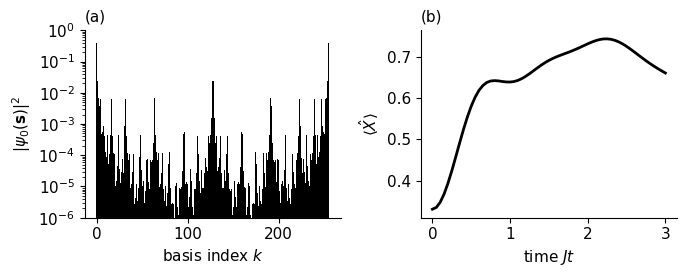

In [2]:
t_section = time.perf_counter()
N, J = 8, 1.0                                      # sites and coupling J (unit of energy and inverse time)
G_I, G_F = 0.5, 1.0                                # transverse field before (g_i) and after (g_f) the sudden change
DIM = 2 ** N                                       # 256 basis states
BITS = np.array(list(itertools.product([0, 1], repeat=N)))     # row k holds the bits (s_0, ..., s_7) of basis state k
CONF = (1 - 2 * BITS).astype(float)                # spins sigma_i = 1 - 2 s_i of all 256 configurations, shape (256, 8)
# FLIP[k, i] = index of bit string k with bit i flipped: bit i carries the value 2^(N-1-i), so flip it by exclusive or
FLIP = np.arange(DIM)[:, None] ^ (1 << (N - 1 - np.arange(N)))[None, :]
ROWS = np.repeat(np.arange(DIM), N)                # row k repeated N times, pairs with FLIP.ravel()
ISING = -J * np.sum(CONF[:, :-1] * CONF[:, 1:], axis=1)        # classical Ising energy -J sum sigma_i sigma_{i+1}

def hamiltonian(g):
    # equation (1) as a dense 256 x 256 matrix: Ising energy on the diagonal, -g between strings one flip apart
    H = np.diag(ISING)
    H[ROWS, FLIP.ravel()] = -g
    return H

X_MAT = np.zeros((DIM, DIM)); X_MAT[ROWS, FLIP.ravel()] = 1.0 / N       # equation (2): (1/N) sum_i sigma^x_i

# check (may be skipped): the same matrices from Kronecker products of 2 x 2 Pauli matrices, qubit 0 leftmost
I2, PX, PZ = np.eye(2), np.array([[0.0, 1.0], [1.0, 0.0]]), np.diag([1.0, -1.0])
def on_sites(ops):
    # Kronecker product with the 2 x 2 matrix ops[i] on site i and the unit matrix elsewhere
    out = np.ones((1, 1))
    for i in range(N):
        out = np.kron(out, ops.get(i, I2))
    return out
H_kron = -J * sum(on_sites({i: PZ, i + 1: PZ}) for i in range(N - 1)) - 0.7 * sum(on_sites({i: PX}) for i in range(N))
assert np.allclose(hamiltonian(0.7), H_kron)
assert np.allclose(X_MAT, sum(on_sites({i: PX}) for i in range(N)) / N)

# exact diagonalisation at both fields
H_I, H_F = hamiltonian(G_I), hamiltonian(G_F)
EV_I, U_I = np.linalg.eigh(H_I)                    # eigenvalues in ascending order, eigenvectors as columns
E0_I = EV_I[0]
PSI0 = U_I[:, 0] * np.sign(U_I[0, 0])              # exact ground state at g_i, overall sign chosen positive
EV_F, U_F = np.linalg.eigh(H_F)
C_F = U_F.T @ PSI0                                 # coefficients c_n = <n|psi_0> in the eigenbasis at g_f

# time grids: imaginary time in steps of 0.01 up to 6, real time in steps of 0.005 up to 3, recorded every 10 steps
DTAU, TAU_MAX, DT, T_MAX, EVERY = 0.01, 6.0, 0.005, 3.0, 10
TAU_GRID = DTAU * EVERY * np.arange(int(round(TAU_MAX / DTAU)) // EVERY + 1)     # 0, 0.1, ..., 6
T_GRID = DT * EVERY * np.arange(int(round(T_MAX / DT)) // EVERY + 1)             # 0, 0.05, ..., 3

def exact_state(t):
    # equation (3): every eigenstate of H(g_f) keeps its weight and acquires the phase exp(-i E_n t)
    return U_F @ (np.exp(-1j * EV_F * t) * C_F)

PSI_T = np.array([exact_state(t) for t in T_GRID])                       # shape (61, 256)
X_EXACT = np.einsum("ti,ij,tj->t", PSI_T.conj(), X_MAT, PSI_T).real      # <X>(t) = <psi(t)|X|psi(t)>
E_AFTER = float(PSI0 @ H_F @ PSI0)                                       # energy after the change, conserved
print(f"g_i = {G_I}: ground-state energy E_0 = {E0_I:.6f} J, gap to the first excited state {EV_I[1] - E0_I:.2e} J, "
      f"to the second {EV_I[2] - E0_I:.3f} J")
print(f"probability of all spins up and of all spins down in the ground state: {PSI0[0] ** 2:.4f}, {PSI0[-1] ** 2:.4f}")
print(f"g_f = {G_F}: energy of psi_0 after the change {E_AFTER:.6f} J (ground-state energy at g_f {EV_F[0]:.6f} J)")
W_F = np.abs(C_F) ** 2                                   # weights |c_n|^2 of psi_0 on the eigenstates of H(g_f)
N99 = int(np.searchsorted(np.cumsum(np.sort(W_F)[::-1]), 0.99) + 1)
print(f"weights of psi_0 on the eigenstates of H(g_f): largest {W_F.max():.3f}, number of eigenstates that hold 0.99 of the weight {N99}")
print(f"<X> at t = 0: {X_EXACT[0]:.4f};  minimum and maximum of <X>(t) for 0 <= t <= 3: {X_EXACT.min():.4f}, {X_EXACT.max():.4f}")

# --- figure (drawing code may be skipped) ---
def draw_ed_a(ax):
    ax.bar(np.arange(DIM), PSI0 ** 2, width=1.0, color=COL["exact"])
    ax.set_yscale("log"); ax.set_ylim(1e-6, 1)
    ax.set_xlabel(r"basis index $k$"); ax.set_ylabel(r"$|\psi_0(\mathbf{s})|^2$")
def draw_ed_b(ax):
    ax.plot(T_GRID, X_EXACT, color=COL["exact"], lw=2)
    ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"$\langle\hat X\rangle$")
panels("fig_lab088_ed_reference", [draw_ed_a, draw_ed_b])
TIMES["2 exact diagonalisation"] = time.perf_counter() - t_section

The ground-state energy at $g_i=0.5J$ is $\mathcal E_0=-7.6406\,J$ (printed as E_0). Panel (a) shows the Born probabilities $|\psi_0(\mathbf s)|^2$ of the 256 configurations on a logarithmic axis. The two ordered configurations, all spins up at $k=0$ and all spins down at $k=255$, carry most of the probability, and the rest is spread over configurations with a few flipped spins. The first excited state lies only $5.9\times10^{-3}J$ above the ground state, and Section 4 explains why the gap is so small. This state and the second excited state, printed at $1.174\,J$, change sign when all spins are flipped. Among the states that are unchanged by this flip, to which the evolutions of this notebook are restricted, the first excitation lies at $\Delta_8=1.18\,J$. After the change of the field the state $|\psi_0\rangle$ has its largest weight, 0.60, on the ground state of $\hat{\mathcal H}(g_f)$, and 10 eigenstates of $\hat{\mathcal H}(g_f)$ are needed to collect $0.99$ of its weight. The phases $e^{-i\mathcal E_nt}$ in equation (3) therefore turn with many different frequencies. Panel (b) shows that $\langle\hat X\rangle(t)$ rises quickly during the first time unit, as the spins turn towards the stronger field, and then changes more slowly up to $Jt=3$.

## 3. Imaginary-time evolution on two spins

The method that finds the ground state below works on any table of amplitudes, and we follow it first on the smallest one, two spins with $\hat{\mathcal H}=-J\hat\sigma^z_0\hat\sigma^z_1-g(\hat\sigma^x_0+\hat\sigma^x_1)$ at $g=J$. The four amplitudes $\psi(00),\psi(01),\psi(10),\psi(11)$ form a vector, and the Hamiltonian is a $4\times4$ matrix with the eigenvalues $-\sqrt5J$, $-J$, $J$ and $\sqrt5J$. The real-time evolution (3) multiplies the coefficient of each eigenstate by the phase $e^{-i\mathcal E_nt}$ of modulus one. Replacing $t$ by $-i\tau$ with a real $\tau\ge0$, called the imaginary time, turns the phases into real factors,
$$|\psi(\tau)\rangle=\frac{e^{-\tau\hat{\mathcal H}}|\psi(0)\rangle}{\big\|e^{-\tau\hat{\mathcal H}}|\psi(0)\rangle\big\|}=\frac{\sum_nc_n\,e^{-\mathcal E_n\tau}|n\rangle}{\big(\sum_n|c_n|^2e^{-2\mathcal E_n\tau}\big)^{1/2}} ,\qquad c_n=\langle n|\psi(0)\rangle , \tag{4}$$
where the denominator restores the norm. The factor $e^{-\mathcal E_n\tau}$ is largest for the lowest energy, so the weights of all excited states shrink relative to the weight of the ground state. Their ratio,
$$\frac{|c_n(\tau)|^2}{|c_0(\tau)|^2}=\frac{|c_n|^2}{|c_0|^2}\,e^{-2(\mathcal E_n-\mathcal E_0)\tau} , \tag{5}$$
decays exponentially with the rate $2(\mathcal E_n-\mathcal E_0)$. The slowest decay belongs to the lowest excited state with a nonzero weight at the start. Its gap $\Delta$ to the ground state sets the imaginary time needed to reach the ground state. The method needs a start with $c_0\neq0$, since a ground-state weight that is zero at the start stays zero.

The operator $e^{-\tau\hat{\mathcal H}}$ is the operator form of the Boltzmann factor $e^{-E/T}$ of the energy-based models of Lecture 14, whose energies $E$ were classical numbers. The weights in equation (4) carry the factor $e^{-2\mathcal E_n\tau}$, because a weight is the square of an amplitude, and $e^{-2\mathcal E_n\tau}$ is the Boltzmann factor $e^{-\mathcal E_n/T}$ at the temperature $T=1/(2\tau)$, with $k_B=1$. Following the state to large $\tau$ is therefore a cooling towards $T=0$, where only the ground state survives. The state $|\psi(\tau)\rangle$ stays a pure state, a single superposition of eigenstates with fixed relative phases, whose weights are the initial weights $|c_n|^2$ multiplied by these Boltzmann factors. A thermal state at the temperature $T$ would be the density matrix $e^{-\hat{\mathcal H}/T}/{\rm Tr}\,e^{-\hat{\mathcal H}/T}$, a mixture of all eigenstates that does not depend on any start.

We start from all spins up, $\psi(0)=(1,0,0,0)$, apply $e^{-\tau\hat{\mathcal H}}$ with the matrix exponential of SciPy [13] and divide by the norm. For every $\tau$ we record the four amplitudes, the energy $\mathcal E(\tau)=\langle\psi(\tau)|\hat{\mathcal H}|\psi(\tau)\rangle$ and the weights $|c_n(\tau)|^2$. The exact ground state has $\psi(01)/\psi(00)=\zeta$ with $\zeta=(\sqrt5-1)/2$, which Lab 080 derived from the condition that both local energies agree.

eigenvalues of H/J: [-2.2361 -1.      1.      2.2361]   (-sqrt5 = -2.2361 )
 tau    psi(00)  psi(01)  psi(10)  psi(11)    energy/J    weights |c_n|^2 for E_n = -sqrt5, -1, 1, sqrt5
 0.0     1.000    0.000    0.000    0.000     -1.0000     0.3618  0.5000  0.0000  0.1382
 0.5     0.906    0.280    0.280    0.150     -1.8692     0.7113  0.2856  0.0000  0.0031
 1.0     0.800    0.348    0.348    0.343     -2.1068     0.8955  0.1045  0.0000  0.0000
 2.0     0.668    0.370    0.370    0.529     -2.2240     0.9903  0.0097  0.0000  0.0000
 3.0     0.622    0.372    0.372    0.581     -2.2350     0.9992  0.0008  0.0000  0.0000
 4.0     0.607    0.372    0.372    0.596     -2.2360     0.9999  0.0001  0.0000  0.0000
psi(01)/psi(00) at tau = 4: 0.6120;  zeta = (sqrt5 - 1)/2 = 0.6180


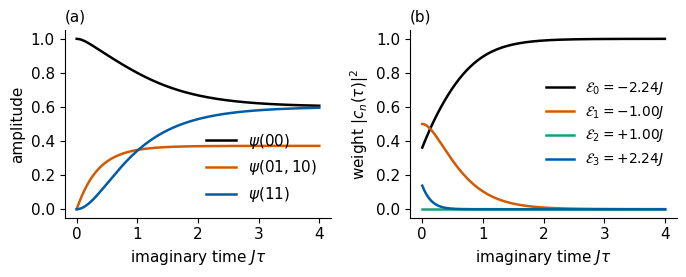

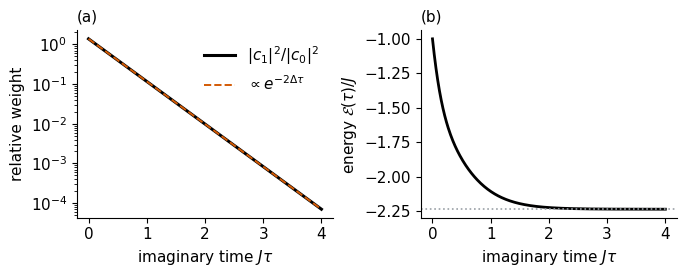

In [3]:
t_section = time.perf_counter()
# two spins at g = J: H = -J Z_0 Z_1 - g (X_0 + X_1), basis 00, 01, 10, 11 (qubit 0 leftmost)
g2 = 1.0
H2 = -J * np.kron(PZ, PZ) - g2 * (np.kron(PX, I2) + np.kron(I2, PX))
E2, V2 = np.linalg.eigh(H2)                        # eigenvalues -sqrt5, -1, 1, sqrt5 and eigenvectors (columns)
V2 = V2 * np.sign(V2[np.argmax(np.abs(V2), axis=0), np.arange(4)])     # sign of each eigenvector: largest entry positive
psi_start = np.array([1.0, 0.0, 0.0, 0.0])         # all spins up
ZETA = (np.sqrt(5) - 1) / 2

TAU2 = np.linspace(0.0, 4.0, 401)                  # imaginary times, step 0.01
AMP2, ENERGY2, WEIGHT2 = [], [], []
for tau in TAU2:
    v = expm(-tau * H2) @ psi_start                # e^{-tau H} |psi(0)>, equation (4) without the denominator
    v = v / np.linalg.norm(v)                      # the denominator of equation (4)
    AMP2.append(v); ENERGY2.append(v @ H2 @ v); WEIGHT2.append((V2.T @ v) ** 2)    # amplitudes, energy, |c_n(tau)|^2
AMP2, ENERGY2, WEIGHT2 = map(np.array, (AMP2, ENERGY2, WEIGHT2))

print("eigenvalues of H/J:", np.round(E2, 4), "  (-sqrt5 =", round(-np.sqrt(5), 4), ")")
print(" tau    psi(00)  psi(01)  psi(10)  psi(11)    energy/J    weights |c_n|^2 for E_n = -sqrt5, -1, 1, sqrt5")
for tau in (0.0, 0.5, 1.0, 2.0, 3.0, 4.0):
    n = int(round(tau / 0.01))
    print(f" {tau:3.1f}   " + "  ".join(f"{x:7.3f}" for x in AMP2[n]) + f"   {ENERGY2[n]:9.4f}     "
          + "  ".join(f"{x:.4f}" for x in WEIGHT2[n]))
print(f"psi(01)/psi(00) at tau = 4: {AMP2[-1, 1] / AMP2[-1, 0]:.4f};  zeta = (sqrt5 - 1)/2 = {ZETA:.4f}")
# relative weight of the first excited state with nonzero weight (E = -J) and the prediction (5)
DELTA2 = E2[1] - E2[0]                             # gap sqrt5 - 1
ratio2 = WEIGHT2[:, 1] / WEIGHT2[:, 0]
ratio2_formula = WEIGHT2[0, 1] / WEIGHT2[0, 0] * np.exp(-2 * DELTA2 * TAU2)
assert np.allclose(ratio2, ratio2_formula, rtol=1e-8)

# --- figure (drawing code may be skipped) ---
def draw_two_a(ax):
    for n_, (lab, c) in enumerate(zip(["00", "01, 10", None, "11"], [COL["exact"], COL["sums"], None, COL["netket"]])):
        if lab is not None:
            ax.plot(TAU2, AMP2[:, n_], color=c, lw=1.8, label=rf"$\psi({lab})$")
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel("amplitude"); ax.legend(frameon=False)
def draw_two_b(ax):
    for n_, c in enumerate([COL["exact"], COL["sums"], COL["teal"], COL["netket"]]):
        ax.plot(TAU2, WEIGHT2[:, n_], color=c, lw=1.8, label=rf"$\mathcal{{E}}_{n_}={E2[n_]:+.2f}J$")
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel(r"weight $|c_n(\tau)|^2$"); ax.legend(frameon=False, fontsize=10)
panels("fig_lab088_two_spins_weights", [draw_two_a, draw_two_b])
def draw_rate_a(ax):
    ax.semilogy(TAU2, ratio2, color=COL["exact"], lw=2.2, label=r"$|c_1|^2/|c_0|^2$")
    ax.semilogy(TAU2, ratio2_formula, color=COL["sums"], lw=1.4, ls="--", label=r"$\propto e^{-2\Delta\tau}$")
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel("relative weight"); ax.legend(frameon=False)
def draw_rate_b(ax):
    ax.plot(TAU2, ENERGY2, color=COL["exact"], lw=2)
    ax.axhline(-np.sqrt(5), color=COL["grey"], ls=":", lw=1.2)
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel(r"energy $\mathcal{E}(\tau)/J$")
panels("fig_lab088_two_spins_rate", [draw_rate_a, draw_rate_b])

Panel (a) of the first figure shows the four amplitudes. The amplitude of $00$ falls from one, the amplitudes of $01$ and $10$ grow first, because the field connects them with $00$ by one flip, and the amplitude of $11$ follows with a delay, because it needs two flips. At $\tau=4/J$ the ratio $\psi(01)/\psi(00)$ has reached $0.612$, close to $\zeta\approx0.618$. Panel (b) shows the weights on the four eigenstates. The weight of the highest state disappears first and the weight of the state at $-J$ more slowly. The state at $+J$ is antisymmetric under the exchange of the two spins, whereas the start is symmetric, so its weight stays zero. In the second figure, panel (a) shows the weight of the state at $-J$ relative to the ground state on a logarithmic axis. It falls on the straight line $e^{-2\Delta\tau}$ with the gap $\Delta=(\sqrt5-1)J$, as equation (5) predicts. Panel (b) shows the energy, which decreases from $-J$ towards $-\sqrt5J$.

The operator $e^{-\tau\hat{\mathcal H}}$ is not unitary, so it changes the length of the vector. Without the denominator of equation (4) the squared norm is
$$\langle\psi|\psi\rangle(\tau)=\sum_n|c_n|^2e^{-2\mathcal E_n\tau} , \tag{6}$$
which grows when the occupied energies are negative and shrinks when they are positive. For the two spins the ground-state term grows as $e^{2\sqrt5J\tau}$. A computer follows the evolution in small steps $d\tau$. Expanding $e^{-d\tau\hat{\mathcal H}}\approx1-d\tau\hat{\mathcal H}$ and writing the result for one amplitude gives
$$\psi(\mathbf s,\tau+d\tau)=\psi(\mathbf s)-d\tau\sum_{\mathbf s'}\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle\,\psi(\mathbf s')=\psi(\mathbf s)\big[1-d\tau\,E_{\rm loc}(\mathbf s)\big] ,\qquad E_{\rm loc}(\mathbf s)=\sum_{\mathbf s'}\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle\frac{\psi(\mathbf s')}{\psi(\mathbf s)} . \tag{7}$$
The local energy $E_{\rm loc}(\mathbf s)$ of Lab 080 appears here as the rate at which the amplitude of configuration $\mathbf s$ changes. Configurations with a high local energy lose amplitude, and configurations with a low local energy gain amplitude. The second form of equation (7) needs $\psi(\mathbf s)\neq0$, and for a configuration with zero amplitude, such as $01$ at the start, the first form applies. If we subtract the energy $\mathcal E=\langle\psi|\hat{\mathcal H}|\psi\rangle/\langle\psi|\psi\rangle$ from every local energy,
$$\psi(\mathbf s,\tau+d\tau)=\psi(\mathbf s)\big[1-d\tau\big(E_{\rm loc}(\mathbf s)-\mathcal E\big)\big] , \tag{8}$$
every amplitude is multiplied by the same additional factor $1+d\tau\,\mathcal E$ to first order in $d\tau$. This factor leaves the direction of the vector unchanged and compensates the change of the norm. The step (8) is $|\psi\rangle\to|\psi\rangle-d\tau(\hat{\mathcal H}-\mathcal E)|\psi\rangle$, and to first order
$$\frac{d\langle\psi|\psi\rangle}{d\tau}=-2\langle\psi|\hat{\mathcal H}|\psi\rangle+2\,\mathcal E\,\langle\psi|\psi\rangle=0 . \tag{9}$$
We follow the two spins from all spins up with steps $d\tau=0.01/J$ of both kinds, (7) and (8), and record the squared norm without ever dividing by it.

squared norm at tau = 4:  exact e^(-tau H) 2.125e+07,  Euler steps (7) 1.745e+07,  Euler steps (8) 1.006250
largest |norm - 1| along the steps (8): 6.25e-03
psi(01)/psi(00) after the steps (8): 0.6122, after the exact evolution 0.6120


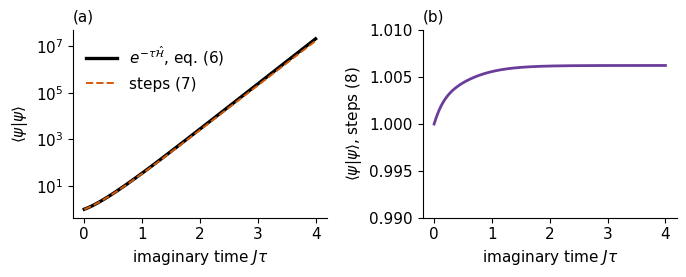

In [4]:
# Euler steps (7) and (8) on the two spins, d tau = 0.01, the vector is never renormalised
d_tau2 = 0.01
NORM_EXACT2 = np.array([np.linalg.norm(expm(-tau * H2) @ psi_start) ** 2 for tau in TAU2])    # equation (6)

def euler_two_spins(subtract):
    v, norms = psi_start.copy(), [1.0]
    for _ in range(len(TAU2) - 1):
        Hv = H2 @ v                                # sum_s' <s|H|s'> psi(s'), the first form of equation (7)
        E = (v @ Hv) / (v @ v)                     # energy of the current vector
        v = v - d_tau2 * (Hv - E * v) if subtract else v - d_tau2 * Hv    # equation (8) or equation (7)
        norms.append(v @ v)
    return v, np.array(norms)

v_plain, NORM_PLAIN2 = euler_two_spins(subtract=False)
v_sub, NORM_SUB2 = euler_two_spins(subtract=True)
print(f"squared norm at tau = 4:  exact e^(-tau H) {NORM_EXACT2[-1]:.3e},  Euler steps (7) {NORM_PLAIN2[-1]:.3e},  "
      f"Euler steps (8) {NORM_SUB2[-1]:.6f}")
print(f"largest |norm - 1| along the steps (8): {np.max(np.abs(NORM_SUB2 - 1)):.2e}")
print(f"psi(01)/psi(00) after the steps (8): {v_sub[1] / v_sub[0]:.4f}, after the exact evolution {AMP2[-1, 1] / AMP2[-1, 0]:.4f}")

# --- figure (drawing code may be skipped) ---
def draw_norm_a(ax):
    ax.semilogy(TAU2, NORM_EXACT2, color=COL["exact"], lw=2.4, label=r"$e^{-\tau\hat{\mathcal{H}}}$, eq. (6)")
    ax.semilogy(TAU2, NORM_PLAIN2, color=COL["sums"], lw=1.4, ls="--", label="steps (7)")
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel(r"$\langle\psi|\psi\rangle$"); ax.legend(frameon=False)
def draw_norm_b(ax):
    ax.plot(TAU2, NORM_SUB2, color=COL["snap"], lw=2)
    ax.set_ylim(0.99, 1.01)
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel(r"$\langle\psi|\psi\rangle$, steps (8)")
panels("fig_lab088_norm", [draw_norm_a, draw_norm_b])
TIMES["3 imaginary time on two spins"] = time.perf_counter() - t_section

Panel (a) shows the squared norm without the denominator of equation (4) on a logarithmic axis. It grows to $2.1\times10^7$ at $\tau=4/J$. The Euler steps (7) follow this growth and end at $1.7\times10^7$, and the difference is the error of steps of first order. Panel (b) shows the squared norm for the steps (8), which stays within $6\times10^{-3}$ of one. For a normalised state the step (8) changes the squared norm by $d\tau^2\langle(\hat{\mathcal H}-\mathcal E)^2\rangle$, the square of the step times the energy variance. The curve therefore flattens as the state approaches the ground state, where the variance vanishes. After the steps (8) the ratio $\psi(01)/\psi(00)$ is $0.612$, as after the exact evolution. The subtraction removed the change of length and left the direction of the vector on the same path.

The network below never has to be normalised, because every average is taken with the Born probabilities $p(\mathbf s)=|\psi(\mathbf s)|^2/Z$, in which the norm $Z=\sum_{\mathbf s}|\psi(\mathbf s)|^2$ cancels. The subtraction of the average local energy returns in Section 6, where it fixes the free constant of the network's step. In real time the first-order step is $\psi(\mathbf s)\big[1-i\,dt\,E_{\rm loc}(\mathbf s)\big]$, and the norm is conserved automatically, because $d\langle\psi|\psi\rangle/dt=i\langle\psi|\hat{\mathcal H}|\psi\rangle-i\langle\psi|\hat{\mathcal H}|\psi\rangle=0$. Subtracting $\mathcal E$ there multiplies every amplitude by the phase $e^{i\mathcal E\,dt}$, which is a global phase without physical effect.

## 4. RBM amplitude with complex parameters

The network of Lab 080 assigns to the configuration $\mathbf s$ with spins $\sigma_i=1-2s_i$ the amplitude
$$\psi_{\boldsymbol\theta}(\mathbf s)=\exp\Big(\sum_ia_i\sigma_i\Big)\prod_{j=1}^{M}2\cosh u_j(\mathbf s),\qquad u_j(\mathbf s)=b_j+\sum_iw_{ij}\sigma_i , \tag{10}$$
with $M$ hidden units, visible biases $a_i$, hidden biases $b_j$ and weights $w_{ij}$. Each factor $2\cosh u_j$ is the sum of $e^{h_ju_j}$ over the two values $h_j=\pm1$ of hidden unit $j$, and $u_j$ is the input that this hidden unit receives from the spins. We collect the parameters in the vector $\boldsymbol\theta=(a,b,w)$ with $N_{\rm p}=N+M+NM$ entries $\theta_k$. In Lab 080 the parameters were real, which suffices for the ground state of this chain, because all its amplitudes are positive. After the change of the field the amplitudes acquire phases, as the factors $e^{-i\mathcal E_nt}$ in equation (3) show, whereas a network with real parameters returns only positive numbers. We therefore make all parameters complex, so that the amplitude (10) is a complex number with a modulus and a phase. For $N=8$ and $M=8$ the network has $N_{\rm p}=80$ complex parameters for the 256 complex amplitudes.

A change of one parameter changes the amplitude by a fraction given by the logarithmic derivative $O_k(\mathbf s)=\partial\ln\psi_{\boldsymbol\theta}(\mathbf s)/\partial\theta_k$. With $\ln\psi_{\boldsymbol\theta}=\sum_ia_i\sigma_i+\sum_j\ln(2\cosh u_j)$ and $d\ln(2\cosh u)/du=\tanh u$,
$$O_{a_i}(\mathbf s)=\sigma_i,\qquad O_{b_j}(\mathbf s)=\tanh u_j(\mathbf s),\qquad O_{w_{ij}}(\mathbf s)=\sigma_i\tanh u_j(\mathbf s) . \tag{11}$$
The amplitude depends on each complex parameter only through the exponential and the hyperbolic cosine, with no complex conjugation. The derivatives (11) are therefore complex derivatives with the same formulas as for real parameters. The code stores $\ln\psi$, which turns the product (10) into a sum, and evaluates $\ln(2\cosh u)$ in a form that cannot overflow for large $|u|$. We check equation (11) against finite differences of $\ln\psi$ at random complex parameters.

In [5]:
t_section = time.perf_counter()

def log2cosh(u):
    # ln(2 cosh u) = s u + ln(1 + e^{-2 s u}) with s = sign(Re u): the exponential never overflows
    s = np.where(u.real >= 0, 1.0, -1.0)
    return s * u + np.log1p(np.exp(-2 * s * u))

def unpack(theta, M):
    # theta = (a_0..a_{N-1}, b_1..b_M, W_00..W_{N-1,M}) -> a shape (N,), b shape (M,), W shape (N, M)
    return theta[:N], theta[N:N + M], theta[N + M:].reshape(N, M)

def log_psi(theta, M, sigma):
    # logarithm of equation (10) for configurations sigma of shape (n, N); also returns the inputs u, shape (n, M)
    a, b, W = unpack(theta, M)
    u = b + sigma @ W
    return sigma @ a + np.sum(log2cosh(u), axis=1), u

def log_derivatives(theta, M, sigma):
    # equation (11): one row per configuration, one column per parameter, shape (n, P), same order as theta
    _, u = log_psi(theta, M, sigma)
    t = np.tanh(u)                                                  # tanh u_j(s), shape (n, M)
    O_W = (sigma[:, :, None] * t[:, None, :]).reshape(len(sigma), N * M)   # sigma_i tanh u_j, flattened like W
    return np.concatenate([sigma.astype(complex), t, O_W], axis=1)

def state_vector(theta, M):
    # the 256 amplitudes of the network, normalised to one (used only for comparisons with exact results)
    lp, _ = log_psi(theta, M, CONF)
    v = np.exp(lp - lp.real.max())
    return v / np.linalg.norm(v)

def initial_parameters(M, seed=1, random_b=False):
    # a = 0, b = 0, W real and normal with standard deviation 0.1, stored as complex numbers; psi(-s) = psi(s).
    # random_b=True draws b with standard deviation 1 after W, so W is the same as for a = b = 0 (Section 4)
    rng = np.random.default_rng(seed)
    W = 0.1 * rng.normal(size=N * M)
    b = 1.0 * rng.normal(size=M) if random_b else np.zeros(M)
    return np.concatenate([np.zeros(N), b, W]).astype(complex)

# check (may be skipped): equation (11) against central finite differences at random complex parameters, M = 8
rng_check = np.random.default_rng(0)
theta_test = 0.1 * (rng_check.normal(size=N + 8 + 8 * N) + 1j * rng_check.normal(size=N + 8 + 8 * N))
O_test = log_derivatives(theta_test, 8, CONF)
eps_fd, err_O = 1e-6, 0.0
for k in range(len(theta_test)):
    e = np.zeros_like(theta_test); e[k] = eps_fd
    numeric = (log_psi(theta_test + e, 8, CONF)[0] - log_psi(theta_test - e, 8, CONF)[0]) / (2 * eps_fd)
    err_O = max(err_O, np.max(np.abs(numeric - O_test[:, k])))
print(f"largest difference between equation (11) and finite differences over 256 configurations and 80 parameters: {err_O:.1e}")
assert err_O < 1e-8

largest difference between equation (11) and finite differences over 256 configurations and 80 parameters: 9.2e-10


The derivatives agree with the finite differences to the accuracy of the difference quotient.

The initial parameters are $a_i=0$, $b_j=0$ and real weights $w_{ij}$ drawn from a normal distribution with standard deviation $0.1$ and seed 1, so the initial state is close to equal amplitudes. The zero biases respect the symmetry of the chain under the operator $\hat R=\prod_i\hat\sigma^x_i$, which flips all spins at once and commutes with $\hat{\mathcal H}(g)$, because flipping all spins leaves every product $\sigma_i\sigma_{i+1}$ unchanged. Every eigenstate is therefore even, $\psi(-\boldsymbol\sigma)=\psi(\boldsymbol\sigma)$, or odd, $\psi(-\boldsymbol\sigma)=-\psi(\boldsymbol\sigma)$. In the ordered phase the ground state is even, and the lowest odd state lies only $\Delta\approx6\times10^{-3}J$ above it, because the two states are the symmetric and the antisymmetric combination of the same two ordered configurations. By equation (5) an odd admixture shrinks only at the rate $2\Delta$ and would need an imaginary time of the order of $1/\Delta\approx170/J$ to disappear.

With $a=b=0$ the amplitude (10) is even for any weights, because $\cosh$ is even and $u_j(-\mathbf s)=-u_j(\mathbf s)$. The derivatives $O_{a_i}$ and $O_{b_j}$ are then odd functions of the spins, and $O_{w_{ij}}$ and $E_{\rm loc}$ are even. An odd function times an even one averages to zero over the even $p(\mathbf s)$. The covariance matrix $S$ and the force $f$, which Section 6 builds from such averages, therefore split into a block of the odd parameters $(a,b)$ and a block of the even parameters $W$ with no entries of $S$ between the two blocks, and the force on $(a,b)$ vanishes. The velocities of $a$ and $b$ are then zero, and with exact sums the network stays even during the whole evolution.

To see what the symmetric start avoids, we compare it with a second start with the same weights $w_{ij}$ and with hidden biases $b_j$ drawn from a normal distribution with standard deviation 1. The 256 amplitudes of each start form a vector $|\psi_{\boldsymbol\theta_0}\rangle$, which we evolve exactly in imaginary time with $\hat{\mathcal H}(g_i)$, as we did for the two spins. These exact curves show what imaginary time does to each start when every amplitude can change freely, and Section 9 sets the network's own evolution beside them. We evaluate equation (4) with the eigenvectors of $\hat{\mathcal H}(g_i)$ up to $\tau=6/J$ and record the relative energy error $(\mathcal E(\tau)-\mathcal E_0)/|\mathcal E_0|$ and the infidelity $1-|\langle\psi_0|\psi(\tau)\rangle|^2$ with the exact ground state.

start with a = b = 0: largest |psi(-s) - psi(s)| = 0.0e+00, weights on the two lowest eigenstates of H(g_i) 0.0892 (even) and 6.20e-27 (odd), ratio odd/even 6.95e-26
start with random b: largest |psi(-s) - psi(s)| = 8.5e-02, weights on the two lowest eigenstates of H(g_i) 0.0787 (even) and 6.70e-05 (odd), ratio odd/even 8.51e-04
  tau = 0.0:  relative energy error 4.88e-01 (a = b = 0), 4.96e-01 (random b);  infidelity 9.11e-01 (a = b = 0),  9.21e-01 (random b)
  tau = 1.0:  relative energy error 3.11e-02 (a = b = 0), 3.32e-02 (random b);  infidelity 1.87e-01 (a = b = 0),  1.97e-01 (random b)
  tau = 2.0:  relative energy error 3.12e-03 (a = b = 0), 3.25e-03 (random b);  infidelity 2.01e-02 (a = b = 0),  2.16e-02 (random b)
  tau = 4.0:  relative energy error 2.81e-05 (a = b = 0), 2.95e-05 (random b);  infidelity 1.82e-04 (a = b = 0),  9.98e-04 (random b)
  tau = 6.0:  relative energy error 2.50e-07 (a = b = 0), 8.64e-07 (random b);  infidelity 1.62e-06 (a = b = 0),  7.94e-04 (random b)

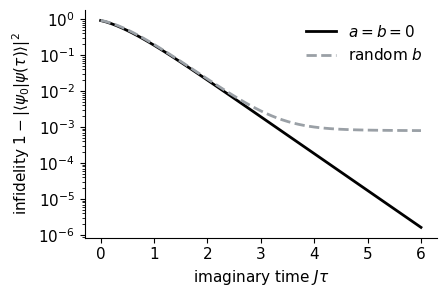

In [6]:
M_MAIN = 8                                          # hidden units of the main runs
THETA0 = initial_parameters(M_MAIN)                 # initial parameters theta_0: a = b = 0, seed 1
THETA0_B = initial_parameters(M_MAIN, random_b=True)    # second start with random hidden biases b
P_FLIP = np.arange(DIM)[::-1]                       # index of the configuration with all spins flipped
for name, th in (("a = b = 0", THETA0), ("random b", THETA0_B)):
    v = state_vector(th, M_MAIN)
    w_even, w_odd = abs(U_I[:, 0] @ v) ** 2, abs(U_I[:, 1] @ v) ** 2
    print(f"start with {name}: largest |psi(-s) - psi(s)| = {np.max(np.abs(v[P_FLIP] - v)):.1e}, "
          f"weights on the two lowest eigenstates of H(g_i) {w_even:.4f} (even) and {w_odd:.2e} (odd), ratio odd/even {w_odd / w_even:.2e}")

def exact_imaginary_time(psi_start, taus):
    # equation (4) in the eigenbasis of H(g_i); E_0 is subtracted in the exponent, which changes only the norm
    c = U_I.T @ psi_start
    states = np.array([U_I @ (np.exp(-(EV_I - E0_I) * tau) * c) for tau in taus])
    return states / np.linalg.norm(states, axis=1, keepdims=True)

IMAG_EXACT = {}
for name, th in (("even", THETA0), ("random b", THETA0_B)):
    states = exact_imaginary_time(state_vector(th, M_MAIN), TAU_GRID)
    IMAG_EXACT[name] = dict(E=np.einsum("ti,ij,tj->t", states.conj(), H_I, states).real, infid=1 - np.abs(states @ PSI0) ** 2)
E_IMAG_EXACT = IMAG_EXACT["even"]["E"]
for tau in (0.0, 1.0, 2.0, 4.0, 6.0):
    n = int(round(tau / 0.1))
    print(f"  tau = {tau:3.1f}:  relative energy error {(E_IMAG_EXACT[n] - E0_I) / abs(E0_I):.2e} (a = b = 0), "
          f"{(IMAG_EXACT['random b']['E'][n] - E0_I) / abs(E0_I):.2e} (random b);  infidelity "
          f"{IMAG_EXACT['even']['infid'][n]:.2e} (a = b = 0),  {IMAG_EXACT['random b']['infid'][n]:.2e} (random b)")

# --- figure (drawing code may be skipped) ---
def draw_imag_exact(ax):
    ax.semilogy(TAU_GRID, IMAG_EXACT["even"]["infid"], color=COL["exact"], lw=2, label="$a=b=0$")
    ax.semilogy(TAU_GRID, IMAG_EXACT["random b"]["infid"], color=COL["grey"], lw=2, ls="--", label="random $b$")
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel(r"infidelity $1-|\langle\psi_0|\psi(\tau)\rangle|^2$")
    ax.legend(frameon=False)
one_panel("fig_lab088_imag_exact_start", draw_imag_exact)
TIMES["4 network and exact imaginary time"] = time.perf_counter() - t_section

The symmetric start has no weight on the odd state, up to rounding, whereas the start with random $b$ has the weight $6.7\times10^{-5}$ there, against $0.079$ on the ground state. The figure shows the infidelity of the exact imaginary-time evolution for both starts. Up to $\tau\approx2/J$ the two curves agree, because both starts lose their higher excited states at the same rates. Beyond that the symmetric start keeps approaching the ground state, whereas the start with random $b$ levels off at $7.9\times10^{-4}$. Once the other excited states have decayed, only the ground state and the odd state remain, and the infidelity approaches the ratio of the odd to the ground-state weight, $8.5\times10^{-4}$, reduced by the factor $e^{-2\Delta\tau}\approx0.93$ by which the odd weight has decayed at $\tau=6/J$. The energy errors of the two starts at $\tau=6/J$ are both small, because the odd state lies only $\Delta$ above the ground state, so the energy alone hardly reveals the admixture.

## 5. Local values of the energy and of the magnetisation

For complex amplitudes the Born probability of a snapshot is $p(\mathbf s)=|\psi(\mathbf s)|^2/Z$ with $Z=\sum_{\mathbf s}|\psi(\mathbf s)|^2$. The expectation value of an operator $\hat A$ with matrix elements $A_{\mathbf s\mathbf s'}=\langle\mathbf s|\hat A|\mathbf s'\rangle$ becomes an average over these probabilities. We insert $\sum_{\mathbf s}|\mathbf s\rangle\langle\mathbf s|$ on both sides of $\hat A$ and multiply and divide each term by $\psi(\mathbf s)$,
$$\langle\hat A\rangle=\frac{\sum_{\mathbf s,\mathbf s'}\psi^*(\mathbf s)\,A_{\mathbf s\mathbf s'}\,\psi(\mathbf s')}{Z}=\sum_{\mathbf s}\underbrace{\frac{|\psi(\mathbf s)|^2}{Z}}_{p(\mathbf s)}\;\underbrace{\sum_{\mathbf s'}A_{\mathbf s\mathbf s'}\frac{\psi(\mathbf s')}{\psi(\mathbf s)}}_{A_{\rm loc}(\mathbf s)} . \tag{12}$$
For $\hat{\mathcal H}$ the local value is the local energy of equation (7). With the matrix elements of the chain, the local energy and the local value of the magnetisation (2) are
$$E_{\rm loc}(\mathbf s)=-J\sum_{i=0}^{N-2}\sigma_i\sigma_{i+1}-g\sum_{i=0}^{N-1}\frac{\psi(\mathbf s^{(i)})}{\psi(\mathbf s)},\qquad X_{\rm loc}(\mathbf s)=\frac1N\sum_{i=0}^{N-1}\frac{\psi(\mathbf s^{(i)})}{\psi(\mathbf s)} . \tag{13}$$
Both need only the $N$ ratios of amplitudes one flip apart, which the code obtains by evaluating $\ln\psi$ at the flipped configurations. For complex amplitudes the local values are complex numbers. Because the expectation value of a Hermitian operator is real, their imaginary parts average to zero over $p(\mathbf s)$. We implement equation (13) and check it at random complex parameters against $(\hat{\mathcal H}\psi)(\mathbf s)/\psi(\mathbf s)$ and $(\hat X\psi)(\mathbf s)/\psi(\mathbf s)$ computed with the matrices of Section 2.

In [7]:
def local_values(theta, M, g, sigma):
    # equation (13) for configurations sigma (n, N): E_loc(s) and X_loc(s) from the N one-flip ratios psi(s^(i)) / psi(s)
    lp, _ = log_psi(theta, M, sigma)
    ratios = np.empty((len(sigma), N), dtype=complex)
    for i in range(N):
        flipped = sigma.copy(); flipped[:, i] *= -1                  # the configurations s^(i)
        ratios[:, i] = np.exp(log_psi(theta, M, flipped)[0] - lp)    # psi(s^(i)) / psi(s) = exp(ln psi(s^(i)) - ln psi(s))
    e_loc = -J * np.sum(sigma[:, :-1] * sigma[:, 1:], axis=1) - g * ratios.sum(axis=1)
    return e_loc, ratios.mean(axis=1)

# check (may be skipped): equation (13) against the matrices, at the random complex parameters of the previous check
psi_test = np.exp(log_psi(theta_test, 8, CONF)[0])
e_test, x_test = local_values(theta_test, 8, G_F, CONF)
err_E = np.max(np.abs(H_F @ psi_test / psi_test - e_test))
err_X = np.max(np.abs(X_MAT @ psi_test / psi_test - x_test))
p_test = np.abs(psi_test) ** 2 / np.sum(np.abs(psi_test) ** 2)
print(f"largest difference of E_loc from (H psi)/psi: {err_E:.1e};  of X_loc from (X psi)/psi: {err_X:.1e}")
print(f"average of E_loc over p(s): {p_test @ e_test:.6f}  (imaginary part zero to rounding),  "
      f"<psi|H|psi>/<psi|psi> = {np.vdot(psi_test, H_F @ psi_test).real / np.vdot(psi_test, psi_test).real:.6f}")
print(f"one configuration, s = 00000000: E_loc = {e_test[0]:.4f},  X_loc = {x_test[0]:.4f}")
assert err_E < 1e-12 and err_X < 1e-12

largest difference of E_loc from (H psi)/psi: 5.3e-15;  of X_loc from (X psi)/psi: 4.7e-16
average of E_loc over p(s): -7.609713+0.000000j  (imaginary part zero to rounding),  <psi|H|psi>/<psi|psi> = -7.609713
one configuration, s = 00000000: E_loc = -14.8250-0.9097j,  X_loc = 0.9781+0.1137j


The local values agree with the matrix calculation to rounding error, and their average over $p(\mathbf s)$ is the real expectation value even though a single local value is complex.

## 6. One step of the evolution as a least-squares fit

Equation (7) and its real-time version describe one small step of the exact evolution as a multiplication of every amplitude by its own factor,
$$\psi(\mathbf s,t+dt)=\psi(\mathbf s)\big[1-i\,dt\,E_{\rm loc}(\mathbf s)\big]\ \ \text{(real time)},\qquad \psi(\mathbf s,\tau+d\tau)=\psi(\mathbf s)\big[1-d\tau\,E_{\rm loc}(\mathbf s)\big]\ \ \text{(imaginary time)} . \tag{14}$$
The real-time form follows from $e^{-i\,dt\,\hat{\mathcal H}}\approx1-i\,dt\,\hat{\mathcal H}$ in the same way as equation (7). The factor of each configuration contains its own local energy, so an exact step changes the 256 amplitudes independently of each other. The network can change only its $N_{\rm p}$ parameters. A small change $\boldsymbol\theta\to\boldsymbol\theta+dt\,\dot{\boldsymbol\theta}$ with the parameter velocity $\dot{\boldsymbol\theta}$ changes the logarithm of every amplitude by $dt\sum_k\dot\theta_kO_k(\mathbf s)$ to first order, so that
$$\psi_{\boldsymbol\theta+dt\,\dot{\boldsymbol\theta}}(\mathbf s)=\psi_{\boldsymbol\theta}(\mathbf s)\exp\Big(dt\sum_k\dot\theta_kO_k(\mathbf s)\Big)\approx\psi_{\boldsymbol\theta}(\mathbf s)\Big[1+dt\sum_k\dot\theta_kO_k(\mathbf s)\Big] . \tag{15}$$
Comparing equations (14) and (15), the network follows the exact real-time step when
$$\sum_k\dot\theta_k\,O_k(\mathbf s)\approx-i\,E_{\rm loc}(\mathbf s)+\kappa\qquad\text{for every configuration }\mathbf s , \tag{16}$$
where $\kappa$ is a constant common to all configurations. A constant $\kappa$ multiplies every amplitude by the same factor $e^{dt\,\kappa}$, whose real part changes the norm and whose imaginary part changes the global phase. It leaves the physical state unchanged and can be chosen freely. Equation (16) contains 256 conditions for $N_{\rm p}=80$ unknowns and in general has no exact solution. We choose $\dot{\boldsymbol\theta}$ and $\kappa$ that minimise the squared mismatch weighted with the Born probabilities,
$$\mathcal L(\dot{\boldsymbol\theta},\kappa)=\sum_{\mathbf s}p(\mathbf s)\,\Big|\sum_k\dot\theta_kO_k(\mathbf s)-\kappa+i\,E_{\rm loc}(\mathbf s)\Big|^2 . \tag{17}$$
Configurations with a large probability count more. Subtracting the exact step (14) from the network step (15), with the factor $e^{dt\,\kappa}$ included in the exact step, leaves $dt\,\psi(\mathbf s)\big[\sum_k\dot\theta_kO_k(\mathbf s)-\kappa+iE_{\rm loc}(\mathbf s)\big]$ for every configuration. The squared length of this difference, divided by $Z$, is $dt^2\mathcal L$, so $\mathcal L$ measures the distance in Hilbert space between the exactly evolved state and the network after the step. Minimising this distance is the variational principle of McLachlan [2].

We solve the fit first for a single real parameter in imaginary time, where the target in equation (16) is $-E_{\rm loc}(\mathbf s)+\kappa$ and all quantities are real. The ordinary derivative of $\mathcal L$ with respect to $\kappa$ vanishes for $\kappa=\dot\theta\langle O\rangle+\langle E_{\rm loc}\rangle$, where $\langle\cdot\rangle$ is the average over $p(\mathbf s)$. Inserting this $\kappa$ replaces every quantity by its deviation from its average, $\delta O(\mathbf s)=O(\mathbf s)-\langle O\rangle$ and $\delta E_{\rm loc}(\mathbf s)=E_{\rm loc}(\mathbf s)-\langle E_{\rm loc}\rangle$,
$$\mathcal L(\dot\theta)=\sum_{\mathbf s}p(\mathbf s)\big[\dot\theta\,\delta O(\mathbf s)+\delta E_{\rm loc}(\mathbf s)\big]^2 . \tag{18}$$
The subtracted average $\langle E_{\rm loc}\rangle=\mathcal E$ is the subtraction of equation (8), which kept the norm fixed. The derivative $d\mathcal L/d\dot\theta=2\sum_{\mathbf s}p(\mathbf s)\,\delta O(\mathbf s)\big[\dot\theta\,\delta O(\mathbf s)+\delta E_{\rm loc}(\mathbf s)\big]$ vanishes for
$$\dot\theta=-\frac{\langle\delta O\,\delta E_{\rm loc}\rangle}{\langle\delta O^2\rangle}=-\frac{{\rm cov}(O,E_{\rm loc})}{{\rm var}(O)} , \tag{19}$$
which is the slope of the straight line that fits the targets $-\delta E_{\rm loc}(\mathbf s)$ against $\delta O(\mathbf s)$ by a linear regression weighted with $p(\mathbf s)$.

The two spins of Section 3 at $g=J$ give an example. The table $\psi_\theta=(1,e^\theta,e^\theta,1)$ for the configurations $00,01,10,11$ has one parameter, $\theta=\ln\zeta$ with $\zeta=\psi(01)/\psi(00)$, and the logarithmic derivative $O=(0,1,1,0)$. At $\theta=0$ all four probabilities are $1/4$, so $\langle O\rangle=1/2$, $\delta O=(-\tfrac12,\tfrac12,\tfrac12,-\tfrac12)$ and ${\rm var}(O)=1/4$. Equation (13) for two spins gives $E_{\rm loc}=(-3J,-J,-J,-3J)$ with the average $-2J$, so $\delta E_{\rm loc}=(-J,J,J,-J)$ and ${\rm cov}(O,E_{\rm loc})=J/2$. Equation (19) gives $\dot\theta=-2J$. The exact step (8) multiplies $\psi(00)$ by $1+J\,d\tau$ and $\psi(01)$ by $1-J\,d\tau$, so $\zeta$ changes by the factor $(1-J\,d\tau)/(1+J\,d\tau)\approx1-2J\,d\tau$, and $\theta=\ln\zeta$ changes at the rate $-2J$, the same value. In real time the target $-i\,\delta E_{\rm loc}$ gives in the same way the velocity $-2iJ$. We compute these numbers and compare both rates with the change of $\ln\zeta$ under the matrix exponential of the two-spin Hamiltonian.

In [8]:
t_section = time.perf_counter()
# the one-parameter fit (19) on two spins at g = J and theta = 0, against the exact rate of ln zeta
O1 = np.array([0.0, 1.0, 1.0, 0.0])                # d ln psi / d theta for psi = (1, e^theta, e^theta, 1), basis 00, 01, 10, 11
psi1 = np.ones(4)                                   # the table at theta = 0
p1 = psi1 ** 2 / np.sum(psi1 ** 2)                  # Born probabilities, all 1/4
eloc1 = (H2 @ psi1) / psi1                          # local energies, second form of equation (7)
dO1, dE1 = O1 - p1 @ O1, eloc1 - p1 @ eloc1         # deviations from the averages
var1, cov1 = p1 @ dO1 ** 2, p1 @ (dO1 * dE1)        # var(O) and cov(O, E_loc)
print(f"E_loc/J = {eloc1},  var(O) = {var1:.4f},  cov(O, E_loc) = {cov1:.4f} J")
print(f"equation (19): imaginary time theta_dot = {-cov1 / var1:.4f} J,  real time theta_dot = {-1j * cov1 / var1:.4f} J")
h = 1e-6                                            # a short step of the exact evolution
for label, U in (("imaginary time", expm(-h * H2)), ("real time", expm(-1j * h * H2))):
    v = U @ psi1
    rate = np.log(complex(v[1] / v[0])) / h         # change of ln zeta = ln(psi(01)/psi(00)) per unit time
    print(f"{label}: exact rate of ln zeta {rate.real:+.4f} {rate.imag:+.4f}i  J")

E_loc/J = [-3. -1. -1. -3.],  var(O) = 0.2500,  cov(O, E_loc) = 0.5000 J
equation (19): imaginary time theta_dot = -2.0000 J,  real time theta_dot = 0.0000-2.0000j J
imaginary time: exact rate of ln zeta -2.0000 +0.0000i  J
real time: exact rate of ln zeta -0.0000 -2.0000i  J


The fit (19) gives the exact rate of $\ln\zeta$ in both kinds of time, because the exact step of the two spins changes only the ratio $\zeta$, which the single parameter can follow.

For $N_{\rm p}$ parameters we collect the weighted deviations in a matrix $A$ with 256 rows and $N_{\rm p}$ columns, $A_{\mathbf sk}=\sqrt{p(\mathbf s)}\,\delta O_k(\mathbf s)$ with $\delta O_k(\mathbf s)=O_k(\mathbf s)-\langle O_k\rangle$, and the weighted targets in a vector $y$, with $y_{\mathbf s}=-\sqrt{p(\mathbf s)}\,\delta E_{\rm loc}(\mathbf s)$ in imaginary time and $y_{\mathbf s}=-i\sqrt{p(\mathbf s)}\,\delta E_{\rm loc}(\mathbf s)$ in real time. The constant $\kappa$ is eliminated in the same way, now $\kappa=\sum_k\dot\theta_k\langle O_k\rangle+i\langle E_{\rm loc}\rangle$ in real time, and the fit (17) becomes the linear least-squares problem
$$\mathcal L(\dot{\boldsymbol\theta})=\sum_{\mathbf s}\Big|\sum_kA_{\mathbf sk}\,\dot\theta_k-y_{\mathbf s}\Big|^2 \tag{20}$$
with 256 equations for $N_{\rm p}$ unknowns. For real parameters and imaginary time all entries are real, and setting the $N_{\rm p}$ ordinary derivatives $\partial\mathcal L/\partial\dot\theta_k$ to zero gives the normal equations $A^{\rm T}A\,\dot{\boldsymbol\theta}=A^{\rm T}y$, which reduce to equation (19) for one parameter.

For complex parameters each velocity $\dot\theta_k=\alpha_k+i\beta_k$ has two real unknowns $\alpha_k$ and $\beta_k$. The pair $(\dot\theta_k,\dot\theta_k^*)$ follows from $(\alpha_k,\beta_k)$ by an invertible linear map, so $\mathcal L$ can be written as a function of $\dot\theta_k$ and $\dot\theta_k^*$ in which the two are varied independently. Since $\partial/\partial\dot\theta_k^*=\tfrac12(\partial/\partial\alpha_k+i\,\partial/\partial\beta_k)$, both real derivatives vanish exactly when the derivative with respect to $\dot\theta_k^*$ at fixed $\dot\theta_k$ vanishes. In equation (20) the conjugate velocities appear only in the complex conjugate of the bracket, so this derivative is $\sum_{\mathbf s}A_{\mathbf sk}^*\big(\sum_lA_{\mathbf sl}\dot\theta_l-y_{\mathbf s}\big)$, and the normal equations read $A^\dagger A\,\dot{\boldsymbol\theta}=A^\dagger y$. Written out with $S=A^\dagger A$, they are
$$\sum_lS_{kl}\,\dot\theta_l=-i\,f_k\ \ \text{(real time)},\qquad \sum_lS_{kl}\,\dot\theta_l=-f_k\ \ \text{(imaginary time)},\qquad S_{kl}=\big\langle\delta O_k^*\,\delta O_l\big\rangle ,\qquad f_k=\big\langle\delta O_k^*\,\delta E_{\rm loc}\big\rangle . \tag{21}$$
The matrix $S$ is the $N_{\rm p}\times N_{\rm p}$ covariance matrix of the logarithmic derivatives over $p(\mathbf s)$, and the force $f$ is the covariance of each $O_k$ with the local energy. Equations (21) are the time-dependent variational principle for a variational wave function. It was used for time evolution with variational Monte Carlo in Ref. [3] and with neural quantum states in Refs. [1] and [7]. Reference [4] compares it with other variational principles, and Ref. [6] derives it in detail.

We look at the fit for the initial network with $M=8$ in imaginary time at $g_i$. The averages are exact sums over all 256 configurations. The code computes $\delta O_k$, $\delta E_{\rm loc}$, $S$ and $f$ and solves the least-squares problem (20) directly. We print six configurations and three of the 80 parameters, together with the target $-\delta E_{\rm loc}(\mathbf s)$ and the fitted value $\sum_k\dot\theta_k\delta O_k(\mathbf s)$, and check that the solution satisfies the normal equations (21).

initial network, M = 8, imaginary time at g_i = 0.5; all quantities are real for real parameters
   s           p(s)     E_loc(s)   dO_a0    dO_b1   dO_W01  ...   target -dE_loc   fit sum_k thetadot_k dO_k
  00000000   0.0031   -11.219    1.000    0.116    0.028  ...      7.309            7.345
  00000001   0.0039    -8.988    1.000    0.120    0.032  ...      5.079            5.076
  00001111   0.0035    -9.105    1.000   -0.318   -0.407  ...      5.195            5.198
  01010101   0.0046     3.164    1.000    0.520    0.432  ...     -7.074           -7.086
  10101010   0.0046     3.164   -1.000   -0.520    0.432  ...     -7.074           -7.086
  11111111   0.0031   -11.219   -1.000   -0.116    0.028  ...      7.309            7.345
weighted relative residual of the fit, sum p |fit - target|^2 / sum p |target|^2: 4.55e-05
the solution satisfies S theta_dot = -f up to 1.8e-14 (relative)
eigenvalues of S: largest 1.43e+00, smallest 8.24e-08, ratio 5.8e-08
real-time step at g_f: relati

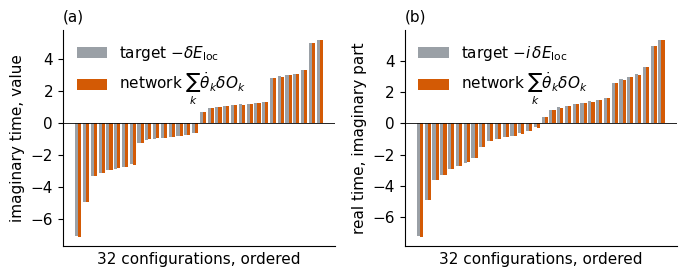

In [9]:
def born_probabilities(theta, M):
    # p(s) = |psi(s)|^2 / Z on all 256 configurations; the largest ln|psi| is subtracted to avoid overflow
    lp, _ = log_psi(theta, M, CONF)
    p = np.exp(2 * (lp.real - lp.real.max()))
    return p / p.sum()

def fit_ingredients(theta, M, g):
    # delta O_k(s), delta E_loc(s), S and f of equations (20) and (21), averages as exact sums over all configurations
    p = born_probabilities(theta, M)
    e_loc, _ = local_values(theta, M, g, CONF)
    O = log_derivatives(theta, M, CONF)
    dO = O - p @ O                                  # deviations from the averages <O_k>, shape (256, P)
    dE = e_loc - p @ e_loc                          # deviations from <E_loc> = energy, shape (256,)
    S = (dO.conj().T * p) @ dO                      # S_kl = sum_s p(s) dO_k*(s) dO_l(s), shape (P, P)
    f = (dO.conj().T * p) @ dE                      # f_k  = sum_s p(s) dO_k*(s) dE(s),   shape (P,)
    return p, e_loc, dO, dE, S, f

def least_squares_velocity(p, dO, target):
    # minimise sum_s p(s) |sum_k theta_dot_k dO_k(s) - target(s)|^2, equation (20): rows of A = sqrt(p) dO
    theta_dot, *_ = np.linalg.lstsq(np.sqrt(p)[:, None] * dO, np.sqrt(p) * target, rcond=None)
    return theta_dot

p0, e0, dO0, dE0, S0, f0 = fit_ingredients(THETA0, M_MAIN, G_I)
target_imag = -dE0                                  # imaginary time: target -delta E_loc(s)
vel_imag = least_squares_velocity(p0, dO0, target_imag)
fit_imag = dO0 @ vel_imag                           # fitted value sum_k theta_dot_k delta O_k(s)
normal_eq_error = np.max(np.abs(S0 @ vel_imag + f0)) / np.max(np.abs(f0))
resid_imag = (p0 @ np.abs(fit_imag - target_imag) ** 2) / (p0 @ np.abs(target_imag) ** 2)
lam0 = np.linalg.eigvalsh(S0)

SHOW = [0, 1, 15, 85, 170, 255]                     # six configurations, by basis index k
iW01 = N + M_MAIN + 0 * M_MAIN + 1                  # position of W_{0,1} in theta
print(f"initial network, M = {M_MAIN}, imaginary time at g_i = {G_I}; all quantities are real for real parameters")
print("   s           p(s)     E_loc(s)   dO_a0    dO_b1   dO_W01  ...   target -dE_loc   fit sum_k thetadot_k dO_k")
for k in SHOW:
    print(f"  {''.join(map(str, BITS[k]))}   {p0[k]:.4f}   {e0[k].real:7.3f}   {dO0[k, 0].real:6.3f}   {dO0[k, N + 1].real:6.3f}"
          f"   {dO0[k, iW01].real:6.3f}  ...    {target_imag[k].real:7.3f}          {fit_imag[k].real:7.3f}")
print(f"weighted relative residual of the fit, sum p |fit - target|^2 / sum p |target|^2: {resid_imag:.2e}")
print(f"the solution satisfies S theta_dot = -f up to {normal_eq_error:.1e} (relative)")
print(f"eigenvalues of S: largest {lam0[-1]:.2e}, smallest {lam0[0]:.2e}, ratio {lam0[0] / lam0[-1]:.1e}")

# the real-time step with H(g_f) from the same parameters: target -i delta E_loc(s), equation (21)
_, _, _, dE0_F, _, f0_F = fit_ingredients(THETA0, M_MAIN, G_F)
target_real = -1j * dE0_F
vel_real = least_squares_velocity(p0, dO0, target_real)
fit_real = dO0 @ vel_real
resid_real = (p0 @ np.abs(fit_real - target_real) ** 2) / (p0 @ np.abs(target_real) ** 2)
print(f"real-time step at g_f: relative residual {resid_real:.2e}; largest |Re| of the fitted values {np.max(np.abs(fit_real.real)):.1e}, "
      f"largest |Im| of the parameter velocity {np.max(np.abs(vel_real.imag)):.2f}, largest |Re| {np.max(np.abs(vel_real.real)):.1e}")

# --- figure (drawing code may be skipped) ---
FIT_ORDER = np.argsort(target_imag.real)[::8]       # 32 configurations, ordered by their target value
def draw_fit(ax, target, fit, ylabel, target_label):
    x = np.arange(len(FIT_ORDER))
    ax.bar(x - 0.2, target[FIT_ORDER], width=0.4, color=COL["grey"], label=target_label)
    ax.bar(x + 0.2, fit[FIT_ORDER], width=0.4, color=COL["sums"], label=r"network $\sum_k\dot\theta_k\delta O_k$")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xlabel("32 configurations, ordered"); ax.set_ylabel(ylabel); ax.set_xticks([]); ax.legend(frameon=False, loc="upper left")
panels("fig_lab088_least_squares",
       [lambda ax: draw_fit(ax, target_imag.real, fit_imag.real, "imaginary time, value", r"target $-\delta E_{\rm loc}$"),
        lambda ax: draw_fit(ax, target_real.imag, fit_real.imag, "real time, imaginary part", r"target $-i\,\delta E_{\rm loc}$")])

For real parameters the amplitudes and all printed quantities are real. The column $\delta O_{a_0}$ is $\sigma_0$ minus its average, which vanishes for the even state, and the other two columns vary from configuration to configuration through $\tanh u_j$. The fitted values follow the targets to within a few hundredths, and the weighted relative residual of the whole fit is $4.6\times10^{-5}$, so at this start the 80 parameters follow the exact imaginary-time step of all 256 amplitudes closely. The figure shows target and fit for 32 configurations, every eighth after ordering all 256 by their target. Panel (a) is the imaginary-time step. Configurations with a low local energy, on the right, receive a positive factor and gain amplitude, and configurations with a high local energy lose it. Panel (b) is the real-time step with $\hat{\mathcal H}(g_f)$ from the same parameters, whose target $-i\,\delta E_{\rm loc}(\mathbf s)$ is purely imaginary, and it shows the imaginary parts. The network fits this target equally well, with a relative residual of $4.4\times10^{-5}$, using purely imaginary parameter velocities. The eigenvalues of $S$ range from $1.4$ down to $8\times10^{-8}$.

## 7. Imaginary time as stochastic reconfiguration

The simplest integration of the imaginary-time equation (21) is the Euler step with a finite $d\tau$,
$$\boldsymbol\theta\;\to\;\boldsymbol\theta-d\tau\,S^{-1}f . \tag{22}$$
To compare it with gradient descent we need the gradient of the energy $\mathcal E=\sum_{\mathbf s\mathbf s'}\psi^*(\mathbf s)\,H_{\mathbf s\mathbf s'}\,\psi(\mathbf s')/Z$, with $H_{\mathbf s\mathbf s'}=\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle$. The amplitude (10) contains the parameters without complex conjugation, so $\psi$ depends only on the $\theta_k$ and $\psi^*$ only on the $\theta_k^*$, and we treat $\theta_k$ and $\theta_k^*$ as independent variables, as we did for the velocities in Section 6. The derivative with respect to $\theta_k$ at fixed $\theta_k^*$ acts on $\psi(\mathbf s')$, where it gives $O_k(\mathbf s')\psi(\mathbf s')$, and on $Z$, where it gives $-\mathcal E\langle O_k\rangle$. For the Hermitian $\hat{\mathcal H}$ the sum $\sum_{\mathbf s}\psi^*(\mathbf s)H_{\mathbf s\mathbf s'}$ equals $E_{\rm loc}^*(\mathbf s')\,\psi^*(\mathbf s')$, so
$$\frac{\partial\mathcal E}{\partial\theta_k}=\big\langle E_{\rm loc}^*\,O_k\big\rangle-\mathcal E\,\langle O_k\rangle=\big\langle\delta E_{\rm loc}^*\,\delta O_k\big\rangle=f_k^* ,\qquad \frac{d\mathcal E}{d\theta_k}=\frac{\partial\mathcal E}{\partial\theta_k}+\frac{\partial\mathcal E}{\partial\theta_k^*}=2\,{\rm Re}\,f_k\quad\text{(real parameters)} . \tag{23}$$
The second form holds for real parameters, because a real change of $\theta_k$ changes $\theta_k$ and $\theta_k^*$ together. For a real $\psi$ the force is real, so the gradient of the energy is $\partial_k\mathcal E=2f_k$, the same gradient that Lab 080b used for training, and plain gradient descent with the step size $\eta$ reads $\boldsymbol\theta\to\boldsymbol\theta-2\eta f$. The Euler step (22) of imaginary time is gradient descent with the gradient multiplied by $S^{-1}$. Sorella introduced this method under the name stochastic reconfiguration [5], and Ref. [1] used it for the ground state of the network.

The matrix $S$ measures how much the normalised state changes when the parameters change. By equation (15) a change $d\boldsymbol\theta$ multiplies each amplitude by $1+\sum_kd\theta_kO_k(\mathbf s)$. The averages $\langle O_k\rangle$ only change the norm and the global phase, and the remaining change of the normalised state has the squared length
$$\sum_{\mathbf s}p(\mathbf s)\,\Big|\sum_kd\theta_k\,\delta O_k(\mathbf s)\Big|^2=\sum_{kl}d\theta_k^*\,S_{kl}\,d\theta_l \tag{24}$$
to second order in $d\boldsymbol\theta$. Equation (24) is the squared distance between the normalised states at $\boldsymbol\theta$ and $\boldsymbol\theta+d\boldsymbol\theta$, measured after the change of the global phase has been removed. Multiplying the gradient by $S^{-1}$ measures the step in this distance, so parameters that barely change the state may move far and parameters that change it strongly move little.

For the initial network, which is real, we check the real-parameter gradient (23) by finite differences of the exact energy and compare the directions of $S^{-1}f$ and $f$.

In [10]:
def exact_energy(theta, M, H):
    # <psi|H|psi> / <psi|psi> from the 256 amplitudes, used for checks and diagnostics only
    v = state_vector(theta, M)
    return float(np.vdot(v, H @ v).real)

grad_fd = np.zeros(len(THETA0))
for k in range(len(THETA0)):
    e = np.zeros_like(THETA0); e[k] = 1e-6          # a real change of parameter k
    grad_fd[k] = (exact_energy(THETA0 + e, M_MAIN, H_I) - exact_energy(THETA0 - e, M_MAIN, H_I)) / 2e-6
err_grad = np.max(np.abs(grad_fd - 2 * f0.real)) / np.max(np.abs(grad_fd))
sr_direction = np.linalg.lstsq(S0, f0, rcond=None)[0].real      # S^{-1} f
cosine = sr_direction @ f0.real / (np.linalg.norm(sr_direction) * np.linalg.norm(f0.real))
print(f"largest relative difference between the finite-difference gradient and 2 f: {err_grad:.1e}")
print(f"cosine of the angle between S^-1 f and f: {cosine:.3f};  length ratio |S^-1 f| / |f| = "
      f"{np.linalg.norm(sr_direction) / np.linalg.norm(f0.real):.1f}")
assert err_grad < 1e-6

largest relative difference between the finite-difference gradient and 2 f: 2.1e-09
cosine of the angle between S^-1 f and f: 0.200;  length ratio |S^-1 f| / |f| = 35.1


The finite-difference gradient equals $2f$ to the accuracy of the difference quotient. The direction $S^{-1}f$ of the imaginary-time step makes with the gradient direction $f$ an angle whose cosine is only $0.20$, and $S^{-1}f$ is 35 times longer. Imaginary time therefore moves the parameters far along directions in which the state changes little per unit change of the parameters, and plain gradient descent would follow these directions only slowly.

## 8. Solving for the velocity and integrating in time

The eigenvalues of $S$ printed in Section 6 span many orders of magnitude. $S$ is a covariance matrix, so for every vector $v$ the number $v^\dagger Sv=\big\langle|\sum_kv_k\,\delta O_k|^2\big\rangle$ is non-negative. Its eigenvalues $\lambda_m$ are therefore non-negative, and with orthonormal eigenvectors $v_m$ it reads $S=\sum_m\lambda_m\,v_mv_m^\dagger$. By equation (24) an eigenvector with a tiny eigenvalue is a combination of parameter changes that hardly changes the normalised state. An example is a pair of hidden units that respond to the spins in nearly the same way. The solution of equation (21) has the component $-i\,(v_m^\dagger f)/\lambda_m$ along each eigenvector in real time and $-(v_m^\dagger f)/\lambda_m$ in imaginary time. A small error in $f$, from sampling or from rounding, is divided by a tiny $\lambda_m$ and produces a large velocity in a direction that hardly changes the state. We therefore add to the fit (20) a penalty on the length of the velocity,
$$\mathcal L_\epsilon(\dot{\boldsymbol\theta})=\sum_{\mathbf s}\Big|\sum_kA_{\mathbf sk}\,\dot\theta_k-y_{\mathbf s}\Big|^2+\epsilon\,\lambda_{\max}\sum_k|\dot\theta_k|^2 , \tag{25}$$
where $\lambda_{\max}$ is the largest eigenvalue of $S$. The penalty grows with the squared length of the velocity, so among velocities that fit the rows almost equally well it selects the shortest. The derivative with respect to $\dot\theta_k^*$ adds $\epsilon\lambda_{\max}\dot\theta_k$ to the normal equations,
$$\big(S+\epsilon\,\lambda_{\max}\mathbb 1\big)\,\dot{\boldsymbol\theta}=-i\,f , \tag{26}$$
where $\mathbb 1$ is the unit matrix, with $-f$ on the right in imaginary time. Along an eigenvector of $S$ the component becomes $-i\,(v_m^\dagger f)/(\lambda_m+\epsilon\lambda_{\max})$, so directions with $\lambda_m\gg\epsilon\lambda_{\max}$ keep their velocity and directions with $\lambda_m\ll\epsilon\lambda_{\max}$ are damped. The shift is measured in units of $\lambda_{\max}$, so it follows the scale of $S$ as the parameters change. It also changes smoothly with the parameters, as the integrator below requires. We use $\epsilon=10^{-6}$ for exact sums and $\epsilon=10^{-4}$ for snapshots.

With exact sums the real-time flow keeps the energy of the network fixed. The energy depends on $\boldsymbol\theta$ and $\boldsymbol\theta^*$, so along the flow it changes as
$$\frac{d\mathcal E}{dt}=\sum_k\Big(\frac{\partial\mathcal E}{\partial\theta_k}\dot\theta_k+\text{c.c.}\Big)=2\,{\rm Re}\sum_kf_k^*\dot\theta_k=2\,{\rm Re}\Big[-i\,f^\dagger\big(S+\epsilon\lambda_{\max}\mathbb 1\big)^{-1}f\Big]=0 , \tag{27}$$
where c.c. denotes the complex conjugate of the preceding term and $\partial\mathcal E/\partial\theta_k=f_k^*$ is equation (23). The last step uses that $f^\dagger Bf$ is real for the Hermitian matrix $B=(S+\epsilon\lambda_{\max}\mathbb 1)^{-1}$. Conservation holds for every Hermitian $B$, with or without the shift, and for any quality of the fit, so the energy drift of a computed run measures the error of the finite time step alone. In imaginary time the same calculation gives $d\mathcal E/d\tau=-2f^\dagger Bf\le0$, since $B$ is positive definite, so the energy can only decrease.

Between two evaluations of the velocity the parameters move along a curve, and the Euler step (22) follows its tangent. The Runge–Kutta method of fourth order, which goes back to Ref. [12], evaluates the velocity four times per step, at the start, twice at the midpoint and at the end,
$$k_1=\dot{\boldsymbol\theta}(\boldsymbol\theta),\quad k_2=\dot{\boldsymbol\theta}\big(\boldsymbol\theta+\tfrac h2k_1\big),\quad k_3=\dot{\boldsymbol\theta}\big(\boldsymbol\theta+\tfrac h2k_2\big),\quad k_4=\dot{\boldsymbol\theta}(\boldsymbol\theta+hk_3),\qquad \boldsymbol\theta\to\boldsymbol\theta+\tfrac h6\big(k_1+2k_2+2k_3+k_4\big) , \tag{28}$$
with the step $h=d\tau$ or $h=dt$, and its error after a fixed time falls as $h^4$. We use $d\tau=0.01/J$ up to $\tau=6/J$ and $dt=0.005/J$ up to $t=3/J$.

The function `velocity` collects equations (12), (13), (21) and (26). It receives an object that returns configurations and their weights in the averages. For exact sums the configurations are all 256 bit strings with the weights $p(\mathbf s)$, and Section 10 provides a second object with snapshots and equal weights. Besides the velocity it returns the estimated energy and magnetisation and the relative residual of the fit. We check that equation (26) is the least-squares problem (25) by appending $\sqrt{\epsilon\lambda_{\max}}$ times the unit matrix to the rows of $A$ and solving with the least-squares routine of NumPy. We then evaluate $d\mathcal E/d\tau$ of equation (27) for the imaginary-time velocity at $\boldsymbol\theta_0$ and plot the eigenvalues of $S$ for the initial network.

equation (26) against the least-squares problem (25): largest relative difference 6.8e-12
dE/dtau of equation (27) at theta_0, imaginary time: -14.534 J^2
eigenvalues of S at theta_0 below eps lambda_max: 11 for eps = 1e-6, 44 for eps = 1e-4 (of 80)


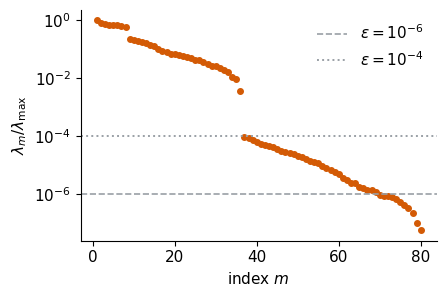

In [11]:
class ExactSums:
    # averages over p(s) as exact sums over all 2^N configurations (possible only for small N)
    name, eps = "exact sums", 1e-6
    def __init__(self, eps=None):
        if eps is not None:
            self.eps = eps                                   # a different shift for this object only
    def configurations(self, theta, M):
        return CONF, born_probabilities(theta, M)          # configurations and their weights p(s)

def velocity(theta, M, g, real_time, averages):
    # parameter velocity of equation (26): (S + eps lambda_max 1) theta_dot = -i f (real time) or -f (imaginary time)
    sigma, w = averages.configurations(theta, M)            # configurations and weights of the averages <.>
    e_loc, x_loc = local_values(theta, M, g, sigma)         # equation (13)
    O = log_derivatives(theta, M, sigma)                    # equation (11)
    dO = O - w @ O                                          # Delta O_k(s)
    dE = e_loc - w @ e_loc                                  # Delta E_loc(s)
    S = (dO.conj().T * w) @ dO                              # S_kl = <Delta O_k* Delta O_l>
    f = (dO.conj().T * w) @ dE                              # f_k  = <Delta O_k* Delta E_loc>
    rhs = -1j * f if real_time else -f                      # right-hand side of equation (21)
    shift = averages.eps * np.linalg.eigvalsh(S)[-1]        # eps times the largest eigenvalue of S
    theta_dot = np.linalg.solve(S + shift * np.eye(len(S)), rhs)
    target = (-1j if real_time else -1.0) * dE              # target of the fit, equation (16) minus its average
    residual = (w @ np.abs(dO @ theta_dot - target) ** 2) / (w @ np.abs(target) ** 2)
    return theta_dot, dict(E=w @ e_loc, X=w @ x_loc, residual=residual, dEdt=2 * np.real(np.vdot(f, theta_dot)),
                           dEdt_scale=2 * np.sum(np.abs(f) * np.abs(theta_dot)))      # dE/dt of (27) and the size of its terms

def rk4_step(theta, M, g, h, real_time, averages):
    # equation (28); the estimates returned belong to the start of the step
    k1, info = velocity(theta, M, g, real_time, averages)
    k2, _ = velocity(theta + 0.5 * h * k1, M, g, real_time, averages)
    k3, _ = velocity(theta + 0.5 * h * k2, M, g, real_time, averages)
    k4, _ = velocity(theta + h * k3, M, g, real_time, averages)
    return theta + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4), info

# check (may be skipped): equation (26) is the regularised least-squares problem (25)
vel_check, info_check = velocity(THETA0, M_MAIN, G_F, True, ExactSums())
shift0 = ExactSums.eps * np.linalg.eigvalsh(fit_ingredients(THETA0, M_MAIN, G_F)[4])[-1]
A_ridge = np.vstack([np.sqrt(p0)[:, None] * dO0, np.sqrt(shift0) * np.eye(len(THETA0))])      # rows of the fit + penalty rows
b_ridge = np.concatenate([np.sqrt(p0) * target_real, np.zeros(len(THETA0))])
vel_ridge, *_ = np.linalg.lstsq(A_ridge, b_ridge, rcond=None)
err_ridge = np.max(np.abs(vel_check - vel_ridge)) / np.max(np.abs(vel_ridge))
_, info_imag = velocity(THETA0, M_MAIN, G_I, False, ExactSums())
print(f"equation (26) against the least-squares problem (25): largest relative difference {err_ridge:.1e}")
print(f"dE/dtau of equation (27) at theta_0, imaginary time: {info_imag['dEdt']:.3f} J^2")
print(f"eigenvalues of S at theta_0 below eps lambda_max: {int(np.sum(lam0 < 1e-6 * lam0[-1]))} for eps = 1e-6, "
      f"{int(np.sum(lam0 < 1e-4 * lam0[-1]))} for eps = 1e-4 (of {len(lam0)})")

# --- figure (drawing code may be skipped) ---
def draw_spectrum0(ax):
    ax.semilogy(np.arange(1, len(lam0) + 1), lam0[::-1] / lam0[-1], "o", ms=4, color=COL["sums"])
    ax.axhline(1e-6, color=COL["grey"], ls="--", lw=1.2, label=r"$\epsilon=10^{-6}$")
    ax.axhline(1e-4, color=COL["grey"], ls=":", lw=1.4, label=r"$\epsilon=10^{-4}$")
    ax.set_xlabel(r"index $m$"); ax.set_ylabel(r"$\lambda_m/\lambda_{\max}$"); ax.legend(frameon=False)
one_panel("fig_lab088_S_spectrum", draw_spectrum0)
TIMES["6-8 fit, stochastic reconfiguration, solver"] = time.perf_counter() - t_section

Equation (26) and the least-squares problem (25) give the same velocity to rounding error, and the imaginary-time velocity lowers the energy, as equation (27) states. The figure shows the 80 eigenvalues of $S$ at $\boldsymbol\theta_0$, divided by the largest one, with the two shifts as horizontal lines. The shift $\epsilon=10^{-6}$ damps the 11 smallest directions, and $\epsilon=10^{-4}$ damps 44 of them.

## 9. Ground state and evolution with exact sums

We run the whole protocol first with the averages as exact sums. Starting from the symmetric initial parameters of Section 4, the network evolves in imaginary time with $\hat{\mathcal H}(g_i)$ for 600 steps up to $\tau=6/J$. Its final state is the network's ground state. From there it evolves in real time with $\hat{\mathcal H}(g_f)$ for 600 steps up to $t=3/J$. Every ten steps the code records the estimates of the energy and of $\langle\hat X\rangle$, which come from the same averages that drive the evolution, and a set of diagnostics. The diagnostics use the 256 amplitudes of the network and the exact results of Section 2, and they never enter the evolution. In imaginary time they are the energy of the network state and its infidelity with the exact ground state. In real time they are its $\langle\hat X\rangle$, its energy and the infidelity $1-|\langle\psi(t)|\psi_{\boldsymbol\theta(t)}\rangle|^2$ with the exactly evolved state. The function `evolve` also stores the parameters every $0.1/J$ of real time, which Sections 14 and 15 use. For comparison we also run the imaginary-time part from the second start of Section 4, with random hidden biases.

At $\boldsymbol\theta_0$ the parameters and the force are real and the real-time velocity is purely imaginary, so every term of equation (27) vanishes on its own. We therefore check equation (27) at the complex parameters reached at $t=3/J$.

exact sums, M = 8: relative ground-state energy error 2.33e-06, infidelity at t = 0 3.67e-06, max |<X>_network - <X>_exact| 0.0103, infidelity at t = 3 1.97e-02, energy drift 3.3e-07 J, 13 s
after imaginary time: largest imaginary part of the parameters 0.0e+00, largest |a_i|, |b_j| 2.4e-15
start with random b, exact sums: relative energy error at tau = 6 1.56e-05, infidelity 6.70e-04 (symmetric start: 3.67e-06), 6 s
equation (27) at the parameters of t = 3: dE/dt = -4.5e-14 J^2;  sum of the moduli of its terms, 2 sum_k |f_k| |thetadot_k| = 5.24e+01 J^2;  largest |Im theta| = 2.62


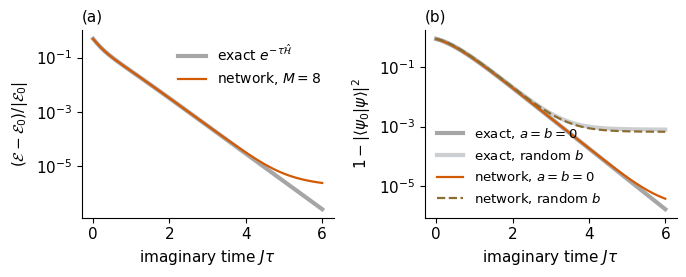

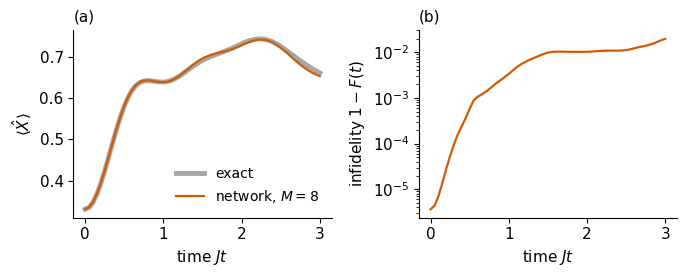

In [12]:
def evolve(M, averages, theta_start, real_time_part=True):
    # imaginary time with H(g_i) up to TAU_MAX, then real time with H(g_f) up to T_MAX; records every EVERY steps
    theta = theta_start.copy()
    rec = {key: [] for key in ("E_net", "E_est", "inf_imag", "X_net", "X_est", "infid", "residual", "E_real", "thetas")}
    t0 = time.perf_counter()
    n_imag, n_real = int(round(TAU_MAX / DTAU)), int(round(T_MAX / DT))
    for n in range(n_imag + 1):
        if n % EVERY == 0:
            v = state_vector(theta, M)                                         # diagnostics from the 256 amplitudes
            rec["E_net"].append(np.vdot(v, H_I @ v).real); rec["inf_imag"].append(1 - abs(PSI0 @ v) ** 2)
        if n < n_imag:
            theta, info = rk4_step(theta, M, G_I, DTAU, False, averages)       # imaginary time, equation (21)
            if n % EVERY == 0:
                rec["E_est"].append(info["E"].real)                            # estimate from the averages
    rec["theta_ground"] = theta.copy()
    rec["imag_part_max"] = float(np.max(np.abs(theta.imag)))                   # parameters stay real in imaginary time
    rec["ab_max"] = float(np.max(np.abs(theta[:N + M])))                       # largest |a_i|, |b_j| (zero for an even state)
    for n in range(n_real + 1 if real_time_part else 0):
        if n % EVERY == 0:
            v = state_vector(theta, M)
            rec["X_net"].append(np.vdot(v, X_MAT @ v).real)                    # diagnostic, exact <X> of the network
            rec["infid"].append(1 - abs(np.vdot(PSI_T[n // EVERY], v)) ** 2)   # diagnostic, against equation (3)
            rec["E_real"].append(np.vdot(v, H_F @ v).real)                     # energy, conserved by the flow (25)
        if n % (2 * EVERY) == 0:
            rec["thetas"].append(theta.copy())                                 # parameters every 0.1 / J
        if n < n_real:
            theta, info = rk4_step(theta, M, G_F, DT, True, averages)          # real time, equation (21)
            if n % EVERY == 0:
                rec["X_est"].append(info["X"].real); rec["residual"].append(info["residual"])
    rec = {k: (np.array(v) if isinstance(v, list) else v) for k, v in rec.items()}
    rec["seconds"] = time.perf_counter() - t0
    rec["gs_rel_err"] = (rec["E_net"][-1] - E0_I) / abs(E0_I)
    return rec

def report(name, r):
    # one line per run with the numbers quoted in the text
    print(f"{name}: relative ground-state energy error {r['gs_rel_err']:.2e}, infidelity at t = 0 {r['infid'][0]:.2e}, "
          f"max |<X>_network - <X>_exact| {np.max(np.abs(r['X_net'] - X_EXACT)):.4f}, infidelity at t = 3 {r['infid'][-1]:.2e}, "
          f"energy drift {np.max(np.abs(r['E_real'] - r['E_real'][0])):.1e} J, {r['seconds']:.0f} s")

def gs_err_at(r, tau):
    # relative energy error of the network at imaginary time tau (recorded every 0.1 / J)
    return (r["E_net"][int(round(tau / (DTAU * EVERY)))] - E0_I) / abs(E0_I)

t_section = time.perf_counter()
RUNS = {}
RUNS["sums", M_MAIN] = evolve(M_MAIN, ExactSums(), THETA0)
r8 = RUNS["sums", M_MAIN]
report(f"exact sums, M = {M_MAIN}", r8)
print(f"after imaginary time: largest imaginary part of the parameters {r8['imag_part_max']:.1e}, largest |a_i|, |b_j| {r8['ab_max']:.1e}")
r8b = evolve(M_MAIN, ExactSums(), THETA0_B, real_time_part=False)        # second start, imaginary time only
print(f"start with random b, exact sums: relative energy error at tau = 6 {r8b['gs_rel_err']:.2e}, "
      f"infidelity {r8b['inf_imag'][-1]:.2e} (symmetric start: {r8['inf_imag'][-1]:.2e}), {r8b['seconds']:.0f} s")
# check of equation (27) at the complex parameters reached at t = 3
_, info_late = velocity(r8["thetas"][-1], M_MAIN, G_F, True, ExactSums())
print(f"equation (27) at the parameters of t = 3: dE/dt = {info_late['dEdt']:.1e} J^2;  sum of the moduli of its terms, "
      f"2 sum_k |f_k| |thetadot_k| = {info_late['dEdt_scale']:.2e} J^2;  largest |Im theta| = {np.max(np.abs(r8['thetas'][-1].imag)):.2f}")

# --- figure (drawing code may be skipped) ---
def draw_imag_a(ax, runs, legend=True):
    ax.semilogy(TAU_GRID, (E_IMAG_EXACT - E0_I) / abs(E0_I), color=COL["exact"], lw=3.0, alpha=0.35, label=r"exact $e^{-\tau\hat{\mathcal{H}}}$")
    for (lab, r, c, ls) in runs:
        ax.semilogy(TAU_GRID, (r["E_net"] - E0_I) / abs(E0_I), color=c, lw=1.6, ls=ls, label=lab)
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel(r"$(\mathcal{E}-\mathcal{E}_0)/|\mathcal{E}_0|$")
    if legend:
        ax.legend(frameon=False, fontsize=10)
def draw_imag_b(ax, runs, legend=False):
    ax.semilogy(TAU_GRID, IMAG_EXACT["even"]["infid"], color=COL["exact"], lw=3.0, alpha=0.35, label=r"exact $e^{-\tau\hat{\mathcal{H}}}$")
    for (lab, r, c, ls) in runs:
        ax.semilogy(TAU_GRID, r["inf_imag"], color=c, lw=1.6, ls=ls, label=lab)
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel(r"$1-|\langle\psi_0|\psi_\theta\rangle|^2$")
    if legend:
        ax.legend(frameon=False, fontsize=9.5, loc="lower left")
def draw_imag_b_starts(ax):
    ax.semilogy(TAU_GRID, IMAG_EXACT["even"]["infid"], color=COL["exact"], lw=3.0, alpha=0.35, label="exact, $a=b=0$")
    ax.semilogy(TAU_GRID, IMAG_EXACT["random b"]["infid"], color=COL["grey"], lw=3.0, alpha=0.5, label="exact, random $b$")
    ax.semilogy(TAU_GRID, r8["inf_imag"], color=COL["sums"], lw=1.6, label="network, $a=b=0$")
    ax.semilogy(TAU_GRID, r8b["inf_imag"], color=COL["brown"], lw=1.6, ls="--", label="network, random $b$")
    ax.set_xlabel(r"imaginary time $J\tau$"); ax.set_ylabel(r"$1-|\langle\psi_0|\psi\rangle|^2$"); ax.legend(frameon=False, fontsize=9.5, loc="lower left")
RUNS_SUMS = [(f"network, $M={M_MAIN}$", r8, COL["sums"], "-")]
panels("fig_lab088_imaginary_time", [lambda ax: draw_imag_a(ax, RUNS_SUMS), draw_imag_b_starts])

def draw_quench_a(ax, runs, estimates=(), legend_runs=True):
    ax.plot(T_GRID, X_EXACT, color=COL["exact"], lw=3.5, alpha=0.35, label="exact")
    for (lab, r, c, ls) in runs:
        ax.plot(T_GRID, r["X_net"], color=c, lw=1.6, ls=ls, label=lab if legend_runs else "_nolegend_")
    for (lab, r, c) in estimates:
        ax.plot(T_GRID[:-1], r["X_est"], ".", color=c, ms=4, label=lab)
    ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"$\langle\hat X\rangle$"); ax.legend(frameon=False, loc="lower right", fontsize=10)
def draw_quench_b(ax, runs, estimates=(), legend=False):
    for (lab, r, c, ls) in runs:
        ax.semilogy(T_GRID, r["infid"], color=c, lw=1.6, ls=ls, label=lab)
    ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"infidelity $1-F(t)$")
    if legend:
        ax.legend(frameon=False, fontsize=9.5, loc="lower right")
panels("fig_lab088_quench", [lambda ax: draw_quench_a(ax, RUNS_SUMS), lambda ax: draw_quench_b(ax, RUNS_SUMS)])
TIMES["9 exact sums, M = 8"] = time.perf_counter() - t_section

After imaginary time the energy of the network lies $2.3\times10^{-6}|\mathcal E_0|$ above the ground-state energy, and its infidelity with the exact ground state is $3.7\times10^{-6}$. The parameters stayed real, and $a$ and $b$ stayed zero up to rounding, as the symmetry argument of Section 4 requires. In the first figure, panel (a) shows the relative energy error against $\tau$ for the network and for the exact imaginary-time evolution of the same start. The network follows the exact curve over four orders of magnitude, departs from it beyond $\tau\approx4/J$ and decreases more slowly afterwards. Panel (b) shows the infidelity with the exact ground state. From the start with random $b$, the network and the exact evolution both level off near $6.7\times10^{-4}$ and $7.9\times10^{-4}$, respectively, at the odd admixture of Section 4, whereas the symmetric start continues to $3.7\times10^{-6}$. The energy errors of the two network runs at $\tau=6/J$ differ far less than their infidelities.

In the second figure, panel (a) shows $\langle\hat X\rangle(t)$ of the network on the exact curve, with a largest deviation of $0.010$ for $0\le Jt\le3$. Panel (b) shows the infidelity with the exactly evolved state, which grows from $3.7\times10^{-6}$ to $2.0\times10^{-2}$ at $Jt=3$. The energy of the network changes by at most $3.3\times10^{-7}J$ during the real-time evolution. At the complex parameters of $t=3/J$ the printed $d\mathcal E/dt$ is zero to rounding, whereas the sum of the moduli of its terms is about $52\,J^2$. Equation (27) therefore holds for the network with exact sums, and the drift comes from the finite time step.

## 10. Ground state and evolution with snapshots

For a long chain the exact sums over $2^N$ configurations are impossible, and every average in equations (13) and (21) has to come from snapshots drawn from $p(\mathbf s)=|\psi(\mathbf s)|^2/Z$. With $N_{\rm s}$ snapshots $\mathbf s_1,\dots,\mathbf s_{N_{\rm s}}$ an average becomes a plain mean,
$$\langle F\rangle\approx\frac1{N_{\rm s}}\sum_{n=1}^{N_{\rm s}}F(\mathbf s_n) , \tag{29}$$
for $F=O_k$, $E_{\rm loc}$, $X_{\rm loc}$, $\delta O_k^*\delta O_l$ and $\delta O_k^*\delta E_{\rm loc}$. The snapshots come from the Metropolis algorithm [11] of Lab 080. A chain at configuration $\mathbf s$ proposes the configuration $\mathbf s^{(i)}$ with spin $i$ flipped and accepts it with the probability
$$A(\mathbf s\to\mathbf s^{(i)})=\min\Big(1,\frac{|\psi(\mathbf s^{(i)})|^2}{|\psi(\mathbf s)|^2}\Big) , \tag{30}$$
in which the norm $Z$ cancels. A sweep proposes a flip of every site once, in the order $i=0,\dots,N-1$. We run 1000 chains side by side, give them 100 sweeps at the initial parameters to forget their random start, and keep them running during the whole evolution. Before every evaluation of the velocity, four per step of equation (28), each chain makes two sweeps with the current parameters. The 1000 configurations of the chains are the snapshots of that evaluation, each with the weight $1/1000$. The chains therefore follow the changing state.

With snapshots, $S$ and $f$ carry statistical noise, and the noise along the eigenvectors with small eigenvalues of $S$ is amplified when equation (26) is solved. We therefore use the larger shift $\epsilon=10^{-4}$ for the sampled run. Its $M=8$ hidden units are those of Section 9, but its shift differs, so we also repeat the exact-sum run of Section 9 with $\epsilon=10^{-4}$. The two exact-sum runs then differ only in the shift, and the exact-sum and the sampled run with $\epsilon=10^{-4}$ differ only in the sampling. The statistical noise also breaks the spin-flip symmetry of the averages slightly, so the biases $a$ and $b$ become small nonzero numbers. The class `Snapshots` provides the configurations to the same function `velocity` as `ExactSums`. Its random numbers come from a generator with seed 101. In the recorded run the sampled run took 85 seconds and the second exact-sum run 13 seconds.

snapshots, M = 8: relative ground-state energy error 6.91e-05, infidelity at t = 0 1.17e-04, max |<X>_network - <X>_exact| 0.0135, infidelity at t = 3 4.13e-02, energy drift 1.9e-02 J, 85 s
acceptance rate 0.272;  max |<X>_estimated - <X>_exact| 0.0253;  max |E_estimated - E_network| in imaginary time 0.083 J
exact sums, M = 8, eps = 0.0001: relative ground-state energy error 2.76e-05, infidelity at t = 0 3.33e-05, max |<X>_network - <X>_exact| 0.0123, infidelity at t = 3 2.67e-02, energy drift 5.6e-09 J, 13 s
relative energy error of the network in imaginary time
  tau     exact sums, eps = 1e-6   exact sums, eps = 1e-4   snapshots, eps = 1e-4
  1.0       3.12e-02                 3.13e-02                 3.13e-02
  2.0       3.14e-03                 3.22e-03                 3.31e-03
  2.5       9.75e-04                 1.05e-03                 1.14e-03
  3.0       3.03e-04                 3.73e-04                 4.45e-04
  4.0       3.11e-05                 8.62e-05                 1

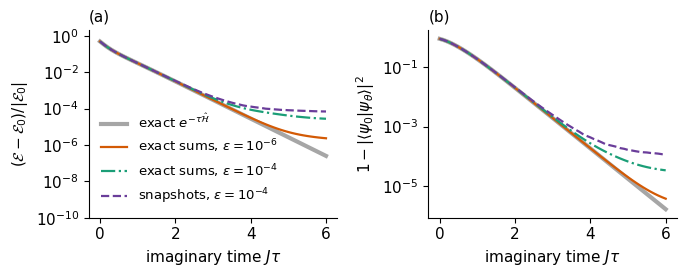

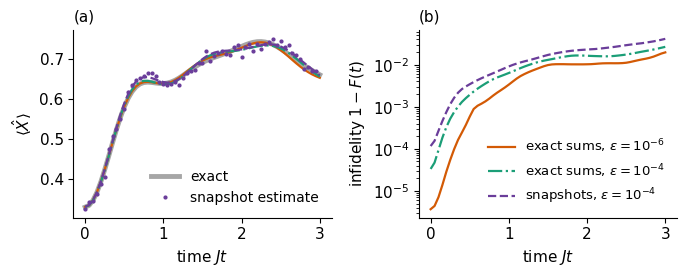

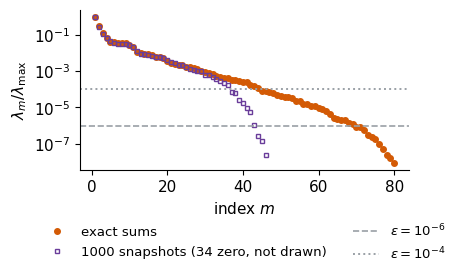

In [13]:
class Snapshots:
    # averages over p(s) as means over Metropolis snapshots, equations (29) and (30)
    name, eps = "snapshots", 1e-4
    def __init__(self, seed=101, chains=1000, sweeps_per_evaluation=2, warm_up=100):
        self.rng = np.random.default_rng(seed)
        self.sigma = self.rng.choice([-1.0, 1.0], size=(chains, N))        # random starting configurations
        self.sweeps, self.warm_up_sweeps = sweeps_per_evaluation, warm_up
        self.accepted = self.proposed = 0
        self.warm = False
    def sweep(self, theta, M):
        # one Metropolis sweep of all chains at once: propose s -> s^(i) for i = 0, ..., N-1 and accept with (30)
        lp, _ = log_psi(theta, M, self.sigma)
        for i in range(N):
            proposal = self.sigma.copy(); proposal[:, i] *= -1
            lp_new, _ = log_psi(theta, M, proposal)
            # accept if u < |psi(s')|^2 / |psi(s)|^2 = exp(2 Re(ln psi(s') - ln psi(s))), u uniform in [0, 1)
            accept = self.rng.random(len(proposal)) < np.exp(np.minimum(0.0, 2 * (lp_new.real - lp.real)))
            self.sigma[accept] = proposal[accept]
            lp = np.where(accept, lp_new, lp)
            self.accepted += accept.sum(); self.proposed += len(proposal)
    def configurations(self, theta, M):
        if not self.warm:                                                  # 100 sweeps before the first evaluation
            for _ in range(self.warm_up_sweeps):
                self.sweep(theta, M)
            self.warm = True
        for _ in range(self.sweeps):                                       # two sweeps with the current parameters
            self.sweep(theta, M)
        n = len(self.sigma)
        return self.sigma.copy(), np.full(n, 1.0 / n)                      # snapshots with equal weights 1/n

t_section = time.perf_counter()
snapshots = Snapshots()
RUNS["snap", M_MAIN] = evolve(M_MAIN, snapshots, THETA0)
rs = RUNS["snap", M_MAIN]
rs["acceptance"] = snapshots.accepted / snapshots.proposed
report(f"snapshots, M = {M_MAIN}", rs)
dx_est = np.max(np.abs(rs["X_est"] - X_EXACT[:-1]))
print(f"acceptance rate {rs['acceptance']:.3f};  max |<X>_estimated - <X>_exact| {dx_est:.4f};  "
      f"max |E_estimated - E_network| in imaginary time {np.max(np.abs(rs['E_est'] - rs['E_net'][:-1])):.3f} J")

# exact sums with the shift of the snapshot run, eps = 1e-4: separates the effect of the shift from that of sampling
RUNS["sums_shift", M_MAIN] = evolve(M_MAIN, ExactSums(eps=Snapshots.eps), THETA0)
r8e = RUNS["sums_shift", M_MAIN]
report(f"exact sums, M = {M_MAIN}, eps = {Snapshots.eps:g}", r8e)
print("relative energy error of the network in imaginary time")
print("  tau     exact sums, eps = 1e-6   exact sums, eps = 1e-4   snapshots, eps = 1e-4")
for tau in (1.0, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0):
    print(f"  {tau:3.1f}       {gs_err_at(r8, tau):.2e}                 {gs_err_at(r8e, tau):.2e}                 {gs_err_at(rs, tau):.2e}")
print(f"ratios of the ground-state errors at tau = 6: shift 1e-4 / 1e-6 with exact sums {r8e['gs_rel_err'] / r8['gs_rel_err']:.1f}, "
      f"snapshots / exact sums at the shift 1e-4 {rs['gs_rel_err'] / r8e['gs_rel_err']:.1f}")

# eigenvalues of S at the network ground state, exact sums against one set of 1000 snapshots
theta_g = r8["theta_ground"]
_, _, dO_g, _, S_g, _ = fit_ingredients(theta_g, M_MAIN, G_I)
spec_snap = Snapshots(seed=7)
for _ in range(100):
    spec_snap.sweep(theta_g, M_MAIN)
sig_g, w_g = spec_snap.configurations(theta_g, M_MAIN)
O_s = log_derivatives(theta_g, M_MAIN, sig_g); dO_s = O_s - w_g @ O_s
S_snap = (dO_s.conj().T * w_g) @ dO_s
lam_g, lam_s = np.linalg.eigvalsh(S_g), np.linalg.eigvalsh(S_snap)
print(f"S at the network ground state: eigenvalues below 1e-4 lambda_max, exact sums {int(np.sum(lam_g < 1e-4 * lam_g[-1]))}, "
      f"1000 snapshots {int(np.sum(lam_s < 1e-4 * lam_s[-1]))};  largest |a_i|, |b_j| after the sampled imaginary time {rs['ab_max']:.1e}")
n_distinct = len(np.unique(sig_g, axis=0))
print(f"distinct configurations among these 1000 snapshots: {n_distinct};  rank of S from them: "
      f"{int(np.sum(lam_s > 1e-12 * lam_s[-1]))};  probability of the two ordered configurations {2 * born_probabilities(theta_g, M_MAIN)[0]:.3f}")

# --- figure (drawing code may be skipped) ---
RUNS_BOTH = [(r"exact sums, $\epsilon=10^{-6}$", r8, COL["sums"], "-"), (r"exact sums, $\epsilon=10^{-4}$", r8e, COL["teal"], "-."),
             (r"snapshots, $\epsilon=10^{-4}$", rs, COL["snap"], "--")]
panels("fig_lab088_imaginary_time_snapshots", [lambda ax: (draw_imag_a(ax, RUNS_BOTH, legend=False), ax.set_ylim(1e-10, 2), ax.legend(frameon=False, fontsize=9.5, loc="lower left")), lambda ax: draw_imag_b(ax, RUNS_BOTH)])
panels("fig_lab088_quench_snapshots", [lambda ax: draw_quench_a(ax, RUNS_BOTH, [("snapshot estimate", rs, COL["snap"])], legend_runs=False),
                                       lambda ax: draw_quench_b(ax, RUNS_BOTH, legend=True)])
def draw_spectrum_g(ax):
    # eigenvalues below 1e-12 lambda_max are zero to rounding and are not drawn; the legend gives their number
    m = np.arange(1, len(lam_g) + 1)
    for lam, mk, kw, lab in ((lam_g, "o", dict(ms=4, color=COL["sums"]), "exact sums"),
                             (lam_s, "s", dict(ms=3.5, mfc="none", color=COL["snap"]), "1000 snapshots")):
        rel = lam[::-1] / lam[-1]; keep = rel > 1e-12
        zeros = f" ({int(np.sum(~keep))} zero, not drawn)" if np.any(~keep) else ""
        ax.semilogy(m[keep], rel[keep], mk, label=lab + zeros, **kw)
    ax.axhline(1e-6, color=COL["grey"], ls="--", lw=1.2, label=r"$\epsilon=10^{-6}$")
    ax.axhline(1e-4, color=COL["grey"], ls=":", lw=1.4, label=r"$\epsilon=10^{-4}$")
    ax.set_xlabel(r"index $m$"); ax.set_ylabel(r"$\lambda_m/\lambda_{\max}$"); ax.legend(fontsize=9.5, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
one_panel("fig_lab088_S_spectrum_snapshots", draw_spectrum_g)
TIMES["10 snapshots, M = 8"] = time.perf_counter() - t_section

| run with $M=8$ | $(\mathcal E-\mathcal E_0)/\vert\mathcal E_0\vert$ at $\tau=6/J$ | $1-F$ at $t=0$ | largest deviation of $\langle\hat X\rangle$ | $1-F$ at $Jt=3$ | energy drift |
|---|---|---|---|---|---|
| exact sums, $\epsilon=10^{-6}$ | $2.3\times10^{-6}$ | $3.7\times10^{-6}$ | $0.010$ | $2.0\times10^{-2}$ | $3\times10^{-7}J$ |
| exact sums, $\epsilon=10^{-4}$ | $2.8\times10^{-5}$ | $3.3\times10^{-5}$ | $0.012$ | $2.7\times10^{-2}$ | $6\times10^{-9}J$ |
| snapshots, $\epsilon=10^{-4}$ | $6.9\times10^{-5}$ | $1.2\times10^{-4}$ | $0.014$ | $4.1\times10^{-2}$ | $1.9\times10^{-2}J$ |

With exact sums, the larger shift raises the relative ground-state error by a factor of about 12. The shift damps the velocity along the directions with $\lambda_m\ll\epsilon\lambda_{\max}$, and $\epsilon=10^{-4}$ damps 44 of the 80 directions at $\boldsymbol\theta_0$ against 11 for $\epsilon=10^{-6}$. Sampling at the same shift raises the error by a further factor of about 2.5. In the first figure both runs with $\epsilon=10^{-4}$ follow the run with $\epsilon=10^{-6}$ down to an energy error of about $10^{-3}$, near $\tau\approx2.5/J$, and then decrease more slowly, the sampled run the slowest of the three. The infidelity in real time, panel (b) of the second figure, keeps the same ordering of the three runs at all times.

The snapshots need the larger shift because $S$ from 1000 snapshots is noisy and rank-deficient. The last figure shows the eigenvalues of $S$ at the ground state of the exact-sum run, from exact sums and from one set of 1000 snapshots. The large eigenvalues agree. The 1000 snapshots contain only 48 distinct configurations, because the two ordered configurations carry most of the probability, and a covariance matrix from $n$ distinct configurations has rank at most $n-1$. From the snapshots $S$ has rank 46 of 80, so 34 of its eigenvalues are zero to rounding. Along these directions only the shift $\epsilon\lambda_{\max}$ keeps equation (26) solvable, and along the small nonzero eigenvalues it limits the amplification of the noise of $f$ to the factor $1/(\epsilon\lambda_{\max})$.

In the second figure, the exact $\langle\hat X\rangle$ of the sampled network (dashed) stays within $0.014$ of the exact curve, and the estimate from the 1000 snapshots of each evaluation (dots) scatters around it and deviates from the exact curve by at most $0.025$. Equation (27) holds for exact averages only, and with snapshots the energy of the network drifts by $1.9\times10^{-2}J$, far more than with exact sums at either shift. After the sampled imaginary time the largest of the biases $a_i$ and $b_j$ is $3\times10^{-3}$.

## 11. Entanglement of a cut

After the change of the field the spins of the left half of the chain become correlated with those of the right half in a way that no product of a left state and a right state reproduces. This correlation is the entanglement between the two halves, and to measure it we cut the chain after $\ell$ sites. The left bits $s_0\dots s_{\ell-1}$, read as a binary number, give a row index $a$, and the right bits $s_\ell\dots s_{N-1}$ give a column index $b$. With $\psi(a,b)$ the amplitude of the configuration whose left bits form $a$ and whose right bits form $b$, the normalised amplitudes form a matrix with $2^\ell$ rows and $2^{N-\ell}$ columns,
$$\Psi_{ab}=\frac{\psi(a,b)}{\sqrt Z},\qquad Z=\sum_{\mathbf s}|\psi(\mathbf s)|^2 . \tag{31}$$
Site 0 is the most significant bit, so the basis index of the configuration is $k=a\,2^{N-\ell}+b$, and the matrix is the list of amplitudes written row after row. The regrouping changes no entry and amounts to a reshape of the vector.

A product state $\psi(a,b)=\varphi(a)\chi(b)$ is one column times one row, so all its rows are proportional, and a measurement of the left spins tells nothing about the right spins. For two spins cut in the middle the ground state $\psi\propto(1,\zeta,\zeta,1)$ of Section 3 becomes
$$\Psi=\frac{1}{\sqrt{2+2\zeta^2}}\begin{pmatrix}1&\zeta\\ \zeta&1\end{pmatrix} , \tag{32}$$
with the row $s_0=0$ on top and the row $s_0=1$ below. The rows $(1,\zeta)$ and $(\zeta,1)$ are not proportional, so the two spins are entangled, and finding the first spin up makes the second spin up more likely.

The singular value decomposition $\Psi=U\,{\rm diag}(\lambda_1,\lambda_2,\dots)\,V^\dagger$, with the singular values $\lambda_k\ge0$, writes every state as a sum of products of a left and a right state,
$$|\psi\rangle=\sum_k\lambda_k\;|u_k\rangle\otimes|v_k\rangle , \tag{33}$$
where column $k$ of $U$ holds the amplitudes of the state $|u_k\rangle$ of the left spins and row $k$ of $V^\dagger$ those of the state $|v_k\rangle$ of the right spins. The states on each side are orthonormal, so the normalisation of $|\psi\rangle$ gives $\sum_k\lambda_k^2=1$. The Schmidt weight $\lambda_k^2$ is the share of term $k$ in the state, and the number of nonzero weights is the Schmidt rank. A product state has the Schmidt rank 1, with a single weight equal to one. The von Neumann entropy and the Rényi entropy of order two express in bits how the weights are spread,
$$S_{\rm vN}=-\sum_k\lambda_k^2\log_2\lambda_k^2 ,\qquad S_2=-\log_2\sum_k\lambda_k^4 . \tag{34}$$
Both vanish for a product state, and equal weights on $m$ terms give $\log_2m$ bits for both entropies. An entropy of $S$ bits therefore means that about $2^S$ terms of the sum (33) matter. Unequal weights give $S_{\rm vN}>S_2$. The code below and the axis labels of its figures write $w_k$ for the weight $\lambda_k^2$.

The matrix (32) is real and symmetric, with the eigenvectors $(1,1)/\sqrt2$ and $(1,-1)/\sqrt2$ and the eigenvalues $(1\pm\zeta)/\sqrt{2+2\zeta^2}$. Both eigenvalues are positive, so they are the singular values, and the Schmidt weights are
$$\lambda_{1,2}^2=\frac{(1\pm\zeta)^2}{2+2\zeta^2}=\frac{1+\zeta^2\pm2\zeta}{2(1+\zeta^2)}=\frac12\pm\frac{\zeta}{1+\zeta^2}=\frac12\pm\frac1{\sqrt5}\approx0.947\ \text{and}\ 0.053 , \tag{35}$$
where the last step uses $\zeta^2=1-\zeta$, so that $1+\zeta^2=2-\zeta=\sqrt5\,\zeta$. With $|\pm\rangle=(|0\rangle\pm|1\rangle)/\sqrt2$ the ground state reads $0.973\,|{+}\rangle|{+}\rangle+0.230\,|{-}\rangle|{-}\rangle$. Almost all of it is the product $|{+}\rangle|{+}\rangle$, and the small second term makes parallel spins more likely than antiparallel ones. Equation (34) gives $S_{\rm vN}=-0.947\log_20.947-0.053\log_20.053=0.30$ bits and $S_2=-\log_2(0.947^2+0.053^2)=-\log_20.900=0.15$ bits. The Bell pair $(|00\rangle+|11\rangle)/\sqrt2$ has the weights $\tfrac12$ and $\tfrac12$ and one bit of both entropies.

We compute the weights and the entropies of the product state $|00\rangle$, the Bell pair and the two-spin ground state with the singular values of NumPy and check equation (35). We then apply the same two functions to the exact state of the chain of eight spins right after the change of the field and at $Jt=3$, cut in the middle at $\ell=4$, and draw its matrix and its Schmidt weights.

two-spin ground state as the matrix (32), rows s_0 = 0, 1 and columns s_1 = 0, 1:
[[0.6015 0.3717]
 [0.3717 0.6015]]
  product state |00>               Schmidt weights [1. 0.],  S_vN = 0.000 bits,  S_2 = 0.000 bits
  Bell pair (|00> + |11>)/sqrt2    Schmidt weights [0.5 0.5],  S_vN = 1.000 bits,  S_2 = 1.000 bits
  ground state (1, zeta, zeta, 1)  Schmidt weights [0.9472 0.0528],  S_vN = 0.298 bits,  S_2 = 0.152 bits
equation (35): 1/2 + 1/sqrt5 = 0.9472,  1/2 - 1/sqrt5 = 0.0528
chain, t = 0 : four largest Schmidt weights [5.595e-01 4.402e-01 2.000e-04 1.000e-04],  weights above 1e-12: 8 of 16,  S_vN = 0.993 bits,  S_2 = 0.980 bits
chain, Jt = 3: four largest Schmidt weights [0.6034 0.2896 0.0588 0.0282],  weights above 1e-12: 16 of 16,  S_vN = 1.488 bits,  S_2 = 1.144 bits


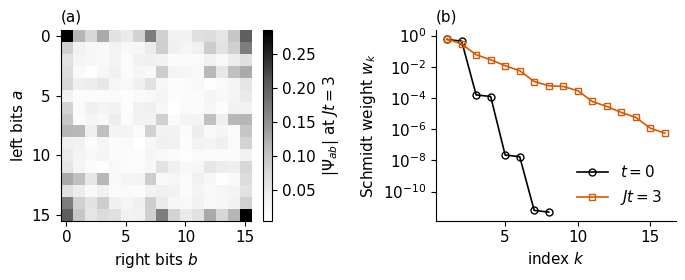

In [14]:
t_section = time.perf_counter()

def schmidt_weights(psi, ell):
    # equations (31) and (33): the normalised vector psi of 2^n amplitudes as the matrix Psi_ab with 2^ell rows (left bits a)
    # and 2^(n - ell) columns (right bits b), a reshape because site 0 is the most significant bit; w_k = squared singular values
    n = int(round(np.log2(len(psi))))
    return np.linalg.svd(np.asarray(psi).reshape(2 ** ell, 2 ** (n - ell)), compute_uv=False) ** 2

def entropies(w):
    # equation (34) in bits; weights below 1e-15 are zero to rounding and are dropped (0 log 0 = 0)
    w = w[w > 1e-15]
    return float(-np.sum(w * np.log2(w))), float(-np.log2(np.sum(w ** 2)))

TWO_SPIN_STATES = {"product state |00>": np.array([1.0, 0.0, 0.0, 0.0]),
                   "Bell pair (|00> + |11>)/sqrt2": np.array([1.0, 0.0, 0.0, 1.0]) / np.sqrt(2),
                   "ground state (1, zeta, zeta, 1)": np.array([1.0, ZETA, ZETA, 1.0]) / np.sqrt(2 + 2 * ZETA ** 2)}
print("two-spin ground state as the matrix (32), rows s_0 = 0, 1 and columns s_1 = 0, 1:")
print(np.round(TWO_SPIN_STATES["ground state (1, zeta, zeta, 1)"].reshape(2, 2), 4))
for label, psi_2 in TWO_SPIN_STATES.items():
    vn_2, s2_2 = entropies(schmidt_weights(psi_2, 1))
    print(f"  {label:32s} Schmidt weights {np.round(schmidt_weights(psi_2, 1), 4)},  S_vN = {abs(vn_2):.3f} bits,  S_2 = {abs(s2_2):.3f} bits")
w_formula = np.array([0.5 + 1 / np.sqrt(5), 0.5 - 1 / np.sqrt(5)])        # equation (35)
assert np.allclose(schmidt_weights(TWO_SPIN_STATES["ground state (1, zeta, zeta, 1)"], 1), w_formula)
print(f"equation (35): 1/2 + 1/sqrt5 = {w_formula[0]:.4f},  1/2 - 1/sqrt5 = {w_formula[1]:.4f}")

# the exact state of the chain of eight spins (Section 2), cut in the middle, ell = 4: a 16 x 16 matrix
for label, psi_t in (("t = 0 ", PSI_T[0]), ("Jt = 3", PSI_T[-1])):
    w_t = schmidt_weights(psi_t, N // 2)
    vn_t, s2_t = entropies(w_t)
    print(f"chain, {label}: four largest Schmidt weights {np.round(w_t[:4], 4)},  weights above 1e-12: {int(np.sum(w_t > 1e-12))} of 16,  "
          f"S_vN = {vn_t:.3f} bits,  S_2 = {s2_t:.3f} bits")

# --- figure (drawing code may be skipped) ---
def draw_cut_a(ax):
    image = ax.imshow(np.abs(PSI_T[-1].reshape(16, 16)), cmap="Greys", interpolation="nearest")
    ax.set_xticks([0, 5, 10, 15]); ax.set_yticks([0, 5, 10, 15])
    ax.set_xlabel(r"right bits $b$"); ax.set_ylabel(r"left bits $a$")
    ax.figure.colorbar(image, ax=ax, label=r"$|\Psi_{ab}|$ at $Jt=3$")
def draw_cut_b(ax):
    k = np.arange(1, 17)
    for psi_t, c, mk, lab in ((PSI_T[0], COL["exact"], "o", "$t=0$"), (PSI_T[-1], COL["sums"], "s", "$Jt=3$")):
        w_t = schmidt_weights(psi_t, N // 2)
        keep = w_t > 1e-12
        ax.semilogy(k[keep], w_t[keep], mk + "-", color=c, ms=5, lw=1.2, mfc="none", label=lab)
    ax.set_xlabel(r"index $k$"); ax.set_ylabel(r"Schmidt weight $w_k$"); ax.legend(frameon=False)
panels("fig_lab088_cut", [draw_cut_a, draw_cut_b])

The weights of the two-spin ground state agree with equation (35), with the entropies 0.30 and 0.15 bits, and the product state and the Bell pair give zero and one bit. Panel (a) of the figure shows the moduli of the 256 amplitudes of the chain at $Jt=3$ as the $16\times16$ matrix (31), and panel (b) the Schmidt weights of the middle cut on a logarithmic axis. Right after the change of the field two weights, 0.56 and 0.44, hold almost the whole state, which is a superposition of mostly ordered configurations around all spins up and all spins down. The remaining weights lie below $10^{-3}$, and $S_{\rm vN}=0.99$ bits. At $Jt=3$ all 16 weights are nonzero, the four largest are 0.60, 0.29, 0.06 and 0.03, and $S_{\rm vN}$ has grown to 1.49 bits.

The network stores its amplitudes through the hidden units, and the hidden units limit the entanglement it can carry across a cut [15]. We split the input of hidden unit $j$ into a part from the left spins and a part from the right spins,
$$u_j(a,b)=b_j+L_j(a)+R_j(b),\qquad L_j(a)=\sum_{i<\ell}w_{ij}\sigma_i,\qquad R_j(b)=\sum_{i\ge\ell}w_{ij}\sigma_i . \tag{36}$$
With $x=b_j+L_j(a)$ and $y=R_j(b)$ the factor of the hidden unit is a sum of two products,
$$2\cosh(x+y)=e^{x+y}+e^{-x-y}=e^{x}\,e^{y}+e^{-x}\,e^{-y} , \tag{37}$$
where the first term comes from $h_j=+1$ and the second from $h_j=-1$. Written as a matrix $F_j(a,b)=2\cosh u_j(a,b)$ with the rows $a$ and the columns $b$, each product is a column that depends on $a$ times a row that depends on $b$, so $F_j$ has rank at most 2. For two spins and one hidden unit with the weight $w$ to both spins and no biases, with the rows $\sigma_0=+1,-1$ and the columns $\sigma_1=+1,-1$,
$$\begin{pmatrix}2\cosh2w&2\\2&2\cosh2w\end{pmatrix}=\underbrace{\begin{pmatrix}e^{w}\\e^{-w}\end{pmatrix}\begin{pmatrix}e^{w}&e^{-w}\end{pmatrix}}_{h=+1}+\underbrace{\begin{pmatrix}e^{-w}\\e^{w}\end{pmatrix}\begin{pmatrix}e^{-w}&e^{w}\end{pmatrix}}_{h=-1} . \tag{38}$$
The diagonal entries are $e^{2w}+e^{-2w}=2\cosh2w$ and the others $e^0+e^0=2$. At $w=0.53$, where $\cosh2w\approx(\sqrt5+1)/2$, the matrix is $\begin{pmatrix}3.23&2\\2&3.23\end{pmatrix}$, proportional to the matrix (32) because $2/3.23\approx\zeta$. Its determinant $3.23^2-4=6.45$ is nonzero, so its rank is 2, and after normalisation it has approximately the Schmidt weights $0.947$ and $0.053$ of the two-spin ground state.

A hidden unit connected to the left spins only has $R_j=0$, so its factor depends on $a$ alone. As a matrix it is the column of these factors times a row of ones, of rank 1, and the same holds for a unit connected to the right spins only. The visible factor $e^{\sum_ia_i\sigma_i}$ is a left part times a right part, again of rank 1. The amplitude (10) is the product of all these factors, taken entry by entry, and the rank of an entrywise product is at most the product of the ranks. If $A_{ab}=\sum_{p=1}^{r_A}\alpha_p(a)\beta_p(b)$ and $B_{ab}=\sum_{q=1}^{r_B}\gamma_q(a)\delta_q(b)$, then
$$A_{ab}B_{ab}=\sum_{p=1}^{r_A}\sum_{q=1}^{r_B}\big[\alpha_p(a)\gamma_q(a)\big]\big[\beta_p(b)\delta_q(b)\big] \tag{39}$$
is a sum of $r_Ar_B$ products of a column and a row. Each hidden unit connected to both sides therefore at most doubles the Schmidt rank, and all other factors leave it unchanged. With $n_{\rm cross}$ such units,
$$\text{Schmidt rank}\le2^{\,n_{\rm cross}},\qquad S_{\rm vN}\le\log_2(\text{Schmidt rank})\le n_{\rm cross}\ \text{bits} , \tag{40}$$
where the middle inequality holds because $r$ nonzero weights give at most $\log_2r$ bits, the value for equal weights. A network can therefore carry at most one bit of entanglement across a cut for every hidden unit connected to both sides. The masked networks of Lab 081, which certified the entanglement depth, had no hidden unit joining two groups of qubits, so $n_{\rm cross}=0$ for every cut between groups and the states were products across the groups.

We test equation (40) on a network with random complex parameters, $N=8$ spins, $M=6$ hidden units and the cut after $\ell=4$ sites. The biases are $a_i,b_j=0.3\,(x+iy)$ and the weights $w_{ij}=0.5\,(x+iy)$, with $x$ and $y$ independent standard normal numbers drawn with seed 3. A mask keeps the first $n_{\rm cross}$ hidden units connected to all eight spins and connects the remaining units alternately to the four left spins only and to the four right spins only, by setting the other weights to zero. For $n_{\rm cross}=0,1,2,3$ we compute the 256 amplitudes, reshape them with equation (31), take as the Schmidt rank the number of singular values above $10^{-10}$ times the largest one and evaluate $S_{\rm vN}$. We also print the matrix (38) at $w=0.53$ and the rank of the $16\times16$ matrix $F_j(a,b)$ of every hidden unit.

matrix (38) at w = 0.53:
 [[3.233 2.   ]
 [2.    3.233]]
determinant 6.45,  rank 2,  2 / (2 cosh 2w) = 0.6187 (zeta = 0.6180),  Schmidt weights [0.9474 0.0526]
 n_cross   Schmidt rank   bound 2^n_cross   S_vN (bits)   bound (bits)   rank of F_j for the units 0..5 (side)
    0           1               1             0.000           0         1(left) 1(right) 1(left) 1(right) 1(left) 1(right)
    1           2               2             0.539           1         2(both) 1(left) 1(right) 1(left) 1(right) 1(left)
    2           4               4             1.232           2         2(both) 2(both) 1(left) 1(right) 1(left) 1(right)
    3           8               8             0.943           3         2(both) 2(both) 2(both) 1(left) 1(right) 1(left)
core route (Sections 1 to 11): 121 s


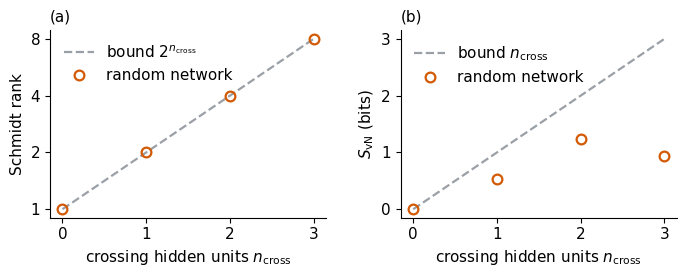

In [15]:
# equation (38): one hidden unit with weight w on two spins, rows sigma_0 = +1, -1 and columns sigma_1 = +1, -1
w_pair = 0.53
pm = np.array([1.0, -1.0])
F_pair = 2 * np.cosh(w_pair * (pm[:, None] + pm[None, :]))                    # 2 cosh(w (sigma_0 + sigma_1))
col_plus, col_minus = np.exp(w_pair * pm), np.exp(-w_pair * pm)               # e^{w sigma} (h = +1) and e^{-w sigma} (h = -1)
assert np.allclose(F_pair, np.outer(col_plus, col_plus) + np.outer(col_minus, col_minus))
print("matrix (38) at w = 0.53:\n", np.round(F_pair, 3))
print(f"determinant {np.linalg.det(F_pair):.2f},  rank {np.linalg.matrix_rank(F_pair)},  2 / (2 cosh 2w) = {F_pair[0, 1] / F_pair[0, 0]:.4f} "
      f"(zeta = {ZETA:.4f}),  Schmidt weights {np.round(schmidt_weights(F_pair.ravel() / np.linalg.norm(F_pair), 1), 4)}")

# random complex network, N = 8, M = 6, cut after ell = 4 sites
M_RAND, CUT_RAND = 6, 4
rng_rand = np.random.default_rng(3)
a_r = 0.3 * (rng_rand.normal(size=N) + 1j * rng_rand.normal(size=N))
b_r = 0.3 * (rng_rand.normal(size=M_RAND) + 1j * rng_rand.normal(size=M_RAND))
W_r = 0.5 * (rng_rand.normal(size=(N, M_RAND)) + 1j * rng_rand.normal(size=(N, M_RAND)))
LEFT_SITES = np.arange(N) < CUT_RAND                                           # True for the sites 0 to 3

def crossing_mask(n_cross):
    # column j of the mask: hidden units 0 .. n_cross - 1 see all spins, the others alternately the left or the right half only
    mask = np.zeros((N, M_RAND))
    for j in range(M_RAND):
        mask[:, j] = 1.0 if j < n_cross else (LEFT_SITES if (j - n_cross) % 2 == 0 else ~LEFT_SITES)
    return mask

def unit_side(j, n_cross):
    return "both" if j < n_cross else ("left" if (j - n_cross) % 2 == 0 else "right")

CROSS = {}
print(" n_cross   Schmidt rank   bound 2^n_cross   S_vN (bits)   bound (bits)   rank of F_j for the units 0..5 (side)")
for n_cross in range(4):
    theta_r = np.concatenate([a_r, b_r, (W_r * crossing_mask(n_cross)).ravel()])
    sv = np.sqrt(schmidt_weights(state_vector(theta_r, M_RAND), CUT_RAND))     # singular values of Psi_ab
    rank = int(np.sum(sv > 1e-10 * sv[0]))
    vn_r = max(entropies(sv ** 2)[0], 0.0)
    u_r = log_psi(theta_r, M_RAND, CONF)[1]                                     # inputs u_j of all 256 configurations, shape (256, 6)
    unit_ranks = [int(np.linalg.matrix_rank(2 * np.cosh(u_r[:, j]).reshape(16, 16))) for j in range(M_RAND)]
    CROSS[n_cross] = dict(rank=rank, vn=vn_r, unit_ranks=unit_ranks)
    print(f"    {n_cross}          {rank:2d}              {2 ** n_cross:2d}             {vn_r:.3f}           {n_cross}         "
          + " ".join(f"{r}({unit_side(j, n_cross)})" for j, r in enumerate(unit_ranks)))
    assert rank <= 2 ** n_cross and vn_r <= n_cross + 1e-12

# --- figure (drawing code may be skipped) ---
def draw_cross_a(ax):
    n = np.arange(4)
    ax.plot(n, 2.0 ** n, color=COL["grey"], lw=1.6, ls="--", label=r"bound $2^{n_{\rm cross}}$")
    ax.plot(n, [CROSS[k]["rank"] for k in n], "o", color=COL["sums"], ms=7, mfc="none", mew=1.6, label="random network")
    ax.set_yscale("log", base=2); ax.set_yticks([1, 2, 4, 8]); ax.set_yticklabels(["1", "2", "4", "8"]); ax.set_xticks(n)
    ax.set_xlabel(r"crossing hidden units $n_{\rm cross}$"); ax.set_ylabel("Schmidt rank"); ax.legend(frameon=False, loc="upper left")
def draw_cross_b(ax):
    n = np.arange(4)
    ax.plot(n, n, color=COL["grey"], lw=1.6, ls="--", label=r"bound $n_{\rm cross}$")
    ax.plot(n, [CROSS[k]["vn"] for k in n], "o", color=COL["sums"], ms=7, mfc="none", mew=1.6, label="random network")
    ax.set_xticks(n); ax.set_xlabel(r"crossing hidden units $n_{\rm cross}$"); ax.set_ylabel(r"$S_{\rm vN}$ (bits)")
    ax.legend(frameon=False, loc="upper left")
panels("fig_lab088_crossing_units", [draw_cross_a, draw_cross_b])
TIMES["11 entanglement of a cut"] = time.perf_counter() - t_section
CORE_SECONDS = time.perf_counter() - started
print(f"core route (Sections 1 to 11): {CORE_SECONDS:.0f} s")

The matrix (38) at $w=0.53$ has the determinant 6.45 and the rank 2, and its normalised Schmidt weights 0.947 and 0.053 are close to those of the two-spin ground state. For the random network the Schmidt rank equals the bound $2^{n_{\rm cross}}$ in all four cases, 1, 2, 4 and 8. Every hidden unit connected to one side has a factor matrix $F_j$ of rank 1, and every crossing unit a factor matrix of rank 2. The figure shows the Schmidt rank in panel (a) and $S_{\rm vN}$ in panel (b) against $n_{\rm cross}$, with the bounds dashed. The entropy stays below its bound, with 0, 0.54, 1.23 and 0.94 bits, and for $n_{\rm cross}=3$ it is lower than for $n_{\rm cross}=2$, because equation (40) limits the entropy only from above and the random parameters spread the eight weights of $n_{\rm cross}=3$ far from evenly.

The core route ends here, and the last line of the output above gives its measured runtime.

## 12. At home. Number of hidden units

This section took 74 seconds in the recorded run. The number of hidden units $M$ sets how many conditions (16) the network can satisfy at once. We repeat the evolution with exact sums for $M=4$ and $M=16$, with 44 and 152 complex parameters, from initial parameters drawn in the same way with seed 1, and set both runs beside the run with $M=8$ of Section 9. We print the energy errors at four imaginary times. Besides the infidelity we plot the relative residual of the fit, $\mathcal L(\dot{\boldsymbol\theta})$ of equation (20) divided by $\langle|\delta E_{\rm loc}|^2\rangle$, at every recorded time. It is the squared length of the part of the exact step that the network cannot follow, divided by the squared length of the exact step, so a residual $r$ means that the missed part has the fraction $\sqrt r$ of the length of the step.

Because the regularised flow with exact sums conserves the energy according to equation (27), the energy drift of a computed run comes from the time step of the integrator. For $M=16$ we repeat the real-time part from the same network ground state with the step $dt/2=0.0025/J$. For a method of fourth order the drift should fall by about $2^4=16$.

exact sums, M =  4 ( 44 parameters): relative ground-state energy error 1.54e-04, infidelity at t = 0 2.31e-04, max |<X>_network - <X>_exact| 0.0311, infidelity at t = 3 1.12e-01, energy drift 5.6e-05 J, 7 s
exact sums, M =  8 ( 80 parameters): relative ground-state energy error 2.33e-06, infidelity at t = 0 3.67e-06, max |<X>_network - <X>_exact| 0.0103, infidelity at t = 3 1.97e-02, energy drift 3.3e-07 J, 13 s
exact sums, M = 16 (152 parameters): relative ground-state energy error 6.18e-07, infidelity at t = 0 2.06e-06, max |<X>_network - <X>_exact| 0.0053, infidelity at t = 3 7.27e-03, energy drift 1.8e-06 J, 31 s
relative energy error at late imaginary times
   M    tau = 4     tau = 5     tau = 5.5   tau = 6     largest relative residual in real time
   4    1.90e-04   1.58e-04   1.55e-04   1.54e-04    0.184
   8    3.11e-05   5.14e-06   3.11e-06   2.33e-06    0.053
  16    3.16e-05   3.31e-06   1.26e-06   6.18e-07    0.039
M = 16, energy drift for 0 <= t <= 3: dt = 0.005: 1.8e-0

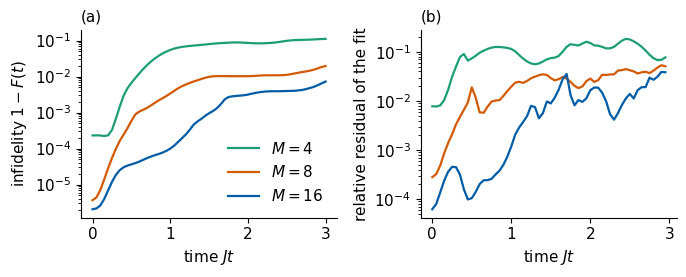

In [16]:
t_section = time.perf_counter()
M_LIST = (4, 8, 16)
for M in M_LIST:
    if ("sums", M) not in RUNS:
        RUNS["sums", M] = evolve(M, ExactSums(), initial_parameters(M))
for M in M_LIST:
    report(f"exact sums, M = {M:2d} ({N + M + N * M:3d} parameters)", RUNS["sums", M])
print("relative energy error at late imaginary times")
print("   M    tau = 4     tau = 5     tau = 5.5   tau = 6     largest relative residual in real time")
for M in M_LIST:
    print(f"  {M:2d}    " + "   ".join(f"{gs_err_at(RUNS['sums', M], tau):.2e}" for tau in (4.0, 5.0, 5.5, 6.0))
          + f"    {np.max(RUNS['sums', M]['residual']):.3f}")

# --- figure (drawing code may be skipped) ---
COL_M = {4: COL["teal"], 8: COL["sums"], 16: COL["netket"]}
def draw_m_a(ax):
    for M in M_LIST:
        ax.semilogy(T_GRID, RUNS["sums", M]["infid"], color=COL_M[M], lw=1.6, label=f"$M={M}$")
    ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"infidelity $1-F(t)$"); ax.legend(frameon=False)
def draw_m_b(ax):
    for M in M_LIST:
        ax.semilogy(T_GRID[:-1], RUNS["sums", M]["residual"], color=COL_M[M], lw=1.6, label=f"$M={M}$")
    ax.set_xlabel(r"time $Jt$"); ax.set_ylabel("relative residual of the fit")
panels("fig_lab088_hidden_units", [draw_m_a, draw_m_b])

# energy drift against the time step, M = 16: the real-time part again, from the same network ground state, with dt / 2
def real_time_half_step(M, theta, dt):
    # real time with H(g_f) and the step dt; energy, <X> and infidelity of the network every 0.05 / J
    n_real, every = int(round(T_MAX / dt)), int(round(DT * EVERY / dt))
    energies, xs = [], []
    for n in range(n_real + 1):
        if n % every == 0:
            v = state_vector(theta, M)
            energies.append(np.vdot(v, H_F @ v).real); xs.append(np.vdot(v, X_MAT @ v).real)
            infid_last = 1 - abs(np.vdot(PSI_T[n // every], v)) ** 2
        if n < n_real:
            theta, _ = rk4_step(theta, M, G_F, dt, True, ExactSums())
    return dict(energy_drift=float(np.max(np.abs(np.array(energies) - energies[0]))),
                max_abs_dx=float(np.max(np.abs(np.array(xs) - X_EXACT))), infid_T=float(infid_last))
drift_dt = float(np.max(np.abs(RUNS["sums", 16]["E_real"] - RUNS["sums", 16]["E_real"][0])))
HALF_DT_M16 = real_time_half_step(16, RUNS["sums", 16]["theta_ground"], DT / 2)
drift_half = HALF_DT_M16["energy_drift"]
print(f"M = 16, energy drift for 0 <= t <= 3: dt = {DT}: {drift_dt:.1e} J,  dt = {DT / 2}: {drift_half:.1e} J,  ratio {drift_dt / drift_half:.1f}")
print(f"M = 16, infidelity at t = 3: dt = {DT}: {RUNS['sums', 16]['infid'][-1]:.3e},  dt = {DT / 2}: {HALF_DT_M16['infid_T']:.3e}")
TIMES["12 hidden units"] = time.perf_counter() - t_section

| $M$ | complex parameters | $(\mathcal E-\mathcal E_0)/\vert\mathcal E_0\vert$ at $\tau=6/J$ | $1-F$ at $t=0$ | largest deviation of $\langle\hat X\rangle$ | $1-F$ at $Jt=3$ |
|---|---|---|---|---|---|
| 4 | 44 | $1.5\times10^{-4}$ | $2.3\times10^{-4}$ | $0.031$ | $0.11$ |
| 8 | 80 | $2.3\times10^{-6}$ | $3.7\times10^{-6}$ | $0.010$ | $2.0\times10^{-2}$ |
| 16 | 152 | $6.2\times10^{-7}$ | $2.1\times10^{-6}$ | $0.005$ | $7\times10^{-3}$ |

All three runs use exact sums, and every doubling of $M$ lowers the ground-state error, the deviation of $\langle\hat X\rangle$ and the infidelity at $Jt=3$. The printed energy errors show that the run with $M=4$ has levelled off by $\tau=5/J$. The run with $M=8$ still falls slightly, from $5.1\times10^{-6}$ at $\tau=5/J$ to $2.3\times10^{-6}$ at $\tau=6/J$, and the run with $M=16$ falls faster, from $3.3\times10^{-6}$ to $6.2\times10^{-7}$. Panel (a) shows the infidelity against time and panel (b) the relative residual of the fit. The residual decreases with $M$ during most of the evolution. For $M=4$ it stays near $0.1$ after $Jt\approx0.5$, so the part of the exact step that this network misses has about a third of the length of the step, $\sqrt{0.1}\approx0.32$. At its largest printed value, $0.184$, the missed part is $\sqrt{0.184}\approx0.43$ of the step, and the infidelity of this network levels off near $0.1$.

The energy drift of the run with $M=16$ falls by a factor of 15 when the step is halved from $dt=0.005/J$ to $0.0025/J$, close to the factor $2^4=16$ of a method of fourth order. The drift is therefore the error of the time step, and equation (27) holds for the network itself. Halving the step changes the infidelity of this run at $Jt=3$ in the second significant digit, so the table gives the real-time numbers of $M=16$ to one significant digit.

## 13. At home. The same calculation with NetKet

This section took 93 seconds in the recorded run. NetKet [8] is a library for neural quantum states built on JAX, with counterparts of the objects of Sections 4 to 10 listed in the table below. It is installed on the CPU with

```
pip install netket
```

The notebook was tested with NetKet 3.11.1 and JAX 0.4.38, and the import cell prints the installed versions. In that installation the built-in network `nk.models.RBM` failed with an error inside the Flax library, so the code passes its own amplitude (10) to NetKet through the argument `apply_fun`. With a fresh installation the branch that uses `nk.models.RBM` may run. Its parameter mapping was checked against the source code of NetKet, and it has not been executed. If the import fails, the import cell prints one line, the other cells of this section are skipped, and Sections 14 and 15 still run.

| our code | equation | NetKet |
|---|---|---|
| `log_psi`, amplitude of the RBM | (10) | `nk.models.RBM(param_dtype=complex)`, or any function passed as `apply_fun` |
| `log_derivatives`, $O_k(\mathbf s)$ | (11) | automatic differentiation of the model by JAX |
| $S$ in `velocity` | (21) | `nk.optimizer.qgt.QGTJacobianDense(holomorphic=True)`, which NetKet calls the quantum geometric tensor because by equation (24) it measures the distance between nearby states, where `holomorphic=True` states that the amplitude contains no complex conjugate of a parameter |
| force $f$ in `velocity` | (21) | the forces returned by `vstate.expect_and_forces(H)` |
| `ExactSums` | (12) | `nk.vqs.FullSumState` |
| `Snapshots`, Metropolis rule | (29), (30) | `nk.vqs.MCState` with `nk.sampler.MetropolisLocal` |
| shift $\epsilon\lambda_{\max}$ of $S$ | (26) | a linear solver passed to the driver, here our `shifted_solve` |
| `rk4_step` | (28) | `nkx.dynamics.RK4(dt=...)` |
| `evolve` | (21) | `nkx.TDVP(H, vstate, integrator, propagation_type="imag")` and `propagation_type="real"` |
| Euler step of imaginary time | (22) | `nk.driver.VMC` with `nk.optimizer.Sgd(learning_rate=dτ)` and `preconditioner=nk.optimizer.SR(...)` |

NetKet's RBM writes $\ln\cosh$ in place of our $\ln(2\cosh)$, which divides the amplitude by the constant $2^M$ and changes neither the state nor $O_k$, $S$ and $f$. NetKet labels the two states of a spin by $x_i=\pm1$, and the code reads from NetKet's own $\hat\sigma^z$ operator which value of $x_i$ belongs to $\sigma_i=+1$. Flipping all spins leaves $\hat{\mathcal H}$ and $\hat X$ unchanged, so a wrong sign would pass every test with these two operators. We therefore also compare $\langle\hat\sigma^z_0\rangle$, which changes sign under the flip, for parameters with $a\neq0$. NetKet's own `diag_shift` adds a fixed number to the diagonal of $S$, so we pass NetKet a linear solver of ours, `shifted_solve`, which adds $\epsilon\lambda_{\max}$ as in equation (26).

In [17]:
t_section = time.perf_counter()
try:
    import warnings
    warnings.filterwarnings("ignore")                       # NetKet and JAX print version and performance hints
    from functools import partial
    import jax
    jax.config.update("jax_enable_x64", True)               # double precision, as in our code
    import jax.numpy as jnp
    from jax.flatten_util import ravel_pytree
    import netket as nk
    import netket.experimental as nkx
    import flax
    HAVE_NETKET = True
    print(f"installed versions: NetKet {nk.__version__}, JAX {jax.__version__}, Flax {flax.__version__};  device {jax.devices()[0].platform}")
except Exception as error:
    HAVE_NETKET = False
    print(f"NetKet is not available ({type(error).__name__}: {error}); Section 13 is skipped.")

installed versions: NetKet 3.11.1, JAX 0.4.38, Flax 0.8.5;  device cpu


We build NetKet's Hilbert space of eight spins, and the Hamiltonian (1) at both fields and $\hat X$ from NetKet's Pauli operators. We then find the order in which NetKet lists the basis states and check that NetKet's Hamiltonian, written in our order, equals our matrix. Then we define the network, load our initial parameters $\boldsymbol\theta_0$ and check that the 256 amplitudes agree with `state_vector`. The state at $\boldsymbol\theta_0$ is even, so we repeat the comparison at the random complex parameters of the check in Section 4, whose visible biases $a_i$ are nonzero, and compare $\langle\hat\sigma^z_0\rangle$ from both codes.

In [18]:
if HAVE_NETKET:
    hi = nk.hilbert.Spin(s=0.5, N=N)                                     # N spins 1/2, states x_i = -1, +1
    X_NK = np.asarray(hi.all_states())                                   # NetKet's list of the 256 configurations
    # sign relating NetKet's x_i to our sigma_i, read from NetKet's sigma^z on site 0: sigma_i = SIGN * x_i
    SIGN = int(round(np.diag(nk.operator.spin.sigmaz(hi, 0).to_dense())[0].real / X_NK[0, 0]))
    BITS_NK = (1 - SIGN * X_NK) // 2                                     # our bits of each NetKet configuration
    ORDER = (BITS_NK * (1 << (N - 1 - np.arange(N)))).sum(axis=1).astype(int)   # our index k of NetKet state j
    def nk_hamiltonian(g):
        # equation (1) from NetKet's Pauli operators
        zz = sum(nk.operator.spin.sigmaz(hi, i) @ nk.operator.spin.sigmaz(hi, i + 1) for i in range(N - 1))
        xx = sum(nk.operator.spin.sigmax(hi, i) for i in range(N))
        return -J * zz - g * xx
    H_NK = {G_I: nk_hamiltonian(G_I), G_F: nk_hamiltonian(G_F)}
    X_OP = sum(nk.operator.spin.sigmax(hi, i) for i in range(N)) * (1.0 / N)   # equation (2)
    for g, H in H_NK.items():                                            # check: same matrix as ours in our order
        H_ours_order = np.zeros((DIM, DIM)); H_ours_order[np.ix_(ORDER, ORDER)] = H.to_dense().real
        assert np.allclose(H_ours_order, hamiltonian(g))
    print(f"sigma_i = {SIGN:+d} x_i;  NetKet state j has our index ORDER[j], first entries {ORDER[:4]}")

    def rbm_apply(variables, x, **kwargs):
        # equation (10) without the constant factor 2^M, in NetKet's form ln psi = sum a sigma + sum ln cosh(u)
        p = variables["params"]
        sigma = SIGN * x                                                 # NetKet's x_i -> our sigma_i
        return sigma @ p["a"] + jnp.sum(nk.nn.activation.log_cosh(p["b"] + sigma @ p["W"]), axis=-1)

    try:                                                                 # NetKet's own RBM with complex parameters
        rbm_model = nk.models.RBM(alpha=M_MAIN // N, param_dtype=complex)
        rbm_model.init(jax.random.PRNGKey(0), X_NK[:2])
        USE_NK_RBM = True
    except Exception as error:
        USE_NK_RBM = False
        print(f"nk.models.RBM failed in this installation ({type(error).__name__}: {str(error)[:80]}); "
              f"the amplitude (10) is passed as apply_fun")

    def to_variables(theta, M):
        # our flat theta -> NetKet parameters (SIGN converts sigma_i = SIGN x_i)
        a, b, W = (jnp.asarray(z) for z in unpack(theta, M))
        if USE_NK_RBM:
            return {"params": {"visible_bias": SIGN * a, "Dense": {"bias": b, "kernel": SIGN * W}}}
        return {"params": {"a": a, "b": b, "W": W}}

    def to_flat(params):
        # NetKet parameters (or parameter velocities) -> our flat order (a, b, W)
        if USE_NK_RBM:
            a, b, W = SIGN * params["visible_bias"], params["Dense"]["bias"], SIGN * params["Dense"]["kernel"]
        else:
            a, b, W = params["a"], params["b"], params["W"]
        return np.concatenate([np.asarray(a), np.asarray(b), np.asarray(W).ravel()])

    def model_kwargs(theta, M):
        if USE_NK_RBM:
            return dict(model=nk.models.RBM(alpha=M // N, param_dtype=complex), variables=to_variables(theta, M))
        return dict(apply_fun=rbm_apply, variables=to_variables(theta, M))

    def our_order(vstate):
        # NetKet's normalised amplitudes rearranged into our basis order
        v = np.zeros(DIM, dtype=complex); v[ORDER] = np.asarray(vstate.to_array())
        return v

    vs0 = nk.vqs.FullSumState(hi, **model_kwargs(THETA0, M_MAIN))
    overlap0 = abs(np.vdot(our_order(vs0), state_vector(THETA0, M_MAIN)))
    print(f"network used: {'nk.models.RBM' if USE_NK_RBM else 'equation (10) as apply_fun'};  "
          f"|<psi_NetKet|psi_ours>| at theta_0 = {overlap0:.15f}")
    assert abs(overlap0 - 1) < 1e-12

    # check: an observable that changes sign under the flip of all spins, at parameters with a != 0
    # (theta_test of the check in Section 4, random complex, M = 8): a wrong SIGN would flip <sigma^z_0>
    vs_odd = nk.vqs.FullSumState(hi, **model_kwargs(theta_test, 8))
    sz0_nk = float(vs_odd.expect(nk.operator.spin.sigmaz(hi, 0)).mean.real)
    sz0_ours = float(born_probabilities(theta_test, 8) @ CONF[:, 0])      # <sigma^z_0> = sum_s p(s) sigma_0
    overlap_odd = abs(np.vdot(our_order(vs_odd), state_vector(theta_test, 8)))
    print(f"random complex parameters with a != 0: <sigma^z_0> ours {sz0_ours:+.10f}, NetKet {sz0_nk:+.10f};  "
          f"|<psi_NetKet|psi_ours>| = {overlap_odd:.15f}")
    assert abs(sz0_nk - sz0_ours) < 1e-10 and abs(overlap_odd - 1) < 1e-12

sigma_i = -1 x_i;  NetKet state j has our index ORDER[j], first entries [0 1 2 3]
nk.models.RBM failed in this installation (AttributeError: 'EvalTrace' object has no attribute 'level'); the amplitude (10) is passed as apply_fun
network used: equation (10) as apply_fun;  |<psi_NetKet|psi_ours>| at theta_0 = 1.000000000000000
random complex parameters with a != 0: <sigma^z_0> ours +0.1110594473, NetKet +0.1110594473;  |<psi_NetKet|psi_ours>| = 1.000000000000000


The two codes now hold the same state, also for parameters that break the spin-flip symmetry. We compute one parameter velocity, the real-time step with $\hat{\mathcal H}(g_f)$ at $\boldsymbol\theta_0$ with exact sums, in both codes side by side. Our function `velocity` builds $\delta O_k$, $S$ and $f$ and solves equation (26). In NetKet, `FullSumState` evaluates the averages as exact sums, `expect_and_forces` returns the energy and $f$, `QGTJacobianDense` returns $S$, and the linear solver `shifted_solve` solves equation (26) with the same shift. The two velocities and the eigenvalues of the two matrices $S$ must agree.

In [19]:
if HAVE_NETKET:
    def shifted_solve(A, b, *, eps, x0=None):
        # equation (26) for NetKet: A is the quantum geometric tensor S, b the right-hand side as a tree of parameters
        S = A.to_dense()                                          # dense P x P matrix S (diag_shift = 0)
        rhs, unravel = ravel_pytree(b)                            # tree of parameters -> flat vector
        shift = eps * jnp.linalg.eigvalsh(S)[-1]                  # eps times the largest eigenvalue of S
        return unravel(jnp.linalg.solve(S + shift * jnp.eye(S.shape[0]), rhs)), None

    # our code: one velocity, real time at g_f, exact sums
    vel_ours, info_ours = velocity(THETA0, M_MAIN, G_F, True, ExactSums())

    # NetKet: the same step
    E_nk, forces_nk = vs0.expect_and_forces(H_NK[G_F])               # energy and f_k = <Delta O_k* Delta E_loc>
    S_nk = nk.optimizer.qgt.QGTJacobianDense(vs0, holomorphic=True, diag_shift=0.0)    # S_kl = <Delta O_k* Delta O_l>
    rhs_nk = jax.tree_util.tree_map(lambda x: -1j * x, forces_nk)    # right-hand side -i f of equation (21)
    vel_nk_tree, _ = shifted_solve(S_nk, rhs_nk, eps=ExactSums.eps)
    vel_nk = to_flat(vel_nk_tree)

    lam_ours = np.linalg.eigvalsh(fit_ingredients(THETA0, M_MAIN, G_F)[4])
    lam_nk = np.linalg.eigvalsh(np.asarray(S_nk.to_dense()))
    print(f"energy: ours {info_ours['E'].real:.10f} J, NetKet {E_nk.mean.real:.10f} J")
    print(f"largest relative difference of the eigenvalues of S: {np.max(np.abs(lam_nk - lam_ours)) / lam_ours[-1]:.1e}")
    print(f"largest relative difference of the velocities: {np.max(np.abs(vel_nk - vel_ours)) / np.max(np.abs(vel_ours)):.1e}")

energy: ours -7.8899376544 J, NetKet -7.8899376544 J
largest relative difference of the eigenvalues of S: 1.4e-15
largest relative difference of the velocities: 2.5e-11


The two energies agree in all printed digits, and the eigenvalues of the two matrices $S$ and the two velocities agree to numerical precision.

NetKet runs the whole protocol with `FullSumState`, from the same $\boldsymbol\theta_0$, with the same step sizes, the same integrator and the same shift $\epsilon=10^{-6}$. The driver `nkx.TDVP` calls a function of ours at every recorded time, which takes the 256 amplitudes from the NetKet state and computes the same diagnostics as `evolve`.

NetKet FullSumState, M = 8: relative ground-state energy error 2.332e-06 (ours 2.332e-06), infidelity at t = 3 1.967e-02 (ours 1.968e-02), 14 s
max |<X>_NetKet - <X>_ours| = 9.4e-06,  max |<X>_NetKet - <X>_exact| = 0.0103


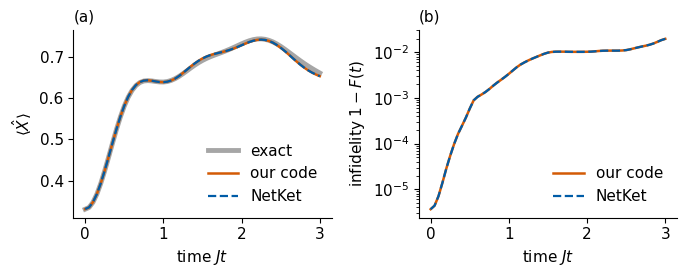

In [20]:
def netket_evolve(vstate, eps):
    # nkx.TDVP in imaginary time with H(g_i) up to TAU_MAX, then in real time with H(g_f) up to T_MAX, RK4 as in (28)
    rec = {key: [] for key in ("E_net", "X_net", "infid", "X_est")}
    qgt = nk.optimizer.qgt.QGTJacobianDense(holomorphic=True, diag_shift=0.0)
    solver = partial(shifted_solve, eps=eps)
    def record_imag(step, log_data, driver):
        v = our_order(driver.state); rec["E_net"].append(np.vdot(v, H_I @ v).real); return True
    def record_real(step, log_data, driver):
        v = our_order(driver.state); n = int(round(float(driver.t) / (DT * EVERY)))
        rec["X_net"].append(np.vdot(v, X_MAT @ v).real); rec["infid"].append(1 - abs(np.vdot(PSI_T[n], v)) ** 2); return True
    t0 = time.perf_counter()
    imag = nkx.TDVP(H_NK[G_I], vstate, nkx.dynamics.RK4(dt=DTAU), propagation_type="imag", qgt=qgt, linear_solver=solver)
    imag.run(TAU_MAX, tstops=TAU_GRID, callback=record_imag, show_progress=False)
    real = nkx.TDVP(H_NK[G_F], vstate, nkx.dynamics.RK4(dt=DT), propagation_type="real", qgt=qgt, linear_solver=solver)
    log = nk.logging.RuntimeLog()
    real.run(T_MAX, out=log, obs={"X": X_OP}, tstops=T_GRID, callback=record_real, show_progress=False)
    rec = {k: np.array(v) for k, v in rec.items()}
    rec["X_est"] = np.asarray(log.data["X"]["Mean"]).real              # estimate of <X> from NetKet's averages
    rec["seconds"] = time.perf_counter() - t0
    rec["gs_rel_err"] = (rec["E_net"][-1] - E0_I) / abs(E0_I)
    return rec

if HAVE_NETKET:
    NK = {}
    NK["sums"] = netket_evolve(nk.vqs.FullSumState(hi, **model_kwargs(THETA0, M_MAIN)), eps=ExactSums.eps)
    rn = NK["sums"]
    print(f"NetKet FullSumState, M = {M_MAIN}: relative ground-state energy error {rn['gs_rel_err']:.3e} "
          f"(ours {r8['gs_rel_err']:.3e}), infidelity at t = 3 {rn['infid'][-1]:.3e} (ours {r8['infid'][-1]:.3e}), {rn['seconds']:.0f} s")
    print(f"max |<X>_NetKet - <X>_ours| = {np.max(np.abs(rn['X_net'] - r8['X_net'])):.1e},  "
          f"max |<X>_NetKet - <X>_exact| = {np.max(np.abs(rn['X_net'] - X_EXACT)):.4f}")

    # --- figure (drawing code may be skipped) ---
    def draw_nk_a(ax):
        ax.plot(T_GRID, X_EXACT, color=COL["exact"], lw=3.5, alpha=0.35, label="exact")
        ax.plot(T_GRID, r8["X_net"], color=COL["sums"], lw=1.8, label="our code")
        ax.plot(T_GRID, rn["X_net"], color=COL["netket"], lw=1.6, ls="--", label="NetKet")
        ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"$\langle\hat X\rangle$"); ax.legend(frameon=False, loc="lower right")
    def draw_nk_b(ax):
        ax.semilogy(T_GRID, r8["infid"], color=COL["sums"], lw=1.8, label="our code")
        ax.semilogy(T_GRID, rn["infid"], color=COL["netket"], lw=1.6, ls="--", label="NetKet")
        ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"infidelity $1-F(t)$"); ax.legend(frameon=False)
    panels("fig_lab088_netket", [draw_nk_a, draw_nk_b])

NetKet reaches the same relative energy error after imaginary time as our code, $2.3\times10^{-6}$ in all printed digits. In real time the two curves of $\langle\hat X\rangle(t)$ differ by at most $9\times10^{-6}$, far below their common deviation of $0.010$ from the exact curve. In the figure they lie on top of each other. The infidelities at $Jt=3$ agree to three digits.

With snapshots NetKet uses `MCState`. We give it 1000 Metropolis chains with one snapshot per chain and one discarded sweep before it, so that every evaluation of the velocity makes two sweeps, as our `Snapshots` does. We warm the chains up with 100 sweeps and use $\epsilon=10^{-4}$. NetKet's sampler proposes the flip of a randomly chosen site, whereas ours goes through the sites in order. Its random numbers also differ from ours, so the two sampled runs agree only within their statistical noise.

NetKet MCState, M = 8: relative ground-state energy error 6.84e-05 (ours 6.91e-05), max |<X>_network - <X>_exact| 0.0150 (ours 0.0135), infidelity at t = 3 4.19e-02 (ours 4.13e-02), 72 s


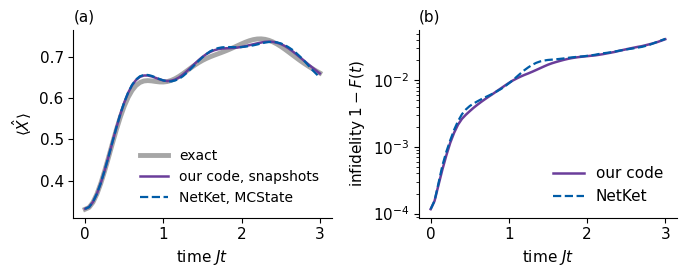

In [21]:
if HAVE_NETKET:
    sampler = nk.sampler.MetropolisLocal(hi, n_chains=1000)                 # single flips, rule (30), 1000 chains
    vs_mc = nk.vqs.MCState(sampler, n_samples=1000, n_discard_per_chain=1, sampler_seed=101, seed=101,
                           **model_kwargs(THETA0, M_MAIN))
    vs_mc.sample(n_discard_per_chain=100)                                    # 100 sweeps to forget the random start
    NK["snap"] = netket_evolve(vs_mc, eps=Snapshots.eps)
    rm = NK["snap"]
    print(f"NetKet MCState, M = {M_MAIN}: relative ground-state energy error {rm['gs_rel_err']:.2e} (ours {rs['gs_rel_err']:.2e}), "
          f"max |<X>_network - <X>_exact| {np.max(np.abs(rm['X_net'] - X_EXACT)):.4f} (ours {np.max(np.abs(rs['X_net'] - X_EXACT)):.4f}), "
          f"infidelity at t = 3 {rm['infid'][-1]:.2e} (ours {rs['infid'][-1]:.2e}), {rm['seconds']:.0f} s")

    # --- figure (drawing code may be skipped) ---
    def draw_nkmc_a(ax):
        ax.plot(T_GRID, X_EXACT, color=COL["exact"], lw=3.5, alpha=0.35, label="exact")
        ax.plot(T_GRID, rs["X_net"], color=COL["snap"], lw=1.8, label="our code, snapshots")
        ax.plot(T_GRID, rm["X_net"], color=COL["netket"], lw=1.6, ls="--", label="NetKet, MCState")
        ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"$\langle\hat X\rangle$"); ax.legend(frameon=False, loc="lower right", fontsize=10)
    def draw_nkmc_b(ax):
        ax.semilogy(T_GRID, rs["infid"], color=COL["snap"], lw=1.8, label="our code")
        ax.semilogy(T_GRID, rm["infid"], color=COL["netket"], lw=1.6, ls="--", label="NetKet")
        ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"infidelity $1-F(t)$"); ax.legend(frameon=False)
    panels("fig_lab088_netket_snapshots", [draw_nkmc_a, draw_nkmc_b])
    TIMES["13 NetKet"] = time.perf_counter() - t_section

NetKet's sampled run ends the imaginary time with a relative energy error of $6.8\times10^{-5}$, against $6.9\times10^{-5}$ for ours. Its $\langle\hat X\rangle$ deviates from the exact curve by at most $0.015$, against $0.014$ for ours, and its infidelity at $Jt=3$ is $4.2\times10^{-2}$, against $4.1\times10^{-2}$. The two sampled runs use different random numbers and differ slightly along the way, most visibly in the infidelity of panel (b) between $Jt\approx1.3$ and $1.5$, and they end with the same accuracy.

## 14. At home. Entanglement entropies from snapshots

This section took 129 seconds in the recorded run. Section 11 obtained the Schmidt weights from the whole table of $2^N$ amplitudes, which cannot be stored for a long chain. Every other quantity computed so far was an average of a local value over $p(\mathbf s)$, equation (12), and could therefore be estimated from snapshots. The von Neumann entropy applies a logarithm to all the weights together, through the eigenvalues of a matrix, and no function of a single configuration has $S_{\rm vN}$ as its average. The purity, which gives $S_2$, is an average over pairs of snapshots, and the density matrix of a small block, whose eigenvalues are the Schmidt weights and give $S_{\rm vN}$, is an average over single snapshots. For the network both averages take a form that contains only the hidden units. We keep the cut after $\ell=4$ sites, with the left bits $a$ and the right bits $b$ of Section 11.

Everything that measurements on the left block alone can reveal is contained in the reduced density matrix $\hat\rho_A$ of that block. An operator $\hat A$ that acts only on the left sites leaves the right bits unchanged, so in its expectation value the sum over the right bits can be carried out first,
$$\langle\hat A\rangle=\frac1Z\sum_{a,a',b}\psi^*(a',b)\,A_{a'a}\,\psi(a,b)=\sum_{a,a'}A_{a'a}\,\rho_A(a,a')={\rm Tr}\,\hat\rho_A\hat A ,\qquad \rho_A(a,a')=\frac1Z\sum_b\psi(a,b)\,\psi^*(a',b) , \tag{41}$$
where $A_{a'a}=\langle a'|\hat A|a\rangle$ and $\rho_A(a,a')=\langle a|\hat\rho_A|a'\rangle$ are matrices of $2^\ell\times2^\ell$ entries. In terms of the matrix (31), $\rho_A=\Psi\Psi^\dagger$, and the decomposition (33) gives $\rho_A=U\,{\rm diag}(\lambda_1^2,\lambda_2^2,\dots)\,U^\dagger$, so the eigenvalues of $\rho_A$ are the Schmidt weights. They are the probabilities of a set of orthogonal states of the left block that reproduces every measurement on that block. For a product state one weight is one, and the left block is in a pure state. For an entangled state several weights are nonzero, and the left block alone behaves as a mixture. The purity of the block,
$$\gamma_A={\rm Tr}\,\hat\rho_A^2=\sum_k\lambda_k^4,\qquad S_2=-\log_2\gamma_A , \tag{42}$$
equals one for a product state and lies below one when the block is entangled with the rest of the chain. For the two-spin ground state $\gamma_A=0.947^2+0.053^2=0.900$.

The purity can be written as an average over two independent snapshots $\mathbf s=(a,b)$ and $\mathbf s'=(a',b')$, by the replica or swap trick of Ref. [9]. We insert equation (41) into $\gamma_A=\sum_{a,a'}\rho_A(a,a')\rho_A(a',a)$, rename the summation labels $a\leftrightarrow a'$ in the second line, and multiply and divide by $\psi(a,b)\psi(a',b')$ in the third,
$$\begin{aligned}\gamma_A&=\frac1{Z^2}\sum_{a,a',b,b'}\psi(a,b)\,\psi^*(a',b)\,\psi(a',b')\,\psi^*(a,b')\\&=\frac1{Z^2}\sum_{a,a',b,b'}\psi(a',b)\,\psi^*(a,b)\,\psi(a,b')\,\psi^*(a',b')\\&=\sum_{\mathbf s,\mathbf s'}p(\mathbf s)\,p(\mathbf s')\,\frac{\psi(a',b)\,\psi(a,b')}{\psi(a,b)\,\psi(a',b')} ,\end{aligned}\tag{43}$$
where the last line used $|\psi(a,b)|^2/Z=p(\mathbf s)$ and $|\psi(a',b')|^2/Z=p(\mathbf s')$. The purity is therefore the average of the amplitude ratio for exchanging the left bits of the two snapshots. For the two-spin ground state $p(00)=p(11)=1/(2+2\zeta^2)=0.362$ and $p(01)=p(10)=\zeta^2/(2+2\zeta^2)=0.138$. The pair $00,11$ exchanges its left bits into $10,01$, with the ratio $\psi(10)\psi(01)/[\psi(00)\psi(11)]=\zeta^2=0.382$, and the pair $01,10$ gives $00,11$ and the ratio $1/\zeta^2=2.618$. A pair with equal left bits or equal right bits returns the same two configurations, with the ratio 1. Weighted with the probabilities of the pairs,
$$\gamma_A=\underbrace{1-2\cdot0.362^2-2\cdot0.138^2}_{\text{ratio }1}+\underbrace{2\cdot0.362^2\cdot0.382}_{(00,11)\text{ and }(11,00)}+\underbrace{2\cdot0.138^2\cdot2.618}_{(01,10)\text{ and }(10,01)}=0.900 , \tag{44}$$
the purity of the Schmidt weights. The noise of this estimator grows with the entanglement, because the average $\gamma_A=2^{-S_2}$ becomes small for a strongly entangled cut, whereas single swap ratios remain of order one. For a fixed number of snapshot pairs the relative error of the mean therefore grows roughly as $2^{S_2}$.

We collect the visible biases of the network in $V_A(a)=\sum_{i<\ell}a_i\sigma_i$ and $V_B(b)=\sum_{i\ge\ell}a_i\sigma_i$ and split the hidden inputs as in equation (36), so that the amplitude (10) reads
$$\psi(a,b)=e^{V_A(a)}\,e^{V_B(b)}\prod_{j=1}^{M}2\cosh\big(b_j+L_j(a)+R_j(b)\big) . \tag{45}$$
In the ratio of four amplitudes in equation (43) each visible factor appears once in the numerator and once in the denominator,
$$\frac{\overbrace{e^{V_A(a')}e^{V_B(b)}}^{\psi(a',b)}\;\overbrace{e^{V_A(a)}e^{V_B(b')}}^{\psi(a,b')}}{\underbrace{e^{V_A(a)}e^{V_B(b)}}_{\psi(a,b)}\;\underbrace{e^{V_A(a')}e^{V_B(b')}}_{\psi(a',b')}}=1 , \tag{46}$$
and the factors $2^M$ of the numerator and the denominator cancel as well. Only the hidden units remain,
$$\frac{\psi(a',b)\,\psi(a,b')}{\psi(a,b)\,\psi(a',b')}=\prod_{j=1}^{M}\frac{\cosh\big(b_j+L_j(a')+R_j(b)\big)\,\cosh\big(b_j+L_j(a)+R_j(b')\big)}{\cosh\big(b_j+L_j(a)+R_j(b)\big)\,\cosh\big(b_j+L_j(a')+R_j(b')\big)} . \tag{47}$$
A unit connected to the right spins only has $L_j=0$, and its factor $\cosh\big(b_j+R_j(b)\big)\cosh\big(b_j+R_j(b')\big)/\big[\cosh\big(b_j+R_j(b)\big)\cosh\big(b_j+R_j(b')\big)\big]$ equals 1. A unit connected to the left spins only has $R_j=0$ and the factor 1 for the same reason. The swap ratio therefore contains only the hidden units connected to both sides, the same units that bound the Schmidt rank in equation (40). The code evaluates each hyperbolic cosine through the function `log2cosh` of Section 4, which returns the logarithm of twice the hyperbolic cosine without overflow for large inputs, and the factors 2 cancel in the ratio.

We check the purity (44) of the two spins by a sum over all 16 pairs of configurations. We then compare the ratio (47) with the ratio of four amplitudes (10) for 1000 random pairs of configurations, for the network at $Jt=3$ and for the random network of Section 11, whose visible biases are nonzero, and print the factor of every hidden unit in equation (47) for the masked random network with one crossing unit.

In [22]:
t_section = time.perf_counter()
CUT = N // 2                                                   # ell = 4 sites left of the cut
# two-spin example of equations (43) and (44): amplitudes (1, zeta, zeta, 1) for 00, 01, 10, 11, cut after spin 0
psi_two = np.array([1.0, ZETA, ZETA, 1.0]); p_two = psi_two ** 2 / np.sum(psi_two ** 2)
gamma_two = 0.0
for s, s_ in itertools.product(range(4), repeat=2):                          # all 16 ordered pairs of configurations
    (left, right), (left_, right_) = divmod(s, 2), divmod(s_, 2)              # left bit a and right bit b of each configuration
    gamma_two += p_two[s] * p_two[s_] * psi_two[2 * left_ + right] * psi_two[2 * left + right_] / (psi_two[s] * psi_two[s_])
print(f"two spins: p(00) = {p_two[0]:.3f}, p(01) = {p_two[1]:.3f}, swap ratios zeta^2 = {ZETA ** 2:.3f} and 1/zeta^2 = {1 / ZETA ** 2:.3f}")
print(f"  purity from the swap average (43): {gamma_two:.4f};  sum of the squared Schmidt weights (42): {np.sum(w_formula ** 2):.4f};  "
      f"S_2 = {-np.log2(gamma_two):.3f} bits")

def split_inputs(theta, M, s):
    # equation (45): visible parts V_A, V_B and hidden inputs L_j (left spins), R_j (right spins) of configurations s (n, N)
    a, b, W = unpack(theta, M)
    return s[:, :CUT] @ a[:CUT], s[:, CUT:] @ a[CUT:], s[:, :CUT] @ W[:CUT], s[:, CUT:] @ W[CUT:]

def swap_ratio(theta, M, s1, s2):
    # equation (47) for s1 = (a, b) and s2 = (a', b'); returns the ratio, shape (n,), and the factor of every hidden unit, shape (n, M)
    b = unpack(theta, M)[1]
    _, _, L1, R1 = split_inputs(theta, M, s1)
    _, _, L2, R2 = split_inputs(theta, M, s2)
    ln_factors = (log2cosh(b + L2 + R1) + log2cosh(b + L1 + R2)          # numerator: (a', b) and (a, b')
                  - log2cosh(b + L1 + R1) - log2cosh(b + L2 + R2))       # denominator: (a, b) and (a', b')
    return np.exp(np.sum(ln_factors, axis=1)), np.exp(ln_factors)

def swap_ratio_from_amplitudes(theta, M, s1, s2):
    # the ratio of four amplitudes in equation (43), each from the full amplitude (10)
    swapped1 = np.concatenate([s2[:, :CUT], s1[:, CUT:]], axis=1)       # (a', b)
    swapped2 = np.concatenate([s1[:, :CUT], s2[:, CUT:]], axis=1)       # (a, b')
    return np.exp(log_psi(theta, M, swapped1)[0] + log_psi(theta, M, swapped2)[0] - log_psi(theta, M, s1)[0] - log_psi(theta, M, s2)[0])

# check (may be skipped): equation (47) against the ratio of four amplitudes for 1000 random pairs of configurations
rng_pairs = np.random.default_rng(88)
pairs = (CONF[rng_pairs.integers(0, DIM, 1000)], CONF[rng_pairs.integers(0, DIM, 1000)])
NETWORKS_14 = (("network at Jt = 3, M = 8", RUNS["sums", M_MAIN]["thetas"][-1], M_MAIN),
               ("random network of Section 11, M = 6", np.concatenate([a_r, b_r, W_r.ravel()]), M_RAND))
for label, th, M in NETWORKS_14:
    diff = np.max(np.abs(swap_ratio(th, M, *pairs)[0] / swap_ratio_from_amplitudes(th, M, *pairs) - 1))
    print(f"{label}: largest |a_i| {np.max(np.abs(unpack(th, M)[0])):.2f},  largest relative difference of (47) from the amplitude form {diff:.0e}")
    assert diff < 1e-10
# factor of every hidden unit in (47) for the masked random network with one crossing unit
_, unit_factors = swap_ratio(np.concatenate([a_r, b_r, (W_r * crossing_mask(1)).ravel()]), M_RAND, *pairs)   # shape (1000, 6)
for j in range(M_RAND):
    print(f"  hidden unit {j}, connected to {unit_side(j, 1):5s}: largest |factor - 1| over the 1000 pairs {np.max(np.abs(unit_factors[:, j] - 1)):.1e}")

two spins: p(00) = 0.362, p(01) = 0.138, swap ratios zeta^2 = 0.382 and 1/zeta^2 = 2.618
  purity from the swap average (43): 0.9000;  sum of the squared Schmidt weights (42): 0.9000;  S_2 = 0.152 bits
network at Jt = 3, M = 8: largest |a_i| 0.00,  largest relative difference of (47) from the amplitude form 1e-14
random network of Section 11, M = 6: largest |a_i| 1.26,  largest relative difference of (47) from the amplitude form 1e-14
  hidden unit 0, connected to both : largest |factor - 1| over the 1000 pairs 1.8e+03
  hidden unit 1, connected to left : largest |factor - 1| over the 1000 pairs 4.6e-16
  hidden unit 2, connected to right: largest |factor - 1| over the 1000 pairs 5.0e-16
  hidden unit 3, connected to left : largest |factor - 1| over the 1000 pairs 4.6e-16
  hidden unit 4, connected to right: largest |factor - 1| over the 1000 pairs 5.0e-16
  hidden unit 5, connected to left : largest |factor - 1| over the 1000 pairs 4.6e-16


Multiplying and dividing each term of equation (41) by $\psi^*(a,b)$ writes $\rho_A$ of a small left block as an average over snapshots,
$$\rho_A(a,a')=\sum_b\frac{|\psi(a,b)|^2}{Z}\,\frac{\psi^*(a',b)}{\psi^*(a,b)}=\sum_{\mathbf s\,:\,s_A=a}p(\mathbf s)\,\frac{\psi^*(a',s_B)}{\psi^*(s_A,s_B)} , \tag{48}$$
where $s_A$ and $s_B$ are the left and right bits of a configuration and the last sum runs over the configurations whose left bits equal $a$. Each snapshot fills the row $a=s_A$ of the matrix with the $2^\ell$ ratios obtained by replacing its left bits by every $a'$. We average over the snapshots, make the result Hermitian by taking $(\rho_A+\rho_A^\dagger)/2$ and diagonalise it. Its negative eigenvalues come from the noise, and we set them to zero, renormalise the others to sum one and evaluate $S_{\rm vN}$. For two spins, $\ell=1$, the snapshot 00 fills row 0 with the ratios $\psi(00)/\psi(00)=1$ and $\psi(10)/\psi(00)=\zeta$, and the snapshot 01 fills it with $\psi(01)/\psi(01)=1$ and $\psi(11)/\psi(01)=1/\zeta$. With $p(00)=0.362$ and $p(01)=0.138$,
$$\rho_A(0,0)=0.362+0.138=0.5,\qquad \rho_A(0,1)=0.362\,\zeta+0.138/\zeta=0.447 , \tag{49}$$
and by symmetry $\rho_A(1,1)=0.5$ and $\rho_A(1,0)=0.447$, so the eigenvalues $0.5\pm0.447$ are the Schmidt weights $0.947$ and $0.053$.

For the network the ratio in equation (48) needs only what changes when the left bits $s_A$ are replaced by $a'$. With $\sigma'_i$ the spins of $a'$ and the amplitude (45), the right visible factor $e^{V_B(s_B)}$ and the factors 2 cancel,
$$\frac{\psi^*(a',s_B)}{\psi^*(s_A,s_B)}=\Big[e^{V_A(a')-V_A(s_A)}\prod_{j=1}^{M}\frac{\cosh\big(b_j+L_j(a')+R_j(s_B)\big)}{\cosh\big(b_j+L_j(s_A)+R_j(s_B)\big)}\Big]^*,\qquad V_A(a')-V_A(s_A)=\sum_{i<\ell}a_i(\sigma'_i-\sigma_i) . \tag{50}$$
The code prepares the table of $L_j(a')$ and $V_A(a')$ for all $2^\ell$ left configurations once, $2^\ell\times M$ numbers. For each snapshot it computes $R_j(s_B)$, and the row of $\rho_A$ then costs about $2^\ell\cdot M$ hyperbolic cosines, whatever the length of the chain. The matrix has $4^\ell$ entries and each snapshot fills only one row of $2^\ell$ of them, so the total number of snapshots must be far larger than $2^\ell$. The statistical errors of the matrix elements spread the small eigenvalues, so that the entropy of the estimated matrix has a systematic error for few snapshots, which grows with the dimension $2^\ell$.

We first check the two-spin numbers (49) and compare the ratios (50) with the ratios of full amplitudes (10) for the two networks above. We then apply the exact route, the swap estimate and the block estimate to the evolution with exact sums and $M=8$ of Section 9, at the parameters stored every $0.1/J$. The exact entropies come from the exactly evolved states of Section 2, and the network entropies from its 256 amplitudes, both with equation (34). For the estimates we keep two independent sets of 4000 Metropolis chains running along the stored parameters and use one snapshot per chain. The chains make 100 sweeps at the first stored time and 20 sweeps at every following one. Equation (43) with the ratio (47) pairs chain $n$ of the first set with chain $n$ of the second, and equation (48) with the ratio (50) uses the 8000 snapshots of both sets. Finally, at $t=3/J$, we repeat both estimates three times with fresh chains after 30 sweeps, for 1000 to 64000 snapshots, to show how the systematic error and the noise depend on the number of snapshots.

two spins: rho_A(0,0) = 0.500, rho_A(0,1) = 0.447, rho_A(1,1) = 0.500, eigenvalues [0.9472 0.0528]
network at Jt = 3, M = 8: largest relative difference of the ratios (50) from full amplitudes 8e-15
random network of Section 11, M = 6: largest relative difference of the ratios (50) from full amplitudes 1e-14
t = 3, network: S_vN = 1.4305 bits, S_2 = 1.0947 bits; equation (43) summed over all pairs gives S_2 = 1.0947
  t     S_vN exact  network  rho estimate     S_2 exact  network  swap estimate
  0.0    0.993      0.993    1.000            0.980     0.980    0.980 +- 0.022
  0.5    1.016      1.021    1.035            0.971     0.972    0.965 +- 0.026
  1.0    1.224      1.234    1.258            1.029     1.023    1.063 +- 0.033
  1.5    1.326      1.301    1.307            0.982     0.941    0.930 +- 0.028
  2.0    1.187      1.173    1.169            0.767     0.760    0.762 +- 0.024
  2.5    1.134      1.122    1.121            0.766     0.755    0.732 +- 0.020
  3.0    1.488      

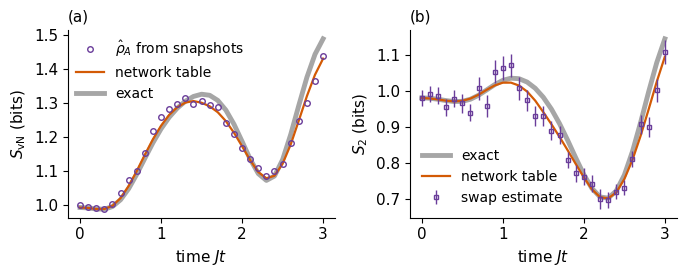

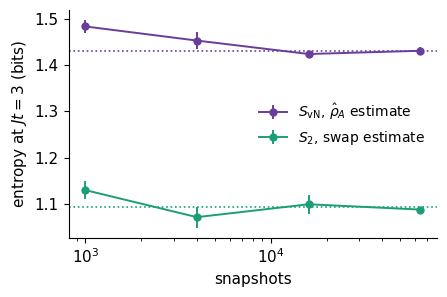

In [23]:
LEFT = (1 - 2 * np.array(list(itertools.product([0, 1], repeat=CUT)))).astype(float)   # the 16 left blocks a, in index order

def entropies_from_vector(psi):
    # equations (31), (33) and (34) with the functions of Section 11, cut after ell = 4 sites
    return entropies(schmidt_weights(psi, CUT))

def swap_estimate(theta, M, s1, s2):
    # equation (43) with the ratio (47) for the pairs (s1[n], s2[n]); returns S_2 and its statistical error from the scatter of the ratios
    ratio = swap_ratio(theta, M, s1, s2)[0].real                        # real part, the mean is real
    mean, err = ratio.mean(), ratio.std(ddof=1) / np.sqrt(len(ratio))
    return -np.log2(mean), err / (mean * np.log(2))

def block_ratios(theta, M, s):
    # equation (50): psi*(a', s_B) / psi*(s_A, s_B) for every snapshot (rows) and all 16 left blocks a' (columns), shape (n, 16)
    a, b, W = unpack(theta, M)
    L_table, V_table = LEFT @ W[:CUT], LEFT @ a[:CUT]                   # L_j(a') and V_A(a') of the 16 left blocks, computed once
    V_A, _, L, R = split_inputs(theta, M, s)                            # V_A(s_A), L_j(s_A) and R_j(s_B) of every snapshot
    ln_new = V_table[None, :] + np.sum(log2cosh(b + L_table[None, :, :] + R[:, None, :]), axis=2)   # 16 x M cosh per snapshot
    ln_old = V_A + np.sum(log2cosh(b + L + R), axis=1)
    return np.exp(np.conj(ln_new - ln_old[:, None]))

def block_ratios_from_amplitudes(theta, M, s):
    # the same ratios from full amplitudes (10) of the 16 configurations with the left bits replaced, for the check below
    n = len(s)
    replaced = np.concatenate([np.broadcast_to(LEFT, (n, 2 ** CUT, CUT)),
                               np.broadcast_to(s[:, None, CUT:], (n, 2 ** CUT, N - CUT))], axis=2).reshape(-1, N)
    return np.exp(np.conj(log_psi(theta, M, replaced)[0].reshape(n, 2 ** CUT) - log_psi(theta, M, s)[0][:, None]))

def rho_estimate(theta, M, s):
    # equation (48): each snapshot fills row a = s_A of the matrix with its 16 ratios (50)
    n = len(s)
    ratios = block_ratios(theta, M, s)
    row = ((1 - s[:, :CUT]) / 2 * (1 << (CUT - 1 - np.arange(CUT)))).sum(axis=1).astype(int)   # index of s_A
    rho = np.zeros((2 ** CUT, 2 ** CUT), dtype=complex)
    np.add.at(rho, row, ratios)
    rho = rho / n
    rho = (rho + rho.conj().T) / 2                                 # Hermitian part
    lam = np.linalg.eigvalsh(rho)                                  # Schmidt weights w_k of the estimated matrix
    lam = np.clip(lam, 0.0, None)                                  # negative eigenvalues come from noise: set to zero
    lam = lam / lam.sum()                                          # and renormalise the others to sum one
    lam = lam[lam > 0]
    return float(-np.sum(lam * np.log2(lam)))

# two-spin example (49), ell = 1: the snapshot s fills row s_A with psi(a', s_B) / psi(s) for a' = 0, 1, weighted with p(s)
rho_two = np.zeros((2, 2))
for s in range(4):
    left, right = divmod(s, 2)
    rho_two[left] += p_two[s] * psi_two[2 * np.arange(2) + right] / psi_two[s]
print(f"two spins: rho_A(0,0) = {rho_two[0, 0]:.3f}, rho_A(0,1) = {rho_two[0, 1]:.3f}, rho_A(1,1) = {rho_two[1, 1]:.3f}, "
      f"eigenvalues {np.round(np.linalg.eigvalsh(rho_two)[::-1], 4)}")
# check (may be skipped): the ratios (50) against full amplitudes for 1000 random configurations
for label, th, M in NETWORKS_14:
    diff = np.max(np.abs(block_ratios(th, M, pairs[0]) / block_ratios_from_amplitudes(th, M, pairs[0]) - 1))
    print(f"{label}: largest relative difference of the ratios (50) from full amplitudes {diff:.0e}")
    assert diff < 1e-10

# check (may be skipped): with all 256 configurations weighted by p(s), equation (43) with the ratio (47) is exact
theta_c = RUNS["sums", M_MAIN]["thetas"][-1]
psi_c = state_vector(theta_c, M_MAIN); p_c = np.abs(psi_c) ** 2
S_vn_c, S2_c = entropies_from_vector(psi_c)
i1, i2 = np.repeat(np.arange(DIM), DIM), np.tile(np.arange(DIM), DIM)          # all pairs (s, s')
purity_pairs = np.sum(p_c[i1] * p_c[i2] * swap_ratio(theta_c, M_MAIN, CONF[i1], CONF[i2])[0])
assert abs(-np.log2(purity_pairs.real) - S2_c) < 1e-10
print(f"t = 3, network: S_vN = {S_vn_c:.4f} bits, S_2 = {S2_c:.4f} bits; equation (43) summed over all pairs gives S_2 = {-np.log2(purity_pairs.real):.4f}")

# entropies along the evolution
r_ent = RUNS["sums", M_MAIN]
T_ENT = T_GRID[::2]                                            # 0, 0.1, ..., 3, where the parameters were stored
ENT = {key: [] for key in ("vn_exact", "s2_exact", "vn_net", "s2_net", "vn_rho", "s2_swap", "s2_swap_err")}
set1, set2 = Snapshots(seed=131, chains=4000), Snapshots(seed=132, chains=4000)
for n_t, (t, theta_t) in enumerate(zip(T_ENT, r_ent["thetas"])):
    for value, key in zip(entropies_from_vector(PSI_T[2 * n_t]), ("vn_exact", "s2_exact")):
        ENT[key].append(value)
    for value, key in zip(entropies_from_vector(state_vector(theta_t, M_MAIN)), ("vn_net", "s2_net")):
        ENT[key].append(value)
    for chains in (set1, set2):
        for _ in range(100 if n_t == 0 else 20):
            chains.sweep(theta_t, M_MAIN)
    s1, s2 = set1.sigma.copy(), set2.sigma.copy()
    s2_val, s2_err = swap_estimate(theta_t, M_MAIN, s1, s2)
    ENT["s2_swap"].append(s2_val); ENT["s2_swap_err"].append(s2_err)
    ENT["vn_rho"].append(rho_estimate(theta_t, M_MAIN, np.concatenate([s1, s2])))
ENT = {k: np.array(v) for k, v in ENT.items()}
print("  t     S_vN exact  network  rho estimate     S_2 exact  network  swap estimate")
for n_t in range(0, len(T_ENT), 5):
    print(f"  {T_ENT[n_t]:3.1f}    {ENT['vn_exact'][n_t]:.3f}      {ENT['vn_net'][n_t]:.3f}    {ENT['vn_rho'][n_t]:.3f}"
          f"            {ENT['s2_exact'][n_t]:.3f}     {ENT['s2_net'][n_t]:.3f}    {ENT['s2_swap'][n_t]:.3f} +- {ENT['s2_swap_err'][n_t]:.3f}")
print(f"largest |S_vN network - exact| {np.max(np.abs(ENT['vn_net'] - ENT['vn_exact'])):.3f};  "
      f"largest |rho estimate - network| {np.max(np.abs(ENT['vn_rho'] - ENT['vn_net'])):.3f};  "
      f"largest |swap estimate - network| / error {np.max(np.abs(ENT['s2_swap'] - ENT['s2_net']) / ENT['s2_swap_err']):.1f}")

# systematic error and noise at t = 3 against the number of snapshots
N_SNAP = (1000, 4000, 16000, 64000)
BIAS = {"vn": [], "s2": []}
for n_s in N_SNAP:
    vn_rep, s2_rep = [], []
    for rep in range(3):
        c1, c2 = Snapshots(seed=1000 * rep + n_s, chains=n_s), Snapshots(seed=1000 * rep + n_s + 1, chains=n_s)
        for _ in range(30):
            c1.sweep(theta_c, M_MAIN); c2.sweep(theta_c, M_MAIN)
        vn_rep.append(rho_estimate(theta_c, M_MAIN, c1.sigma))
        s2_rep.append(swap_estimate(theta_c, M_MAIN, c1.sigma, c2.sigma)[0])
    BIAS["vn"].append(vn_rep); BIAS["s2"].append(s2_rep)
BIAS = {k: np.array(v) for k, v in BIAS.items()}
print(" snapshots   S_vN from rho estimate (three sets)      S_2 from swaps (three sets)")
for n_s, vn_rep, s2_rep in zip(N_SNAP, BIAS["vn"], BIAS["s2"]):
    print(f"  {n_s:6d}     " + "  ".join(f"{x:.3f}" for x in vn_rep) + "                " + "  ".join(f"{x:.3f}" for x in s2_rep))
print(f"network at t = 3: S_vN = {S_vn_c:.3f}, S_2 = {S2_c:.3f}")

# --- figure (drawing code may be skipped) ---
def draw_ent_a(ax):
    ax.plot(T_ENT, ENT["vn_exact"], color=COL["exact"], lw=3.5, alpha=0.35, label="exact")
    ax.plot(T_ENT, ENT["vn_net"], color=COL["sums"], lw=1.6, label="network table")
    ax.plot(T_ENT, ENT["vn_rho"], "o", ms=4, mfc="none", color=COL["snap"], label=r"$\hat\rho_A$ from snapshots")
    ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"$S_{\rm vN}$ (bits)")
    handles, labels = ax.get_legend_handles_labels()                # longest label on top, clear of the data near Jt = 1.3
    ax.legend(handles[::-1], labels[::-1], frameon=False, loc="upper left", borderaxespad=0.2, fontsize=10)
def draw_ent_b(ax):
    ax.plot(T_ENT, ENT["s2_exact"], color=COL["exact"], lw=3.5, alpha=0.35, label="exact")
    ax.plot(T_ENT, ENT["s2_net"], color=COL["sums"], lw=1.6, label="network table")
    ax.errorbar(T_ENT, ENT["s2_swap"], yerr=ENT["s2_swap_err"], fmt="s", ms=3.5, mfc="none", color=COL["snap"], lw=1, label="swap estimate")
    ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"$S_2$ (bits)"); ax.legend(frameon=False, loc="lower left", fontsize=10)
panels("fig_lab088_entanglement", [draw_ent_a, draw_ent_b])
def draw_bias(ax):
    for key, c, lab, ref in (("vn", COL["snap"], r"$S_{\rm vN}$, $\hat\rho_A$ estimate", S_vn_c), ("s2", COL["teal"], r"$S_2$, swap estimate", S2_c)):
        ax.errorbar(N_SNAP, BIAS[key].mean(axis=1), yerr=BIAS[key].std(axis=1, ddof=1), fmt="o-", color=c, ms=5, lw=1.4, label=lab)
        ax.axhline(ref, color=c, ls=":", lw=1.2)
    ax.set_xscale("log"); ax.set_xlabel("snapshots"); ax.set_ylabel("entropy at $Jt=3$ (bits)"); ax.legend(frameon=False, fontsize=10)
one_panel("fig_lab088_entropy_bias", draw_bias)
TIMES["14 entanglement"] = time.perf_counter() - t_section

The ground state at $g_i$ carries almost one bit of entanglement across the cut, $S_{\rm vN}=0.99$ bits. It is close to the superposition of all spins up and all spins down, in which the bits of the left half fix those of the right half. After the change of the field the von Neumann entropy grows to $1.33$ bits near $Jt=1.5$, decreases to $1.07$ bits near $Jt=2.3$ and rises to $1.49$ bits at $Jt=3$. The entropy of the network follows the exact curve with a largest deviation of $0.06$ bits, at the end of the interval, where its infidelity is largest. In panel (a), the estimate from $\hat\rho_A$ with 8000 snapshots lies within $0.025$ bits of the entropy of the network at all times. In panel (b), the swap estimate of $S_2$ scatters around the $S_2$ of the network, with deviations of at most $1.8$ statistical errors, and the printed statistical errors lie between $0.020$ and $0.033$ bits. At all times $S_2$ lies below $S_{\rm vN}$.

The last figure shows both estimates at $Jt=3$ against the number of snapshots, as the mean and the standard deviation of three independent sets. Dotted lines mark the exact values of the network. With 1000 snapshots the estimate of $S_{\rm vN}$ from $\hat\rho_A$ lies about $0.05$ bits above the exact value, a systematic error caused by the noise in the eigenvalues of the estimated matrix. From 16000 snapshots on, this systematic error lies within the scatter of the three sets. The swap estimate scatters around the exact $S_2$, and its scatter shrinks as the number of snapshots grows.

The entanglement grows after the change of the field, and entanglement that grows in time limits every method that stores states with a bounded entanglement.

## 15. At home. Phases of the amplitudes in an observable

This section took less than one second in the recorded run. The phases that the amplitudes acquire after the change of the field can be seen in a Pauli string with a $\hat\sigma^y$. Lab 080 gave the local value of $\hat\sigma^y_i$, which flips spin $i$ and multiplies by $-i\sigma_i$, with $\sigma_i$ taken before the flip. For the string $\hat\sigma^z_i\hat\sigma^y_{i+1}$ equation (12) gives
$$\big(\hat\sigma^z_i\hat\sigma^y_{i+1}\big)_{\rm loc}(\mathbf s)=\sigma_i\,\big(-i\sigma_{i+1}\big)\,\frac{\psi(\mathbf s^{(i+1)})}{\psi(\mathbf s)} . \tag{51}$$
All matrix elements of $\hat\sigma^z_i\hat\sigma^y_{i+1}$ in the basis of bit strings are imaginary, so its expectation value vanishes for every real wave function, including the ground state at $g_i$. The string is even under the flip $\hat R$ of Section 4, so the symmetry allows a nonzero value, which appears once the amplitudes carry phases. The string also drives the magnetisation through the Heisenberg equation $d\langle\hat\sigma^x_i\rangle/dt=i\langle[\hat{\mathcal H},\hat\sigma^x_i]\rangle$. The field term commutes with $\hat\sigma^x_i$, and from $[\hat\sigma^z,\hat\sigma^x]=2i\hat\sigma^y$ the two bonds that contain site $i$ give $[\hat{\mathcal H},\hat\sigma^x_i]=-2iJ\big(\hat\sigma^z_{i-1}\hat\sigma^y_i+\hat\sigma^y_i\hat\sigma^z_{i+1}\big)$, where a bond beyond the end of the chain is absent. Summing over the sites,
$$\frac{d\langle\hat X\rangle}{dt}=\frac{2J}{N}\sum_{i=0}^{N-2}\Big(\big\langle\hat\sigma^z_i\hat\sigma^y_{i+1}\big\rangle+\big\langle\hat\sigma^y_i\hat\sigma^z_{i+1}\big\rangle\Big) . \tag{52}$$
We evaluate $\langle\hat\sigma^z_3\hat\sigma^y_4\rangle$ on the middle bond with equation (51) at the parameters of the exact-sum run of Section 9, stored every $0.1/J$, as an exact sum over the network's 256 configurations. We compare it with the exactly evolved state and also check equation (52) on the exact states, against the derivative of $\langle\hat X\rangle(t)$ obtained by finite differences.

<sigma^z_3 sigma^y_4>: at t = 0 network +0.0e+00, exact +0.0e+00;  largest |exact| for t <= 3 0.190
largest |network - exact| 0.0391;  largest imaginary part of the averages 2.7e-17
equation (52) against the finite difference of <X>(t) with step 1e-4: largest difference 2.6e-08


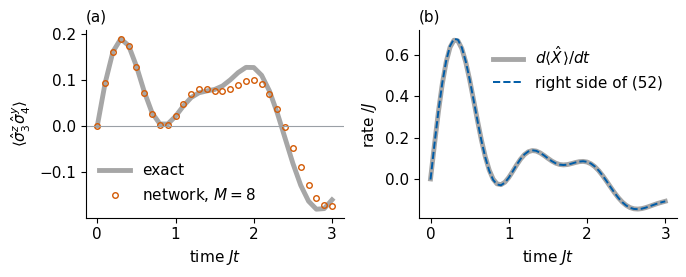

In [24]:
t_section = time.perf_counter()
def zy_local(theta, M, sigma, i):
    # equation (51): sigma_i * (-i sigma_{i+1}) * psi(s^(i+1)) / psi(s), sigma_{i+1} taken before the flip
    flipped = sigma.copy(); flipped[:, i + 1] *= -1
    ratio = np.exp(log_psi(theta, M, flipped)[0] - log_psi(theta, M, sigma)[0])
    return sigma[:, i] * (-1j * sigma[:, i + 1]) * ratio

def string_matrix(ops):
    # matrix of a Pauli string from Kronecker products, ops = {site: 2 x 2 matrix}
    return on_sites(ops)
PY = np.array([[0, -1j], [1j, 0]])
ZY_MID = string_matrix({3: PZ, 4: PY})                              # sigma^z_3 sigma^y_4
ZY_SUM = sum(string_matrix({i: PZ, i + 1: PY}) + string_matrix({i: PY, i + 1: PZ}) for i in range(N - 1))
assert np.allclose(ZY_MID.real, 0)                                  # all matrix elements are imaginary

T_ZY = T_GRID[::2]                                                  # 0, 0.1, ..., 3, where the parameters were stored
zy_net = np.array([born_probabilities(th, M_MAIN) @ zy_local(th, M_MAIN, CONF, 3) for th in r8["thetas"]])
zy_exact = np.array([np.vdot(PSI_T[2 * n], ZY_MID @ PSI_T[2 * n]) for n in range(len(T_ZY))])
# equation (52) on the exact states against the central difference of <X>(t)
rhs28 = np.array([(2 * J / N) * np.vdot(v, ZY_SUM @ v).real for v in PSI_T])
dXdt = np.gradient(X_EXACT, T_GRID, edge_order=2)
dX_fine = np.array([(np.vdot(exact_state(t + 1e-4), X_MAT @ exact_state(t + 1e-4)) - np.vdot(exact_state(t - 1e-4), X_MAT @ exact_state(t - 1e-4))).real / 2e-4 for t in T_GRID])
print(f"<sigma^z_3 sigma^y_4>: at t = 0 network {zy_net[0].real:+.1e}, exact {zy_exact[0].real:+.1e};  "
      f"largest |exact| for t <= 3 {np.max(np.abs(zy_exact.real)):.3f}")
print(f"largest |network - exact| {np.max(np.abs(zy_net - zy_exact)):.4f};  largest imaginary part of the averages {np.max(np.abs(zy_net.imag)):.1e}")
print(f"equation (52) against the finite difference of <X>(t) with step 1e-4: largest difference {np.max(np.abs(rhs28 - dX_fine)):.1e}")

# --- figure (drawing code may be skipped) ---
def draw_zy_a(ax):
    ax.plot(T_ZY, zy_exact.real, color=COL["exact"], lw=3.5, alpha=0.35, label="exact")
    ax.plot(T_ZY, zy_net.real, "o", ms=4, mfc="none", color=COL["sums"], label=f"network, $M={M_MAIN}$")
    ax.axhline(0, color=COL["grey"], lw=0.8)
    ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"$\langle\hat\sigma^z_3\hat\sigma^y_4\rangle$"); ax.legend(frameon=False)
def draw_zy_b(ax):
    ax.plot(T_GRID, dXdt, color=COL["exact"], lw=3.5, alpha=0.35, label=r"$d\langle\hat X\rangle/dt$")
    ax.plot(T_GRID, rhs28, color=COL["netket"], lw=1.4, ls="--", label="right side of (52)")
    ax.set_xlabel(r"time $Jt$"); ax.set_ylabel(r"rate $/J$"); ax.legend(frameon=False)
panels("fig_lab088_sigma_zy", [draw_zy_a, draw_zy_b])
TIMES["15 phases"] = time.perf_counter() - t_section

Panel (a) shows that $\langle\hat\sigma^z_3\hat\sigma^y_4\rangle$ is zero at $t=0$, where the state is real, rises to $0.19$ near $Jt=0.3$ and changes sign near $Jt=2.4$. The network follows the exact curve, with a largest deviation of $0.039$ near the end of the interval. Panel (b) shows the derivative of $\langle\hat X\rangle(t)$ beside the right side of equation (52) evaluated with the exact states, and the two agree to the accuracy of the finite difference. For a real wave function every term of equation (52) vanishes, so the magnetisation along the field can change only after the amplitudes have acquired phases.

## 16. Summary

Imaginary-time evolution multiplies the coefficient of every eigenstate by $e^{-\mathcal E_n\tau}$, so all excited states die out relative to the ground state, each with a rate set by its gap. It reaches the ground state only if the start overlaps with it, and only within the symmetry sector of the start, which is why the network started with zero biases. Written for one amplitude, a small step multiplies $\psi(\mathbf s)$ by $1-d\tau\,E_{\rm loc}(\mathbf s)$, and a real-time step by $1-i\,dt\,E_{\rm loc}(\mathbf s)$. Subtracting the energy from the local energy keeps the norm fixed.

A network changes all amplitudes together through its parameters, and a parameter velocity $\dot{\boldsymbol\theta}$ multiplies $\psi(\mathbf s)$ by $1+dt\sum_k\dot\theta_kO_k(\mathbf s)$. The velocity follows from a least-squares fit, weighted with the Born probabilities, of $\sum_k\dot\theta_k\,\delta O_k(\mathbf s)$ to $-i\,\delta E_{\rm loc}(\mathbf s)$ in real time or to $-\delta E_{\rm loc}(\mathbf s)$ in imaginary time, and for a single parameter it is the slope of a linear regression. Its normal equations contain the covariance matrix $S$ of the logarithmic derivatives and the force $f$, the covariance of the logarithmic derivatives with the local energy, which for real parameters and a real wave function is half the gradient of the energy. The Euler step of imaginary time is stochastic reconfiguration, gradient descent with the gradient multiplied by $S^{-1}$. The shift $\epsilon\lambda_{\max}$ of $S$, a penalty on the squared length of the velocity, keeps the velocity finite, and because $(S+\epsilon\lambda_{\max}\mathbb 1)^{-1}$ is Hermitian, the real-time evolution with exact sums conserves the energy with the shift as it does without it.

With exact sums over the 256 configurations, the network with eight hidden units reached the ground state at $g_i$ and followed $\langle\hat X\rangle(t)$ after the change of the field closely up to $Jt=3$, and sixteen hidden units improved both. With Metropolis snapshots, two effects raised the errors, the larger shift that the noisy and rank-deficient $S$ of the snapshots requires and the sampling noise itself. NetKet reproduced the exact-sum evolution and reached the same accuracy with snapshots. Cutting the chain and reshaping its amplitudes into a matrix gives the Schmidt weights and the entropies of the cut, and a network carries at most one bit across a cut for every hidden unit connected to both sides, because each such unit at most doubles the Schmidt rank. In the swap ratio of the network the visible biases cancel and only these crossing units remain. From snapshots, the swap estimate of the Rényi-2 entropy agreed with the entropy of the network within its statistical errors, and the estimate of the von Neumann entropy from $\hat\rho_A$ had a systematic error for few snapshots, which fell below the scatter for the largest numbers of snapshots.

## 17. Exercises

1. Start the two-spin evolution of Section 3 from $\psi(0)=(1,0,0,-1)/\sqrt2$. Compute its weights on the four eigenstates, follow it in imaginary time and explain which state it reaches.
2. Minimise equation (17) over the constant $\kappa$ for $N_{\rm p}$ complex parameters and show that the result is equation (20). Then derive the imaginary-time form of equation (21) from the target $-E_{\rm loc}(\mathbf s)+\kappa$.
3. Replace the Runge–Kutta step in the imaginary-time part of `evolve` by the Euler step (22) with $d\tau=0.01/J$, using exact sums and $M=8$, and compare the energy error at $\tau=6/J$ with Section 9.
4. Repeat the exact-sum evolution with $M=8$ for the shifts $\epsilon=10^{-4}$ and $\epsilon=10^{-8}$ and compare the infidelity at $t=3/J$ and the energy drift with the run for $\epsilon=10^{-6}$.
5. Run the sampled evolution of Section 10 with 300 chains in place of 1000 and compare the largest deviation of $\langle\hat X\rangle$ from the exact curve.
6. Repeat Section 14 for the cut after $\ell=2$ sites and compare the three estimates with the exact entropies.

## References

[1] G. Carleo and M. Troyer, Solving the quantum many-body problem with artificial neural networks, Science **355**, 602 (2017), doi:10.1126/science.aag2302.

[2] A. D. McLachlan, A variational solution of the time-dependent Schrödinger equation, Mol. Phys. **8**, 39 (1964), doi:10.1080/00268976400100041.

[3] G. Carleo, F. Becca, M. Schiró and M. Fabrizio, Localization and glassy dynamics of many-body quantum systems, Sci. Rep. **2**, 243 (2012), doi:10.1038/srep00243.

[4] X. Yuan, S. Endo, Q. Zhao, Y. Li and S. C. Benjamin, Theory of variational quantum simulation, Quantum **3**, 191 (2019), doi:10.22331/q--191.

[5] S. Sorella, Green function Monte Carlo with stochastic reconfiguration, Phys. Rev. Lett. **80**, 4558 (1998), doi:10.1103/PhysRevLett.80.4558.

[6] F. Becca and S. Sorella, *Quantum Monte Carlo Approaches for Correlated Systems* (Cambridge University Press, 2017), doi:10.1017/9781316417041.

[7] M. Schmitt and M. Heyl, Quantum many-body dynamics in two dimensions with artificial neural networks, Phys. Rev. Lett. **125**, 100503 (2020), doi:10.1103/PhysRevLett.125.100503.

[8] F. Vicentini, D. Hofmann, A. Szabó, D. Wu, C. Roth, C. Giuliani, G. Pescia, J. Nys, V. Vargas-Calderón, N. Astrakhantsev and G. Carleo, NetKet 3: machine learning toolbox for many-body quantum systems, SciPost Phys. Codebases **7** (2022), doi:10.21468/SciPostPhysCodeb.7.

[9] M. B. Hastings, I. González, A. B. Kallin and R. G. Melko, Measuring Renyi entanglement entropy in quantum Monte Carlo simulations, Phys. Rev. Lett. **104**, 157201 (2010), doi:10.1103/PhysRevLett.104.157201.

[10] P. Pfeuty, The one-dimensional Ising model with a transverse field, Ann. Phys. **57**, 79 (1970), doi:10.1016/0003-4916(70)90270-8.

[11] N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller and E. Teller, Equation of state calculations by fast computing machines, J. Chem. Phys. **21**, 1087 (1953), doi:10.1063/1.1699114.

[12] C. Runge, Ueber die numerische Auflösung von Differentialgleichungen, Math. Ann. **46**, 167 (1895), doi:10.1007/BF01446807.

[13] P. Virtanen *et al.*, SciPy 1.0: fundamental algorithms for scientific computing in Python, Nat. Methods **17**, 261 (2020), doi:10.1038/s41592-019-0686-2.

[14] C. R. Harris *et al.*, Array programming with NumPy, Nature **585**, 357 (2020), doi:10.1038/s41586-020-2649-2.

[15] D.-L. Deng, X. Li and S. Das Sarma, Quantum entanglement in neural network states, Phys. Rev. X **7**, 021021 (2017), doi:10.1103/PhysRevX.7.021021.

The last cell compares the runs with a separate NumPy script of the same protocol and prints the runtimes of all sections. All runs agree with that reference calculation to $10^{-7}$ or better in relative terms, except the real-time parts of the two runs with $M=16$, with the steps $dt$ and $dt/2$, whose infidelities at $Jt=3$ differ from the reference in the second significant digit. The cause of this difference was not established. When `SAVE_RESULTS` is `True`, the cell also saves every figure, writes every number quoted in the text to a file of LaTeX macros and writes the results file.

In [25]:
# Bookkeeping: comparison with the reference calculation and runtimes; files only if SAVE_RESULTS is True.
def run_summary(r):
    out = dict(gs_rel_err=float(r["gs_rel_err"]), init_infid=float(r["infid"][0]), max_abs_dx=float(np.max(np.abs(r["X_net"] - X_EXACT))),
               infid_T=float(r["infid"][-1]), energy_drift=float(np.max(np.abs(r["E_real"] - r["E_real"][0]))),
               imag_part_max_after_imag=float(r["imag_part_max"]), max_residual=float(np.max(r["residual"])), seconds=float(r["seconds"]))
    if "acceptance" in r:
        out.update(acceptance=float(r["acceptance"]), max_abs_dx_estimated=float(np.max(np.abs(r["X_est"] - X_EXACT[:-1]))))
    return out
KIND = {"sums": "exact", "snap": "sampled", "sums_shift": "exactsameshift"}
runs_json = {f"{KIND[kind]}_M{M}": run_summary(r) for (kind, M), r in RUNS.items()}
runs_json["exacthalfdt_M16"] = dict(HALF_DT_M16)
comparison, ref_file = {}, Path("data") / "tvmc_quench_summary.json"
if ref_file.exists():                                    # reference calculation of the same protocol (separate NumPy script)
    ref = json.loads(ref_file.read_text())["runs"]
    print("relative difference from the reference calculation:")
    for key, ours in runs_json.items():
        if key in ref:
            comparison[key] = {q: dict(this_notebook=ours[q], reference=ref[key][q]) for q in
                               ("gs_rel_err", "init_infid", "max_abs_dx", "infid_T", "max_abs_dx_estimated") if q in ref[key] and q in ours}
            print(f"  {key}: " + ", ".join(f"{q} {abs(v['this_notebook'] - v['reference']) / abs(v['reference']):.1e}" for q, v in comparison[key].items()))
TOTAL_SECONDS = time.perf_counter() - started
for k, v in TIMES.items():
    print(f"section {k}: {v:.1f} s")
print(f"core route {CORE_SECONDS:.0f} s, total {TOTAL_SECONDS:.0f} s")

if SAVE_RESULTS:
    FIG, RES = Path("figures"), Path("classroom_results"); FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
    SLIDE_RC = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12}
    def save(fig, name):
        fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150); plt.close(fig)
    def single(draw, name):                              # one panel at 4.6 x 3.1 in with 12.5 pt fonts (slides)
        with plt.rc_context(SLIDE_RC):
            fig, ax = plt.subplots(figsize=(4.6, 3.1)); draw(ax); fig.tight_layout(); save(fig, name)
    for name, draws in FIGURES:                          # notes: panels side by side at 7.0 x 2.9 in; slides: every panel alone
        if len(draws) == 1:
            single(draws[0], name); continue
        fig, axes = plt.subplots(1, len(draws), figsize=(7.0, 2.9))
        for ax, draw, lab in zip(axes, draws, "abcdef"):
            draw(ax); ax.set_title(f"({lab})", loc="left", fontsize=11)
        fig.tight_layout(); save(fig, name)
        for draw, lab in zip(draws, "abcdef"):
            single(draw, f"{name}_{lab}")
    def sci(x, digits=1):                                # LaTeX scientific notation, e.g. 2.1\times10^{-3}
        m, e = f"{x:.{digits}e}".split("e"); return f"{m}\\times10^{{{int(e)}}}"
    dx = lambda r: f"{np.max(np.abs(r['X_net'] - X_EXACT)):.3f}"
    drift = lambda r: np.max(np.abs(r["E_real"] - r["E_real"][0]))
    NUMBERS = dict(EzeroI=f"{E0_I:.4f}", GapI=sci(EV_I[1] - E0_I), XZero=f"{X_EXACT[0]:.3f}", XMin=f"{X_EXACT.min():.3f}", XMax=f"{X_EXACT.max():.3f}",
        EAfter=f"{E_AFTER:.4f}", WeightMaxF=f"{W_F.max():.2f}", EigenstatesNinetyNine=str(N99), TwoGap=f"{DELTA2:.3f}",
        TwoRatioFour=f"{AMP2[-1, 1] / AMP2[-1, 0]:.3f}", NormSubMaxDev=sci(np.max(np.abs(NORM_SUB2 - 1))), NormExactFour=sci(NORM_EXACT2[-1]),
        ImagExactErrSix=sci((E_IMAG_EXACT[-1] - E0_I) / abs(E0_I)), ImagExactInfSix=sci(IMAG_EXACT["even"]["infid"][-1]),
        ImagExactInfSixB=sci(IMAG_EXACT["random b"]["infid"][-1]), ResidImag=sci(resid_imag), ResidReal=sci(resid_real),
        SCondition=sci(lam0[0] / lam0[-1]), SRCosine=f"{cosine:.2f}",
        SumsGsErr=sci(r8["gs_rel_err"]), SumsInfZero=sci(r8["infid"][0]), SumsDx=dx(r8), SumsInfT=sci(r8["infid"][-1]),
        SumsSeconds=f"{r8['seconds']:.0f}", SumsDrift=sci(drift(r8)), RandomBInf=sci(r8b["inf_imag"][-1]), RandomBGsErr=sci(r8b["gs_rel_err"]),
        SameShiftGsErr=sci(r8e["gs_rel_err"]), SameShiftInfT=sci(r8e["infid"][-1]), SameShiftDx=dx(r8e),
        ShiftFactor=f"{r8e['gs_rel_err'] / r8['gs_rel_err']:.0f}", SamplingFactor=f"{rs['gs_rel_err'] / r8e['gs_rel_err']:.1f}",
        SnapGsErr=sci(rs["gs_rel_err"]), SnapDx=dx(rs), SnapDxEst=f"{dx_est:.3f}", SnapInfT=sci(rs["infid"][-1]), SnapDistinct=str(n_distinct),
        SnapRank=str(int(np.sum(lam_s > 1e-12 * lam_s[-1]))), SnapAcceptance=f"{rs['acceptance']:.2f}", SnapSeconds=f"{rs['seconds']:.0f}",
        DriftDt=sci(drift_dt), DriftHalf=sci(drift_half), DriftRatio=f"{drift_dt / drift_half:.0f}",
        ZYMax=f"{np.max(np.abs(zy_exact.real)):.2f}", ZYDiff=sci(np.max(np.abs(zy_net - zy_exact))),
        VnExactT=f"{ENT['vn_exact'][-1]:.2f}", VnNetT=f"{ENT['vn_net'][-1]:.2f}", STwoExactT=f"{ENT['s2_exact'][-1]:.2f}",
        STwoNetT=f"{ENT['s2_net'][-1]:.2f}", CoreSeconds=f"{CORE_SECONDS:.0f}", TotalSeconds=f"{TOTAL_SECONDS:.0f}")
    for M, word in ((4, "Four"), (8, "Eight"), (16, "Sixteen")):    # real-time numbers of M = 16 to one significant digit
        r = RUNS["sums", M]
        NUMBERS.update({f"GsErrM{word}": sci(r["gs_rel_err"]), f"DxM{word}": dx(r),
                        f"InfTM{word}": sci(r["infid"][-1], 0 if M == 16 else 1)})
    if HAVE_NETKET:
        NUMBERS.update(NkSumsGsErr=sci(NK["sums"]["gs_rel_err"]), NkSumsInfT=sci(NK["sums"]["infid"][-1]),
                       NkSumsDiff=sci(np.max(np.abs(NK["sums"]["X_net"] - r8["X_net"]))), NkSumsSeconds=f"{NK['sums']['seconds']:.0f}",
                       NkSnapGsErr=sci(NK["snap"]["gs_rel_err"]), NkSnapDx=dx(NK["snap"]), NkSnapInfT=sci(NK["snap"]["infid"][-1]),
                       NkSnapSeconds=f"{NK['snap']['seconds']:.0f}")
    summary = dict(
        experiment="RBM wave function with complex parameters, open transverse-field Ising chain N = 8: imaginary-time evolution at "
                   "g_i = 0.5 J and real-time evolution after a sudden change to g_f = J by the time-dependent variational principle "
                   "(S theta_dot = -i f, -f), RK4, averages as exact sums or as Metropolis snapshots; exact diagonalisation as reference",
        settings=dict(N=N, J=J, g_i=G_I, g_f=G_F, dtau=DTAU, tau_max=TAU_MAX, dt=DT, t_max=T_MAX, eps_exact_sums=ExactSums.eps,
                      eps_snapshots=Snapshots.eps, regularisation="(S + eps lambda_max 1) theta_dot = -i f", chains=1000, sweeps_per_evaluation=2,
                      warm_up_sweeps=100, seed_weights=1, seed_snapshots=101, initial_width=0.1, initial_biases="a = b = 0",
                      random_b_start="same W, b drawn after W", M_exact_sums=list(M_LIST), M_snapshots=M_MAIN),
        exact=dict(E0_g_i=float(E0_I), gap_g_i=float(EV_I[1] - E0_I), X_t0=float(X_EXACT[0]), energy_after_change=E_AFTER,
                   largest_weight_on_eigenstates_g_f=float(W_F.max()), eigenstates_for_099_weight=N99),
        checks=dict(dlogpsi_vs_finite_difference=float(err_O), Eloc_vs_Hpsi=float(err_E), Xloc_vs_Xpsi=float(err_X),
                    ridge_vs_lstsq=float(err_ridge), gradient_vs_2f=float(err_grad), normal_equations=float(normal_eq_error),
                    dEdt_real_time_t3=float(info_late["dEdt"]), dEdt_terms_t3=float(info_late["dEdt_scale"])),
        two_spins=dict(eigenvalues=E2.tolist(), weights_tau0=WEIGHT2[0].tolist(), ratio_tau4=float(AMP2[-1, 1] / AMP2[-1, 0]),
                       norm_exact_tau4=float(NORM_EXACT2[-1]), norm_euler_plain_tau4=float(NORM_PLAIN2[-1]),
                       norm_euler_subtracted_max_deviation=float(np.max(np.abs(NORM_SUB2 - 1))),
                       one_parameter_fit=dict(var_O=float(var1), cov_O_Eloc=float(cov1), theta_dot=float(-cov1 / var1))),
        imaginary_time_exact_from_network_start=dict(rel_err_tau6=float((E_IMAG_EXACT[-1] - E0_I) / abs(E0_I)),
                                                     infid_tau6_even_start=float(IMAG_EXACT["even"]["infid"][-1]),
                                                     infid_tau6_random_b_start=float(IMAG_EXACT["random b"]["infid"][-1])),
        random_b_start_exact_sums=dict(gs_rel_err=float(r8b["gs_rel_err"]), infid_tau6=float(r8b["inf_imag"][-1]), even_start_infid_tau6=float(r8["inf_imag"][-1])),
        gs_err_vs_tau={f"{KIND[kind]}_M{M}": {str(tau): float(gs_err_at(r, tau)) for tau in (2.0, 2.5, 3.0, 4.0, 5.0, 5.5, 6.0)} for (kind, M), r in RUNS.items()},
        sigma_z3_sigma_y4=dict(times=T_ZY.tolist(), exact=zy_exact.real.tolist(), network=zy_net.real.tolist(),
                               eq36_max_difference=float(np.max(np.abs(rhs28 - dX_fine)))),
        energy_drift_M16=dict(dt=DT, drift=drift_dt, dt_half=DT / 2, drift_half=drift_half),
        snapshot_S_at_ground_state=dict(distinct_configurations=int(n_distinct), rank=int(np.sum(lam_s > 1e-12 * lam_s[-1])), parameters=len(lam_s)),
        first_step_fit=dict(relative_residual_imag=float(resid_imag), relative_residual_real=float(resid_real), sr_cosine=float(cosine),
                            S_eigenvalue_ratio=float(lam0[0] / lam0[-1])),
        runs=runs_json, reference_comparison=comparison,
        netket=({k: dict(gs_rel_err=float(v["gs_rel_err"]), max_abs_dx=float(np.max(np.abs(v["X_net"] - X_EXACT))),
                         infid_T=float(v["infid"][-1]), seconds=float(v["seconds"])) for k, v in NK.items()}
                | dict(version=nk.__version__, jax_version=jax.__version__, flax_version=flax.__version__,
                       model="nk.models.RBM" if USE_NK_RBM else "apply_fun (equation 10)", sigma_z0_ours=sz0_ours, sigma_z0_netket=sz0_nk,
                       max_abs_dx_netket_vs_ours_exact_sums=float(np.max(np.abs(NK["sums"]["X_net"] - r8["X_net"]))))
                if HAVE_NETKET else "not available"),
        entanglement=dict(cut=CUT, times=T_ENT.tolist(), **{k: v.tolist() for k, v in ENT.items()},
                          bias_snapshots=list(N_SNAP), bias_vn=BIAS["vn"].tolist(), bias_s2=BIAS["s2"].tolist(), network_t3=dict(vn=S_vn_c, s2=S2_c)),
        seconds=dict(**{k: float(v) for k, v in TIMES.items()}, core_route=float(CORE_SECONDS), total=float(TOTAL_SECONDS)))
    (RES / "lab088_results.json").write_text(json.dumps(summary, indent=1))
    with open(FIG / "nb_numbers_lab088.tex", "w") as fh:
        fh.write("% generated by Lab_088_NQS_ground_state_and_time_evolution.ipynb (Lecture 16), do not edit\n")
        for k, v in NUMBERS.items():
            fh.write(f"\\providecommand{{\\labeightyeight{k}}}{{{v}}}\n")
    print(f"written: {len(FIGURES)} figures in figures/, figures/nb_numbers_lab088.tex, classroom_results/lab088_results.json")

relative difference from the reference calculation:
  exact_M8: gs_rel_err 2.0e-10, init_infid 1.2e-10, max_abs_dx 1.6e-08, infid_T 3.1e-08
  sampled_M8: gs_rel_err 3.4e-12, init_infid 7.6e-12, max_abs_dx 1.1e-13, infid_T 3.8e-14, max_abs_dx_estimated 7.5e-14
  exactsameshift_M8: gs_rel_err 3.0e-11, init_infid 9.3e-11, max_abs_dx 1.6e-12, infid_T 2.1e-11
  exact_M4: gs_rel_err 4.5e-12, init_infid 5.8e-12, max_abs_dx 4.3e-12, infid_T 4.5e-13
  exact_M16: gs_rel_err 1.5e-09, init_infid 1.1e-09, max_abs_dx 1.6e-04, infid_T 3.5e-02
  exacthalfdt_M16: max_abs_dx 1.6e-04, infid_T 1.3e-02
section 2 exact diagonalisation: 0.6 s
section 3 imaginary time on two spins: 0.6 s
section 4 network and exact imaginary time: 0.3 s
section 6-8 fit, stochastic reconfiguration, solver: 0.3 s
section 9 exact sums, M = 8: 19.2 s
section 10 snapshots, M = 8: 99.5 s
section 11 entanglement of a cut: 0.3 s
section 12 hidden units: 73.8 s
section 13 NetKet: 92.8 s
section 14 entanglement: 128.9 s
section 15 phas